In [188]:
import pandas as pd
import numpy as np
import  glob 
import os
from tqdm import tqdm

def pairtime_frames(frame, experiment_name):
    """Ungeordnete sichtbare Paare pro Frame: n * (n - 1) / 2.

    Berechnung separat je Aufnahme/Condition, niemals ueber Kohorten hinweg.
    Sichtbarkeit erfordert visible == 1; fehlendes Tracking zaehlt nicht als sichtbar.
    """
    columns = frame.columns
    selection = ((columns.get_level_values("name") == experiment_name)
                 & (columns.get_level_values("metrics") == "visible"))
    visibility = frame.loc[:, selection]
    if visibility.shape[1] == 0:
        raise ValueError(f"Keine visible-Metriken fuer {experiment_name}")
    if visibility.columns.get_level_values("individuals").duplicated().any():
        raise ValueError("Mehrere visible-Spalten pro Maus; Pairtime waere mehrdeutig.")
    n_visible = np.count_nonzero(visibility.to_numpy() == 1, axis=1)
    return n_visible * (n_visible - 1) // 2

from pathlib import Path

PLOT_DIR = Path(r"Z:\n2023_odor_related_behavior\2026_sick_behavior\plots")


def save_plot_svg(fig, filename):
    """Save the figure as SVG; create the output folder if needed."""
    import matplotlib as mpl
    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    with mpl.rc_context({"svg.fonttype": "none"}):
        fig.savefig(PLOT_DIR / filename, format="svg", bbox_inches="tight")



In [120]:
path = r"Z:\n2023_odor_related_behavior\2026_sick_behavior\raw\c4\sick\20261029_100904_904802_mice_c4_sick_stim\metric_analysis\experiment.h5"
path = r"Z:\n2023_odor_related_behavior\2026_sick_behavior\raw\c1\baseline\top1\metric_analysis\experiment.h5"

df = pd.read_hdf(path, key="metrics")
name = df.columns.get_level_values("name").unique()

metadata = name[0].split("_")
date = metadata[0]
start_time = metadata[1]
cohort = metadata[3]
day = metadata[4]
condition = metadata[5]

individuals = df.columns.get_level_values("individuals").unique()
metrics = df.columns.get_level_values("metrics").unique()

print(metrics)

median_speed = {}
mice_presence = {}
for individual in individuals:

    speed_values = df.loc[:, (name, individual, "speed")]
    median_speed[(individual, "speed")] = np.nanmedian(speed_values[speed_values > 0])

    presence = df.loc[:, (name, individual, "visible")]
    mice_presence[(individual, "visible")] = np.nansum(presence)

print(median_speed)
print(mice_presence)

Index(['mice_presence', 'mean_likelihood', 'center_x', 'center_y', 'nose_x',
       'nose_y', 'visible', 'speed', 'cumdist', 'immobile', 'immobile_starts',
       'immobile_bout_lengths', 'acceleration', 'speed_event_count',
       'speed_event_index', 'posture_compactness', 'body_length',
       'orientations', 'center_traj_startidx', 'center_traj_endidx',
       'thetas [stepsize 10 frames]', 'arc_chord', 'face_inv',
       'face_inv_starts', 'face_inv_stops_exclusive', 'face_inv_bout_lengths',
       'face_inv_bout_complete', 'anogenital_inv', 'anogenital_inv_starts',
       'anogenital_inv_stops_exclusive', 'anogenital_inv_bout_lengths',
       'anogenital_inv_bout_complete', 'body_inv', 'body_inv_starts',
       'body_inv_stops_exclusive', 'body_inv_bout_lengths',
       'body_inv_bout_complete'],
      dtype='str', name='metrics')
{('mouse1', 'speed'): 5.331123670580787, ('mouse2', 'speed'): 5.491837508358742, ('mouse3', 'speed'): 5.23784621613625}
{('mouse1', 'visible'): 122668,

In [121]:
cohorts = ["c1", "c2", "c3", "c4"]
days = ["habituation", "baseline", "sick"]
condition = ["stim", "home"]

folder_path = r"Z:\n2023_odor_related_behavior\2026_sick_behavior\raw"
# run through all subfolders of the folder_path to find every experiment.h5 file
experiment_files = glob.glob(os.path.join(folder_path, "**", "experiment.h5"), recursive=True)

print(len(experiment_files))

24


In [122]:
data_dict = {
    "c1": {
        "habituation": {
            "stim": {},
            "home": {}
            },
        "baseline": {
                    "stim": {},
                    "home": {}
            },
        "sick": {
                    "stim": {},
                    "home": {}
            }

    },
    "c2": {
            "habituation": {
                "stim": {},
                "home": {}
                },
            "baseline": {
                        "stim": {},
                        "home": {}
                },
            "sick": {
                        "stim": {},
                        "home": {}
                }
    
    },
    "c3": {
            "habituation": {
                "stim": {},
                "home": {}
                },
            "baseline": {
                        "stim": {},
                        "home": {}
                },
            "sick": {
                        "stim": {},
                        "home": {}
                }
    
    },
    "c4": {
            "habituation": {
                "stim": {},
                "home": {}
                },
            "baseline": {
                        "stim": {},
                        "home": {}
                },
            "sick": {
                        "stim": {},
                        "home": {}
                }
    
        },

}

Auffüllen des data_dicts

Social-Investigation-Raten werden auf die Pairtime der jeweiligen Aufnahme im Auswertungsfenster normiert: `n_visible * (n_visible - 1) / 2` Paarframes pro Frame, also 0, 0, 1, 3 fuer 0, 1, 2, 3 sichtbare Maeuse. Paarminuten = Summe Paarframes / FPS / 60. Der Nenner steht als `pairtime_minutes` je Maus im Dictionary, ist aber innerhalb einer Aufnahme identisch und darf nicht ueber Maeuse aufsummiert werden.

Die Schluessel `*_inv_events_per_pair_minute` geben die Ereignisse einer Maus pro Paarminute der gesamten Aufnahme an. Ohne Pairtime bleibt die Rate NaN. Untersuchungen werden gerichtet pro Maus erfasst, Pairtime zaehlt ungeordnete Paare: die Raten sind keine Interaktionswahrscheinlichkeiten. Mean/Median ueber Maeuse beschreibt den typischen individuellen Beitrag; eine Gesamtaktivitaetsrate der Gruppe wuerde stattdessen die Mausbeitraege summieren. Rohanzahlen und Bout-Dauern bleiben in ihren Originaleinheiten. Speed-Events bleiben auf individuelle Sichtbarkeit normiert.


In [123]:
from variables import FPS


def finite_median(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    return np.median(values) if values.size else np.nan


for file in tqdm(experiment_files):

    read_in_df = pd.read_hdf(file, key="metrics")

    df = read_in_df.copy()

    # erstmal nur die offene condition nehmen
    df = df[:216000]



    name = df.columns.get_level_values("name").unique()


    metadata = name[0].split("_")
    if len(metadata) == 11:
        new_metadata = []
        new_metadata.append(metadata[0]+metadata[1]+metadata[2])
        new_metadata.append(metadata[3]+metadata[4]+metadata[5])
        new_metadata.append(metadata[6])
        new_metadata.append(metadata[7])
        new_metadata.append(metadata[8])
        new_metadata.append(metadata[9])

        metadata = new_metadata

    date = metadata[0]
    start_time = metadata[1]
    cohort = metadata[3]
    day = metadata[4]
    condition = metadata[5]

    individuals = df.columns.get_level_values("individuals").unique()
    metrics = df.columns.get_level_values("metrics").unique()

    pair_minutes = np.sum(pairtime_frames(df, name[0])) / (FPS * 60)
    target = data_dict[cohort][day][condition]

    for individual in individuals:
        target[individual] = {}
        result = target[individual]
        result["pairtime_minutes"] = pair_minutes

        def metric_values(metric, full=False):
            source = read_in_df if full else df
            return source.loc[:, (name[0], individual, metric)].to_numpy(dtype=float).ravel()

        n_frames = len(df)
        visible = metric_values("visible") == 1
        visible_frames = np.count_nonzero(visible)
        visible_minutes = visible_frames / (FPS * 60)

        def per_visible_minute(count):
            return count / visible_minutes if visible_minutes > 0 else np.nan

        # fraction tracked
        result["fraction_present"] = visible_frames / n_frames if n_frames else np.nan

        # median speed (nur Bewegung, wie in der separaten Auswertung)
        speed = metric_values("speed")
        result["median_speed"] = finite_median(speed[visible & (speed > 0)])

        # median acceleration
        result["median_acceleration"] = finite_median(metric_values("acceleration")[visible])

        # total dist travelled (Originaleinheit der cumdist-Metrik: Pixel)
        cumdist = metric_values("cumdist")
        cumdist = cumdist[np.isfinite(cumdist)]
        result["total_distance"] = cumdist[-1] if cumdist.size else np.nan

        # immobile fraction normalized to time present
        immobile = metric_values("immobile") == 1
        result["immobile_fraction"] = (
            np.count_nonzero(immobile & visible) / visible_frames
            if visible_frames else np.nan
        )

        # median immobile bout length (Frames; am Fensterende abgeschnitten)
        starts = metric_values("immobile_starts", full=True)
        lengths = metric_values("immobile_bout_lengths", full=True)
        valid = np.isfinite(starts) & np.isfinite(lengths) & (starts >= 0) & (starts < n_frames)
        lengths = np.minimum(lengths[valid], n_frames - starts[valid])
        result["median_immobile_bout_length"] = finite_median(lengths)

        # speedevents normalized to minute visible
        speed_event_idx = metric_values("speed_event_index", full=True)
        speed_events = np.isfinite(speed_event_idx) & (speed_event_idx >= 0) & (speed_event_idx < n_frames)
        result["sum_speedevents"] = np.count_nonzero(speed_events)
        result["speedevents_per_visible_minute"] = per_visible_minute(result["sum_speedevents"])

        # median posture compactness
        result["median_posture_compactness"] = finite_median(metric_values("posture_compactness")[visible])

        # median body length
        result["median_body_length"] = finite_median(metric_values("body_length")[visible])

        # number of trajectories + median trajectory length (Frames, Endindex inklusive)
        starts = metric_values("center_traj_startidx", full=True)
        ends = metric_values("center_traj_endidx", full=True)
        valid = np.isfinite(starts) & np.isfinite(ends) & (starts >= 0) & (starts < n_frames) & (ends >= starts)
        lengths = np.minimum(ends[valid], n_frames - 1) - starts[valid] + 1
        result["number_of_trajectories"] = np.count_nonzero(valid)
        result["median_trajectory_length"] = finite_median(lengths)

        # number of face, body and anogenital investigation events normalized to pairtime
        # Raten pro Paarminute der Aufnahme; beobachtete Ereignisse inklusive unvollstaendiger Bouts.
        for investigation in ("face_inv", "body_inv", "anogenital_inv"):
            starts = metric_values(investigation + "_starts", full=True)
            stops = metric_values(investigation + "_stops_exclusive", full=True)
            valid = np.isfinite(starts) & np.isfinite(stops) & (starts >= 0) & (starts < n_frames) & (stops > starts)
            count = np.count_nonzero(valid)
            result[investigation + "_event_count"] = count
            result[investigation + "_events_per_pair_minute"] = count / pair_minutes if pair_minutes > 0 else np.nan

            # median face, body and anogenital investigation bout length (Frames)
            # Nur vollstaendige Bouts, die komplett im Auswertungsfenster liegen.
            complete = metric_values(investigation + "_bout_complete", full=True) == 1
            lengths = metric_values(investigation + "_bout_lengths", full=True)
            complete_in_window = valid & complete & (stops <= n_frames)
            result["median_" + investigation + "_bout_length"] = finite_median(lengths[complete_in_window])


100%|██████████| 24/24 [01:36<00:00,  4.02s/it]


In [124]:
print(data_dict)

{'c1': {'habituation': {'stim': {'mouse1': {'pairtime_minutes': 4.348888888888889, 'fraction_present': 0.34675743006299486, 'median_speed': 5.28992833048496, 'median_acceleration': 0.0, 'total_distance': 88854.7104532297, 'immobile_fraction': 0.3736329108131607, 'median_immobile_bout_length': 17.0, 'sum_speedevents': 2, 'speedevents_per_visible_minute': 0.16473710703335925, 'median_posture_compactness': 81.99865287667662, 'median_body_length': 306.1554434436928, 'number_of_trajectories': 29, 'median_trajectory_length': 399.0, 'face_inv_event_count': 18, 'face_inv_events_per_pair_minute': 4.1389882473173225, 'median_face_inv_bout_length': 19.0, 'body_inv_event_count': 4, 'body_inv_events_per_pair_minute': 0.919775166070516, 'median_body_inv_bout_length': 32.0, 'anogenital_inv_event_count': 3, 'anogenital_inv_events_per_pair_minute': 0.689831374552887, 'median_anogenital_inv_bout_length': 17.0}, 'mouse2': {'pairtime_minutes': 4.348888888888889, 'fraction_present': 0.12846511480300218, 'm

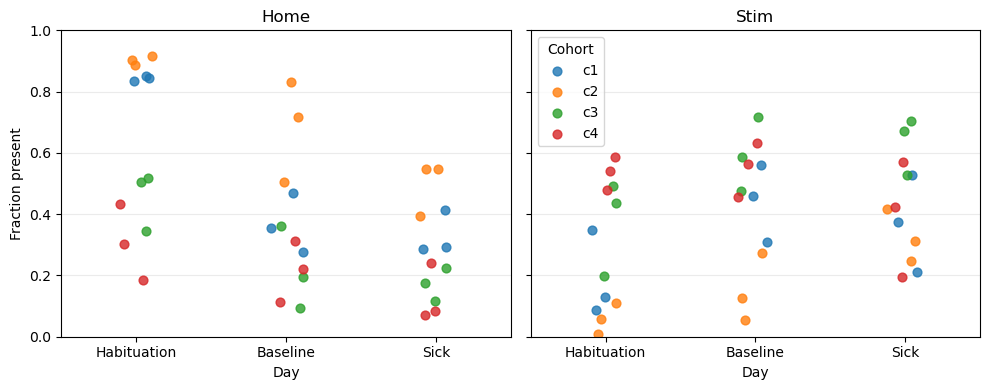

In [189]:
import matplotlib.pyplot as plt
import numpy as np


def plot_fraction_present(data_dict):
    days = ["habituation", "baseline", "sick"]
    conditions = ["home", "stim"]
    colors = plt.get_cmap("tab10")
    rng = np.random.default_rng(42)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

    for ax, condition in zip(axes, conditions):
        for cohort_idx, (cohort, cohort_data) in enumerate(data_dict.items()):
            x_values, y_values = [], []

            for day_idx, day in enumerate(days):
                mice = cohort_data.get(day, {}).get(condition, {})

                for metrics in mice.values():
                    value = metrics.get("fraction_present", np.nan)
                    if value is not None and np.isfinite(value):
                        # Kleine Streuung, damit Punkte weniger überlappen.
                        x_values.append(day_idx + rng.uniform(-0.12, 0.12))
                        y_values.append(value)

            ax.scatter(
                x_values,
                y_values,
                color=colors(cohort_idx % 10),
                label=cohort,
                alpha=0.8,
                s=40,
            )

        ax.set_title(condition.capitalize())
        ax.set_xticks(range(len(days)), [day.capitalize() for day in days])
        ax.set_xlim(-0.5, 2.5)
        ax.set_ylim(0, 1)
        ax.set_xlabel("Day")
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Fraction present")
    axes[1].legend(title="Cohort")

    fig.tight_layout()
    plt.show()
    return fig, axes


fig, axes = plot_fraction_present(data_dict)
save_plot_svg(fig, 'fraction_present_scatter_by_cohort_home_stim_0_2h.svg')


In [126]:
median_speed = {}
for individual in individuals:

    speed_values = df.loc[:, (name, individual, "speed")]
    median_speed[(individual, "speed")] = np.nanmedian(speed_values[speed_values > 0])

print(median_speed)

        
    

{('mouse1', 'speed'): 6.05079744394841, ('mouse2', 'speed'): 7.46449001348101, ('mouse3', 'speed'): 6.320394073711926}


In [127]:
face_inv = {}

for individual in individuals:
    face_inv_values = df.loc[:, (name, individual, "face_inv")]
    face_inv[(individual, "face_investigation")] = np.nansum(face_inv_values)

print(face_inv)

{('mouse1', 'face_investigation'): 949.0, ('mouse2', 'face_investigation'): 628.0, ('mouse3', 'face_investigation'): 633.0}


## Metriken nach Versuchstag und Bedingung

Je Punkt eine Maus; Farbe = Kohorte, schwarzer durchgezogener Strich = Median, schwarzer gestrichelter Strich = Mean (arithmetischer Mittelwert) aller dargestellten Maeuse. n zaehlt gueltige Mauswerte, keine unabhaengigen Kohorten. Fehlende Werte werden ausgelassen. Rohanzahlen und Gesamtstrecken sind nicht auf Beobachtungsdauer normiert. Die folgenden Plot-Kacheln verwenden das bereits befuellte `data_dict`; zuerst die gemeinsame Hilfsfunktion ausfuehren.


In [190]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator


def plot_metric(data_dict, metric, title, ylabel, fraction=False, count=False, signed=False, conditions=("stim", "home")):
    days = ["habituation", "baseline", "sick"]
    cohorts = sorted(data_dict)
    colors = {cohort: plt.get_cmap("tab10")(i % 10) for i, cohort in enumerate(cohorts)}
    offsets = dict(zip(cohorts, np.linspace(-0.23, 0.23, len(cohorts))))
    fig, axes = plt.subplots(1, len(conditions), figsize=(5.5 * len(conditions), 4.8), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, condition in zip(axes, conditions):
        sample_sizes = []
        for day_idx, day in enumerate(days):
            day_values = []
            for cohort in cohorts:
                mice = data_dict[cohort].get(day, {}).get(condition, {})
                mouse_names = sorted(mice)
                jitter = np.linspace(-0.035, 0.035, len(mouse_names)) if len(mouse_names) > 1 else [0.0]
                for mouse_idx, mouse in enumerate(mouse_names):
                    value = mice[mouse].get(metric, np.nan)
                    if value is None or not np.isfinite(value):
                        continue
                    day_values.append(value)
                    ax.scatter(day_idx + offsets[cohort] + jitter[mouse_idx], value,
                               color=colors[cohort], s=42, alpha=0.85,
                               edgecolor="white", linewidth=0.5, zorder=3)
            sample_sizes.append(len(day_values))
            if day_values:
                ax.hlines(np.median(day_values), day_idx - 0.32, day_idx + 0.32,
                          color="black", linewidth=2, zorder=4)
                ax.hlines(np.mean(day_values), day_idx - 0.32, day_idx + 0.32,
                          color="black", linewidth=2, linestyles="--", zorder=5)
        ax.set_title(condition.capitalize())
        ax.set_xticks(range(3), [f"{day.capitalize()}\n(n={size})" for day, size in zip(days, sample_sizes)])
        ax.set_xlim(-0.55, 2.55)
        ax.set_xlabel("Experimental day")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        if not any(sample_sizes):
            ax.text(0.5, 0.5, "No valid values", transform=ax.transAxes, ha="center")

    if fraction:
        axes[0].set_ylim(0, 1)
    elif signed:
        low, high = axes[0].get_ylim()
        extent = max(abs(low), abs(high), 0.01)
        axes[0].set_ylim(-extent, extent)
        for ax in axes:
            ax.axhline(0, color="grey", linewidth=0.8, zorder=1)
    else:
        axes[0].set_ylim(bottom=0)
    if count:
        axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    axes[0].set_ylabel(ylabel)
    handles = [Line2D([], [], marker="o", linestyle="", color=colors[c], label=c) for c in cohorts]
    handles.append(Line2D([], [], color="black", linewidth=2, label="Median across mice"))
    handles.append(Line2D([], [], color="black", linewidth=2, linestyle="--", label="Mean across mice"))
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 6 if len(conditions) > 1 else 3), frameon=False)
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0.16 if len(conditions) == 1 else 0.1, 1, 0.95))
    plt.show()
    return fig, axes


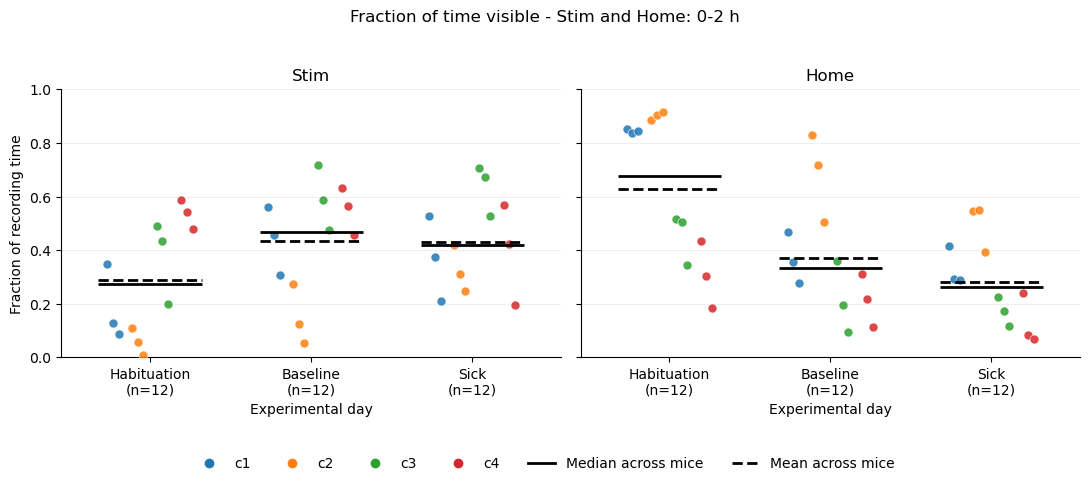

In [191]:
fig, axes = plot_metric(data_dict, 'fraction_present', 'Fraction of time visible - Stim and Home: 0-2 h', 'Fraction of recording time', fraction=True)
save_plot_svg(fig, 'fraction_present_scatter_stim_home_0_2h.svg')


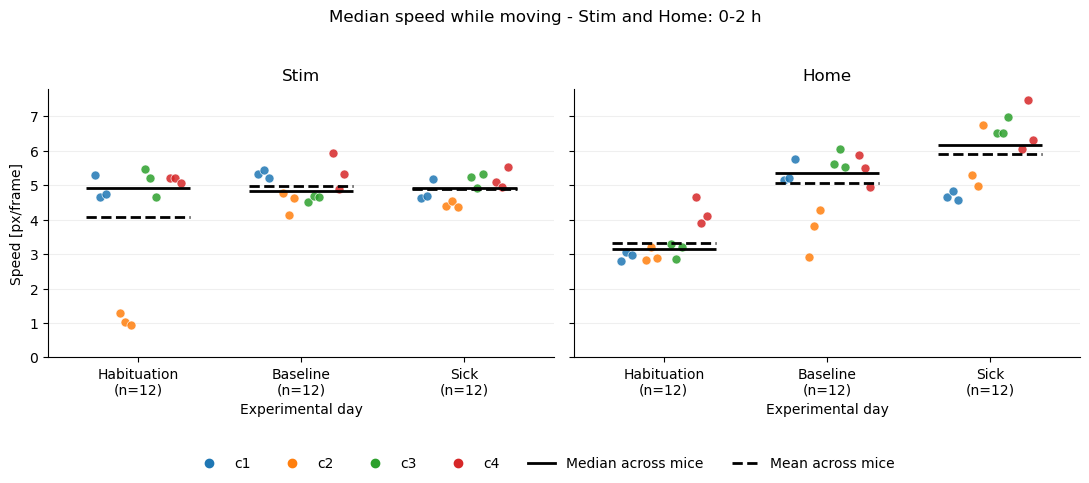

In [192]:
fig, axes = plot_metric(data_dict, 'median_speed', 'Median speed while moving - Stim and Home: 0-2 h', 'Speed [px/frame]')
save_plot_svg(fig, 'median_speed_scatter_stim_home_0_2h.svg')


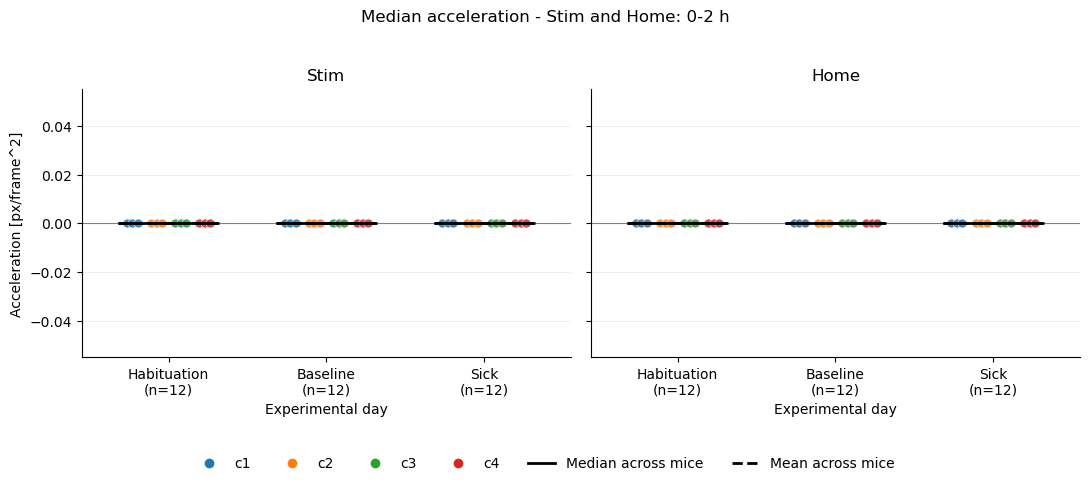

In [193]:
fig, axes = plot_metric(data_dict, 'median_acceleration', 'Median acceleration - Stim and Home: 0-2 h', 'Acceleration [px/frame^2]', signed=True)
save_plot_svg(fig, 'median_acceleration_scatter_stim_home_0_2h.svg')


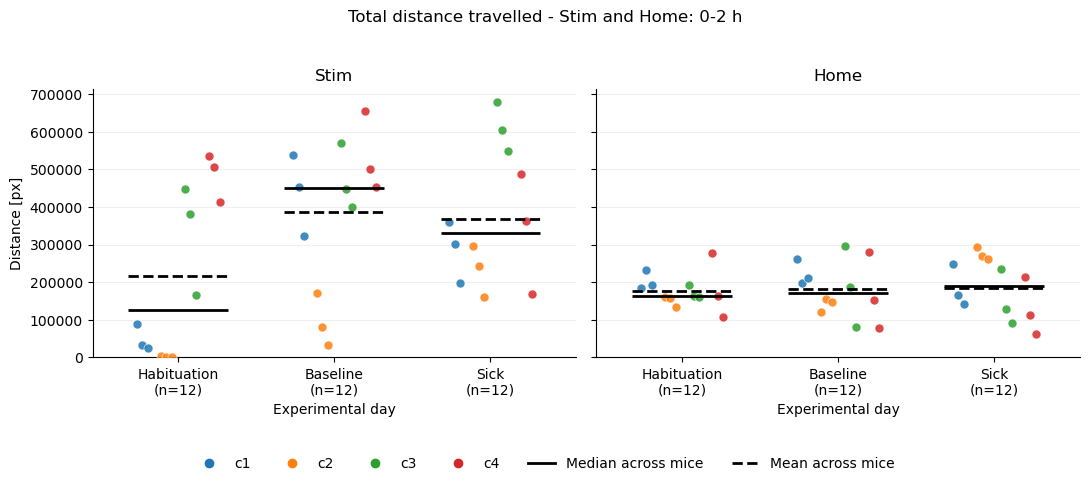

In [194]:
fig, axes = plot_metric(data_dict, 'total_distance', 'Total distance travelled - Stim and Home: 0-2 h', 'Distance [px]')
save_plot_svg(fig, 'total_distance_scatter_stim_home_0_2h.svg')


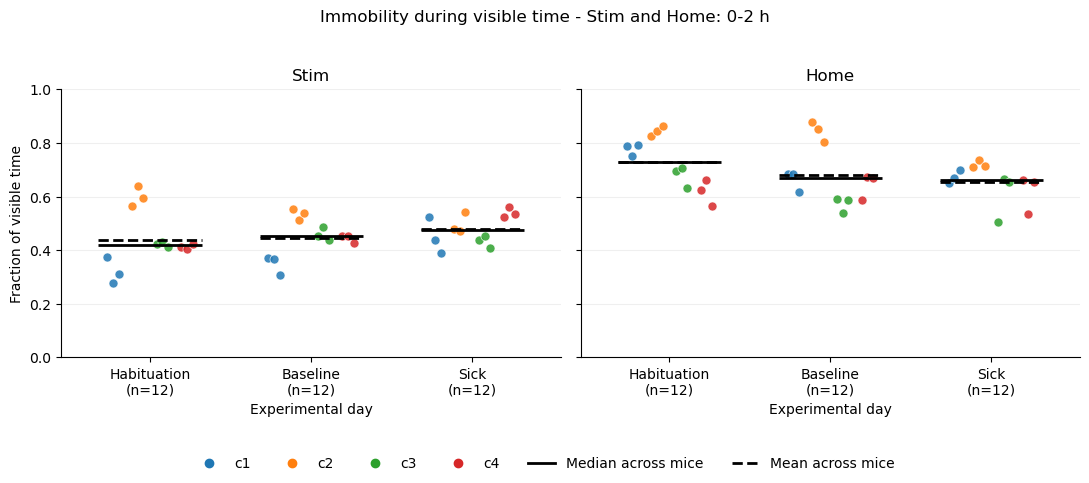

In [195]:
fig, axes = plot_metric(data_dict, 'immobile_fraction', 'Immobility during visible time - Stim and Home: 0-2 h', 'Fraction of visible time', fraction=True)
save_plot_svg(fig, 'immobile_fraction_scatter_stim_home_0_2h.svg')


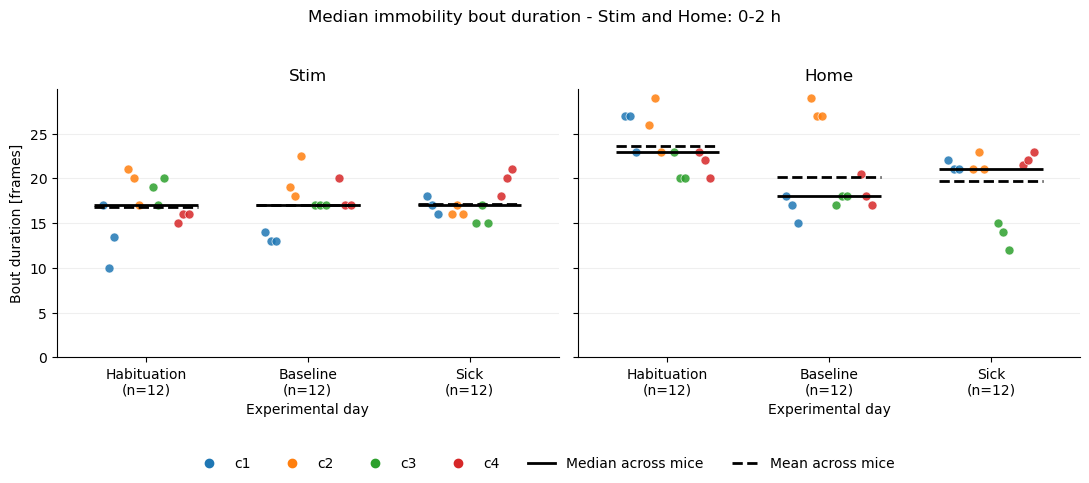

In [196]:
fig, axes = plot_metric(data_dict, 'median_immobile_bout_length', 'Median immobility bout duration - Stim and Home: 0-2 h', 'Bout duration [frames]')
save_plot_svg(fig, 'median_immobile_bout_length_scatter_stim_home_0_2h.svg')


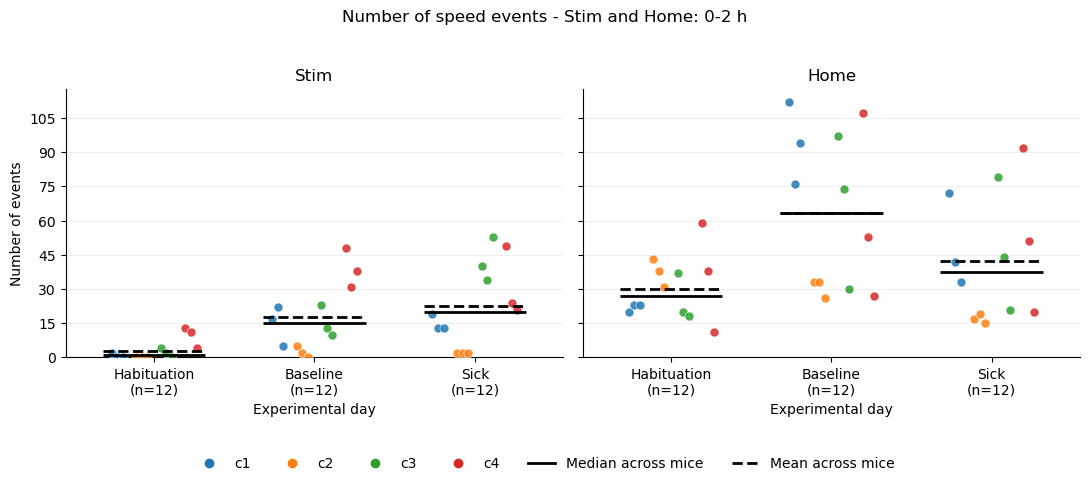

In [197]:
fig, axes = plot_metric(data_dict, 'sum_speedevents', 'Number of speed events - Stim and Home: 0-2 h', 'Number of events', count=True)
save_plot_svg(fig, 'sum_speedevents_scatter_stim_home_0_2h.svg')


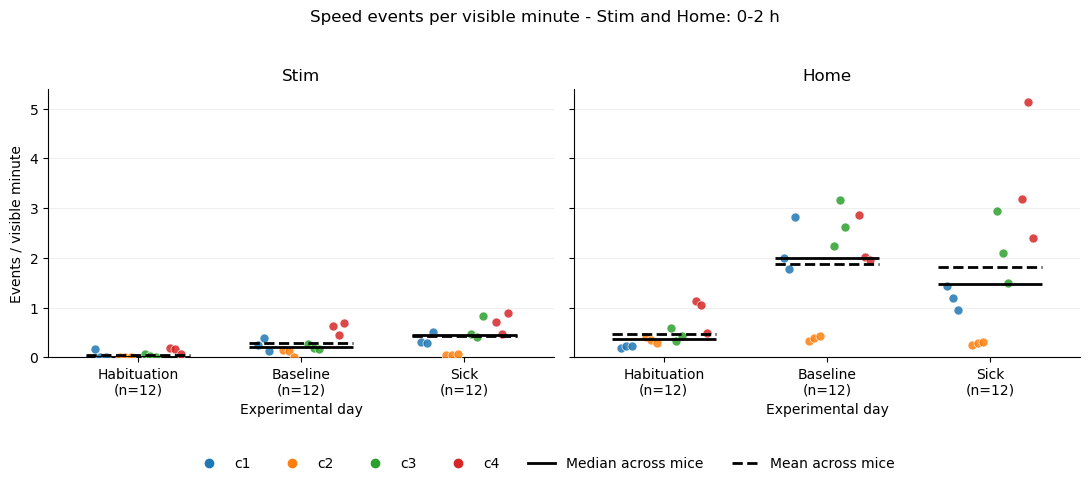

In [198]:
fig, axes = plot_metric(data_dict, 'speedevents_per_visible_minute', 'Speed events per visible minute - Stim and Home: 0-2 h', 'Events / visible minute')
save_plot_svg(fig, 'speedevents_per_visible_minute_scatter_stim_home_0_2h.svg')


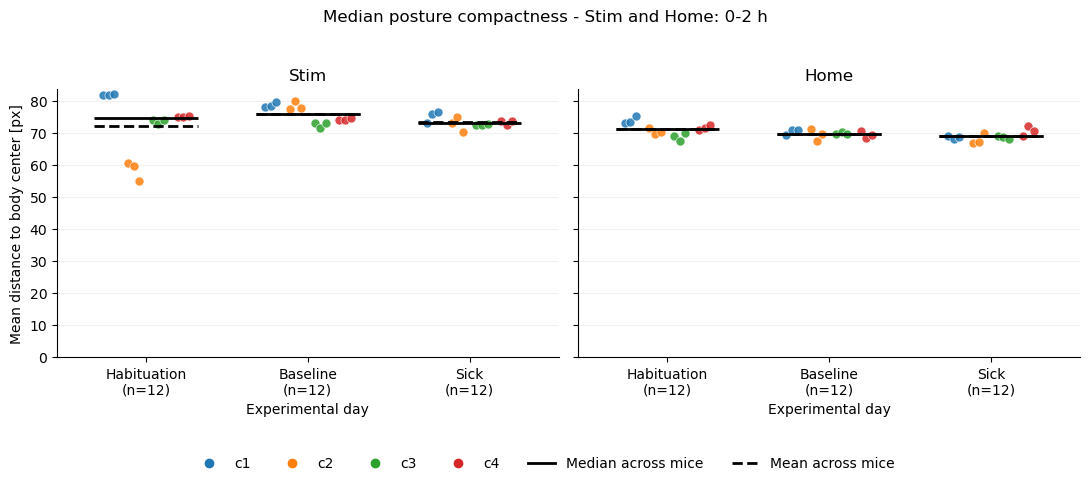

In [199]:
fig, axes = plot_metric(data_dict, 'median_posture_compactness', 'Median posture compactness - Stim and Home: 0-2 h', 'Mean distance to body center [px]')
save_plot_svg(fig, 'median_posture_compactness_scatter_stim_home_0_2h.svg')


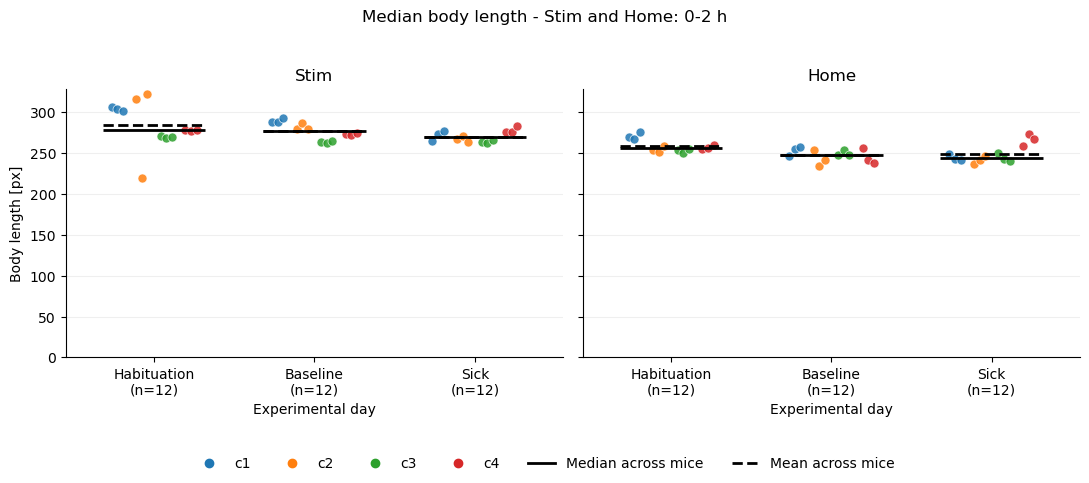

In [200]:
fig, axes = plot_metric(data_dict, 'median_body_length', 'Median body length - Stim and Home: 0-2 h', 'Body length [px]')
save_plot_svg(fig, 'median_body_length_scatter_stim_home_0_2h.svg')


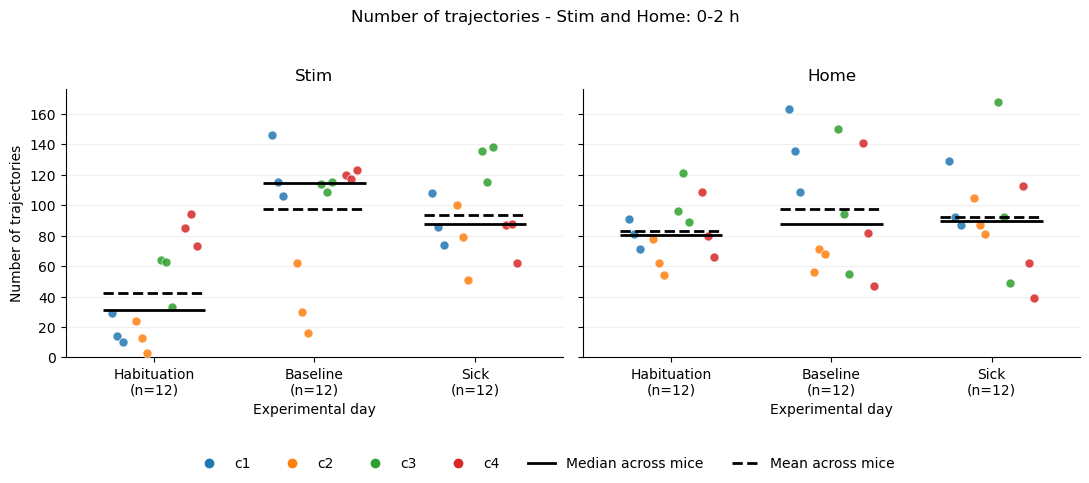

In [201]:
fig, axes = plot_metric(data_dict, 'number_of_trajectories', 'Number of trajectories - Stim and Home: 0-2 h', 'Number of trajectories', count=True)
save_plot_svg(fig, 'number_of_trajectories_scatter_stim_home_0_2h.svg')


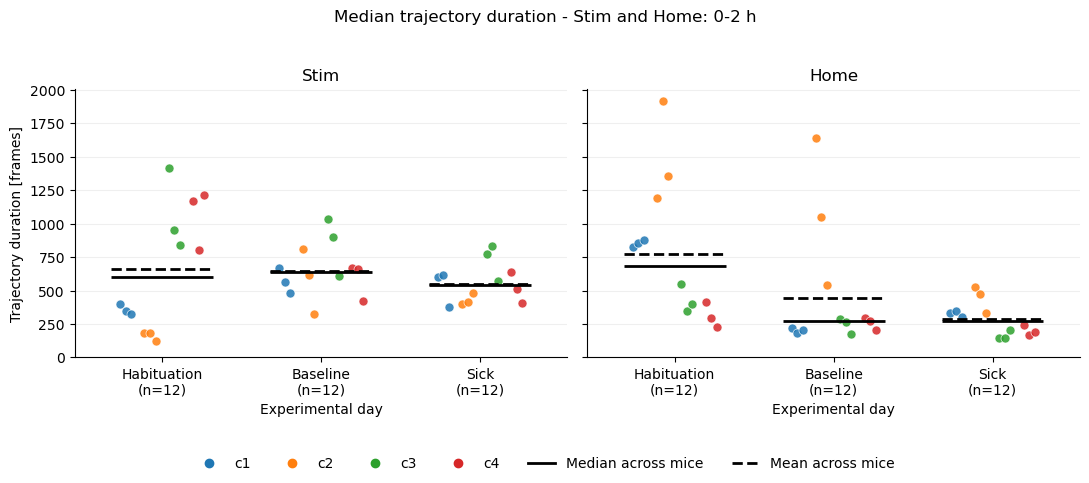

In [202]:
fig, axes = plot_metric(data_dict, 'median_trajectory_length', 'Median trajectory duration - Stim and Home: 0-2 h', 'Trajectory duration [frames]')
save_plot_svg(fig, 'median_trajectory_length_scatter_stim_home_0_2h.svg')


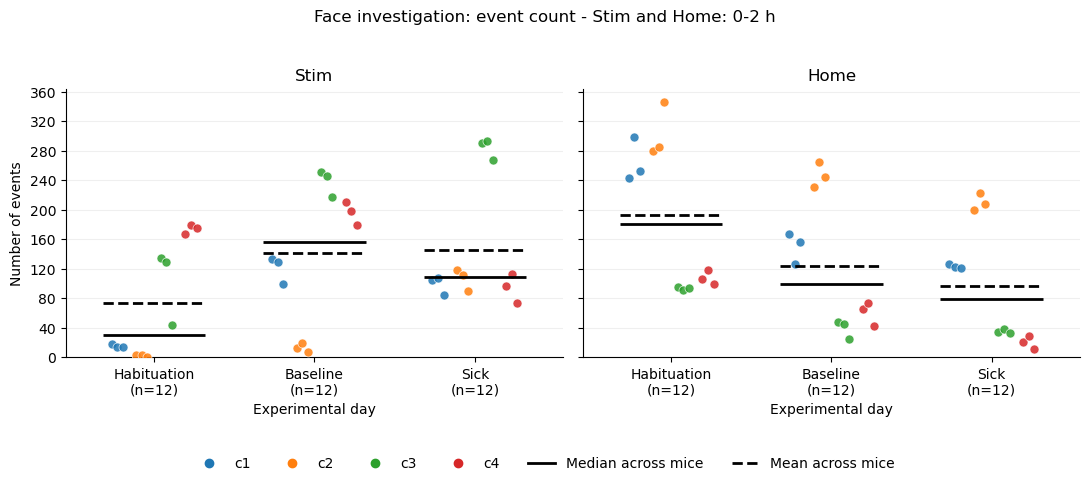

In [203]:
fig, axes = plot_metric(data_dict, 'face_inv_event_count', 'Face investigation: event count - Stim and Home: 0-2 h', 'Number of events', count=True)
save_plot_svg(fig, 'face_inv_event_count_scatter_stim_home_0_2h.svg')


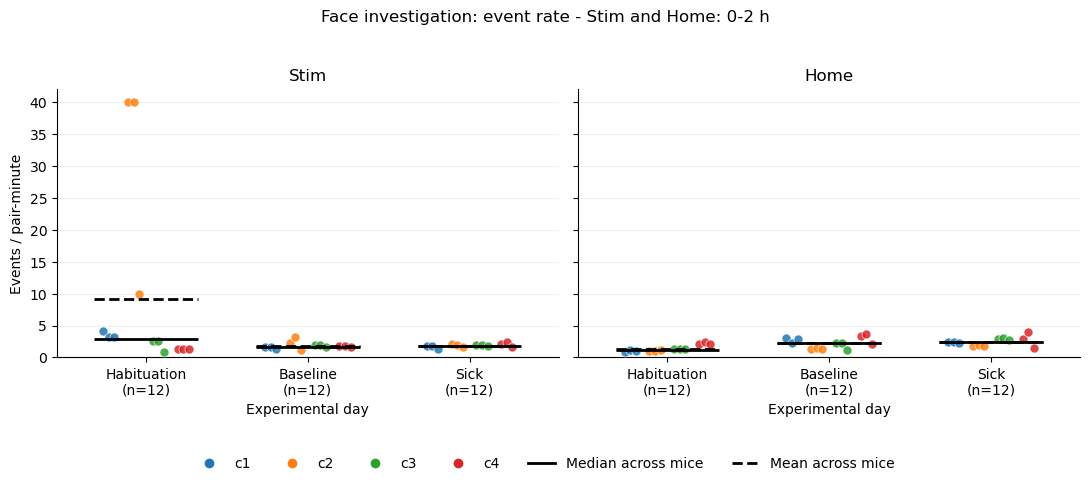

In [204]:
fig, axes = plot_metric(data_dict, 'face_inv_events_per_pair_minute', 'Face investigation: event rate - Stim and Home: 0-2 h', 'Events / pair-minute')
save_plot_svg(fig, 'face_inv_events_per_pair_minute_scatter_stim_home_0_2h.svg')


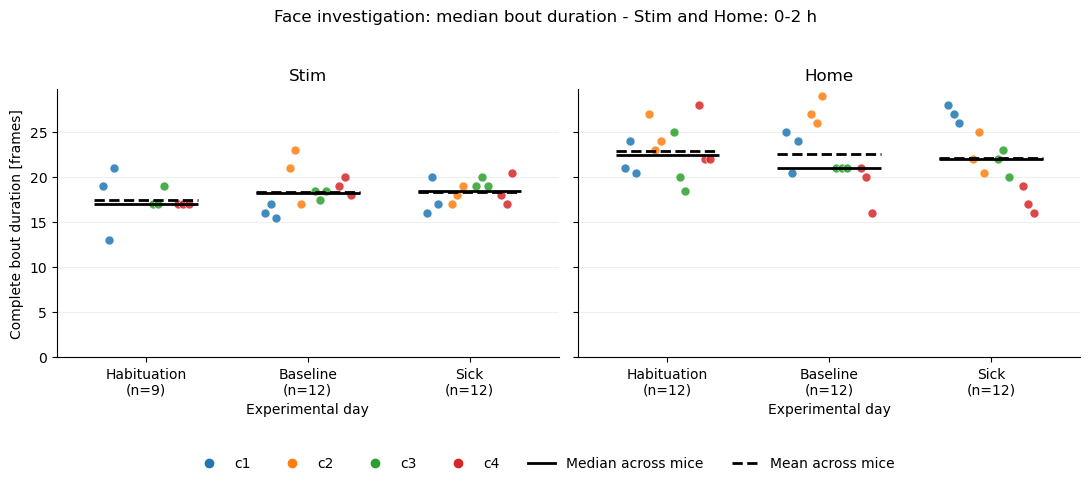

In [205]:
fig, axes = plot_metric(data_dict, 'median_face_inv_bout_length', 'Face investigation: median bout duration - Stim and Home: 0-2 h', 'Complete bout duration [frames]')
save_plot_svg(fig, 'median_face_inv_bout_length_scatter_stim_home_0_2h.svg')


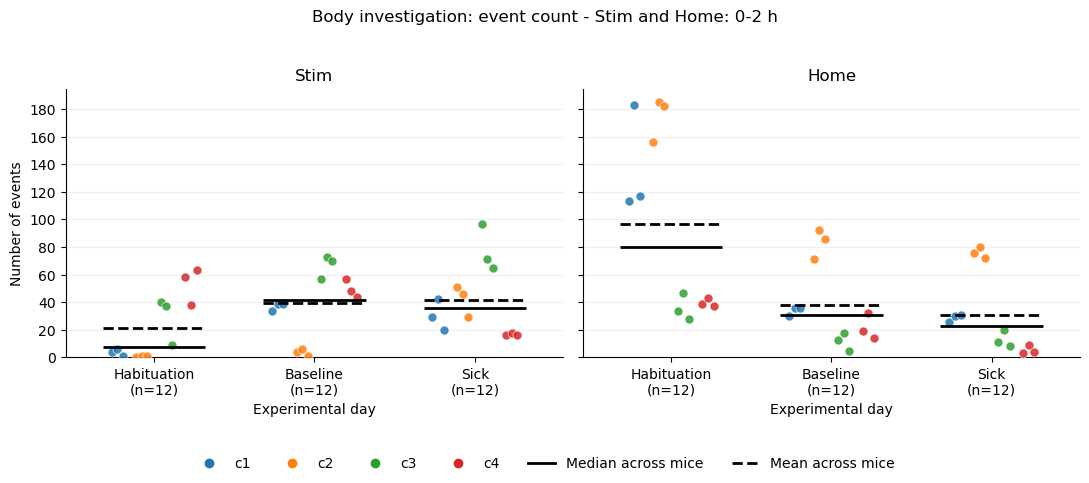

In [206]:
fig, axes = plot_metric(data_dict, 'body_inv_event_count', 'Body investigation: event count - Stim and Home: 0-2 h', 'Number of events', count=True)
save_plot_svg(fig, 'body_inv_event_count_scatter_stim_home_0_2h.svg')


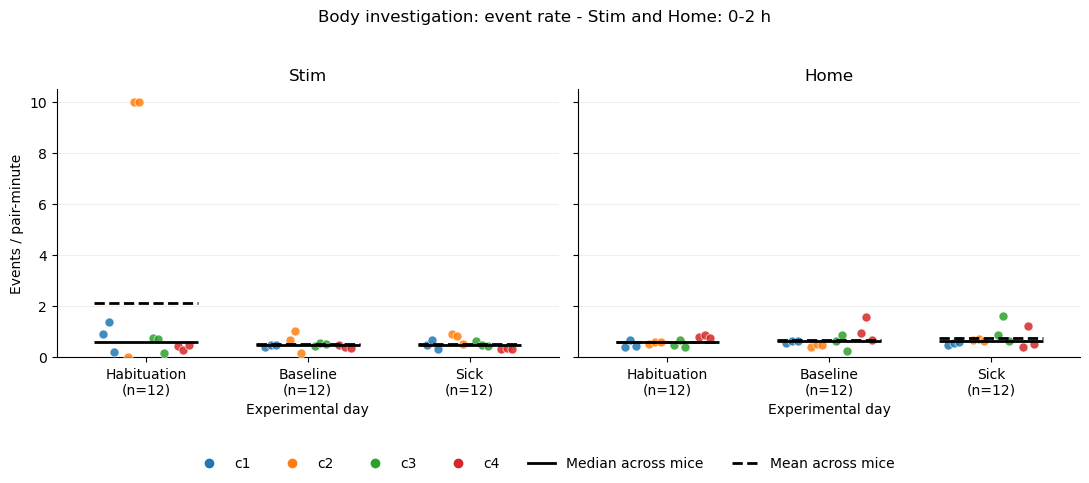

In [207]:
fig, axes = plot_metric(data_dict, 'body_inv_events_per_pair_minute', 'Body investigation: event rate - Stim and Home: 0-2 h', 'Events / pair-minute')
save_plot_svg(fig, 'body_inv_events_per_pair_minute_scatter_stim_home_0_2h.svg')


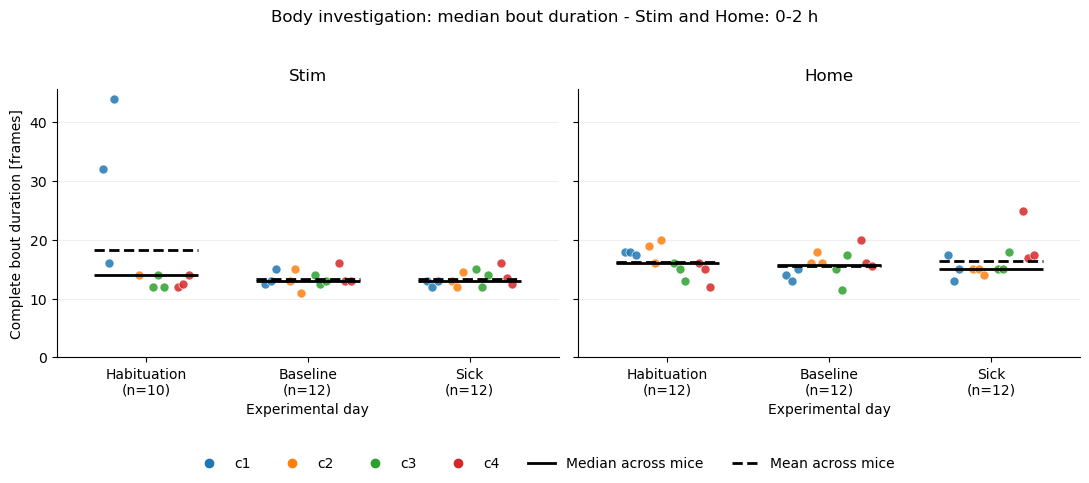

In [208]:
fig, axes = plot_metric(data_dict, 'median_body_inv_bout_length', 'Body investigation: median bout duration - Stim and Home: 0-2 h', 'Complete bout duration [frames]')
save_plot_svg(fig, 'median_body_inv_bout_length_scatter_stim_home_0_2h.svg')


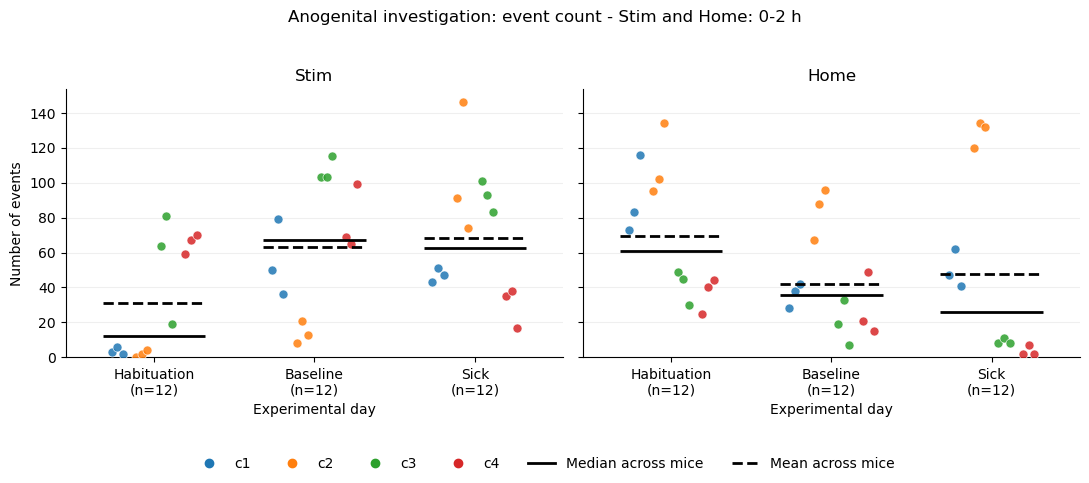

In [209]:
fig, axes = plot_metric(data_dict, 'anogenital_inv_event_count', 'Anogenital investigation: event count - Stim and Home: 0-2 h', 'Number of events', count=True)
save_plot_svg(fig, 'anogenital_inv_event_count_scatter_stim_home_0_2h.svg')


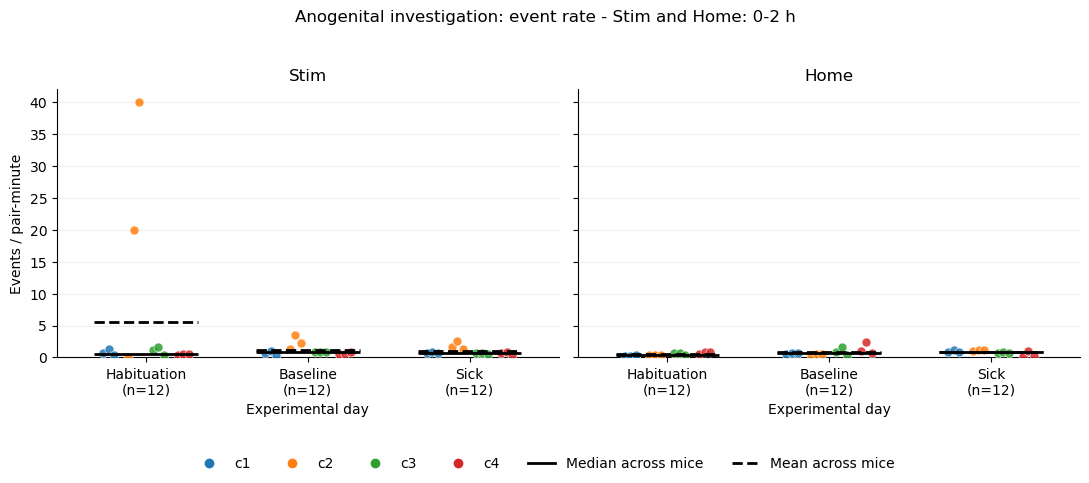

In [210]:
fig, axes = plot_metric(data_dict, 'anogenital_inv_events_per_pair_minute', 'Anogenital investigation: event rate - Stim and Home: 0-2 h', 'Events / pair-minute')
save_plot_svg(fig, 'anogenital_inv_events_per_pair_minute_scatter_stim_home_0_2h.svg')


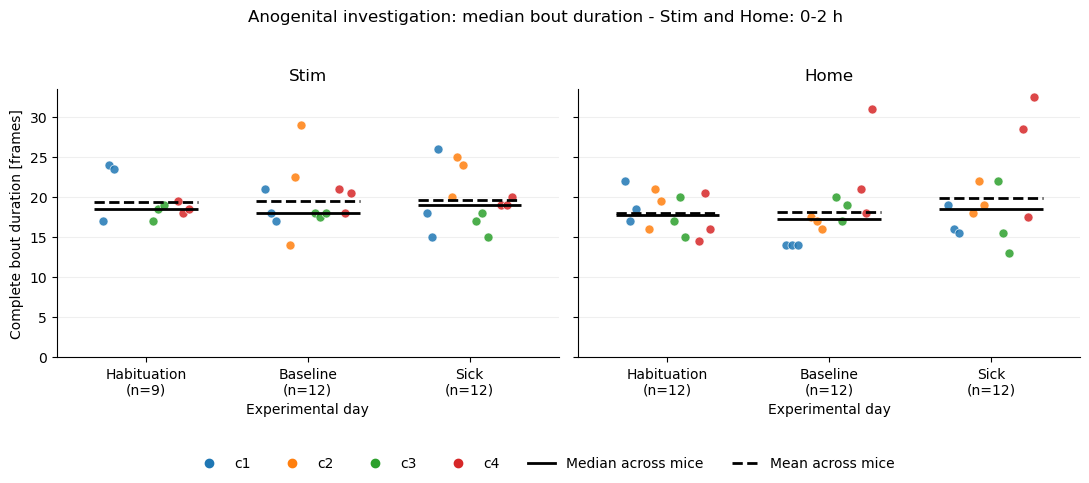

In [211]:
fig, axes = plot_metric(data_dict, 'median_anogenital_inv_bout_length', 'Anogenital investigation: median bout duration - Stim and Home: 0-2 h', 'Complete bout duration [frames]')
save_plot_svg(fig, 'median_anogenital_inv_bout_length_scatter_stim_home_0_2h.svg')


## Home: zweite zwei Stunden

Frames 216000 bis 431999, bei kuerzeren Aufnahmen der verfuegbare Rest. Investigation-Raten verwenden die Pairtime dieses Fensters; Speed-Event-Raten dessen individuelle sichtbare Zeit. Immobilitaets- und Trajektoriendauern werden an beiden Grenzen beschnitten; Ereignisse zaehlen nach ihrem Start im Fenster. Soziale Bout-Mediane enthalten nur vollstaendige Bouts innerhalb des Fensters.


In [150]:
import numpy as np
import pandas as pd
from tqdm import tqdm
from variables import FPS

WINDOW_FRAMES = 216000  # 2 Stunden bei 30 FPS


def finite_median(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    return np.median(values) if values.size else np.nan


def experiment_metadata(frame):
    name = frame.columns.get_level_values("name").unique().item()
    parts = name.split("_")
    if len(parts) == 11:
        parts = ["".join(parts[:3]), "".join(parts[3:6]), *parts[6:10]]
    return name, parts[3], parts[4], parts[5]


def summarize_window(read_in_df, name, individual, start_frame, stop_frame):
    df = read_in_df.iloc[start_frame:stop_frame]
    pair_minutes = np.sum(pairtime_frames(df, name)) / (FPS * 60)
    result = {"pairtime_minutes": pair_minutes}
    def metric_values(metric, full=False):
        source = read_in_df if full else df
        return source.loc[:, (name, individual, metric)].to_numpy(dtype=float).ravel()

    n_frames = len(df)
    visible = metric_values("visible") == 1
    visible_frames = np.count_nonzero(visible)
    visible_minutes = visible_frames / (FPS * 60)

    def per_visible_minute(count):
        return count / visible_minutes if visible_minutes > 0 else np.nan

    # fraction tracked
    result["fraction_present"] = visible_frames / n_frames if n_frames else np.nan

    # median speed (nur Bewegung, wie in der separaten Auswertung)
    speed = metric_values("speed")
    result["median_speed"] = finite_median(speed[visible & (speed > 0)])

    # median acceleration
    result["median_acceleration"] = finite_median(metric_values("acceleration")[visible])

    # total dist travelled (Originaleinheit der cumdist-Metrik: Pixel)
    cumdist = metric_values("cumdist")
    cumdist = cumdist[np.isfinite(cumdist)]
    previous = metric_values("cumdist", full=True)[start_frame - 1] if start_frame else 0.0
    result["total_distance"] = cumdist[-1] - previous if cumdist.size else np.nan

    # immobile fraction normalized to time present
    immobile = metric_values("immobile") == 1
    result["immobile_fraction"] = (
        np.count_nonzero(immobile & visible) / visible_frames
        if visible_frames else np.nan
    )

    # median immobile bout length (Frames; auf beide Fenstergrenzen beschnitten)
    starts = metric_values("immobile_starts", full=True)
    lengths = metric_values("immobile_bout_lengths", full=True)
    valid = np.isfinite(starts) & np.isfinite(lengths) & (starts < stop_frame) & (starts + lengths > start_frame)
    lengths = np.minimum(starts[valid] + lengths[valid], stop_frame) - np.maximum(starts[valid], start_frame)
    result["median_immobile_bout_length"] = finite_median(lengths)

    # speedevents normalized to minute visible
    speed_event_idx = metric_values("speed_event_index", full=True)
    speed_events = np.isfinite(speed_event_idx) & (speed_event_idx >= start_frame) & (speed_event_idx < stop_frame)
    result["sum_speedevents"] = np.count_nonzero(speed_events)
    result["speedevents_per_visible_minute"] = per_visible_minute(result["sum_speedevents"])

    # median posture compactness
    result["median_posture_compactness"] = finite_median(metric_values("posture_compactness")[visible])

    # median body length
    result["median_body_length"] = finite_median(metric_values("body_length")[visible])

    # number of trajectories + median trajectory length (Frames, Endindex inklusive)
    starts = metric_values("center_traj_startidx", full=True)
    ends = metric_values("center_traj_endidx", full=True)
    valid = np.isfinite(starts) & np.isfinite(ends) & (starts < stop_frame) & (ends >= start_frame) & (ends >= starts)
    lengths = np.minimum(ends[valid], stop_frame - 1) - np.maximum(starts[valid], start_frame) + 1
    result["number_of_trajectories"] = np.count_nonzero(valid)
    result["median_trajectory_length"] = finite_median(lengths)

    # number of face, body and anogenital investigation events normalized to pairtime
    # Raten pro Paarminute der Aufnahme; beobachtete Ereignisse inklusive unvollstaendiger Bouts.
    for investigation in ("face_inv", "body_inv", "anogenital_inv"):
        starts = metric_values(investigation + "_starts", full=True)
        stops = metric_values(investigation + "_stops_exclusive", full=True)
        valid = np.isfinite(starts) & np.isfinite(stops) & (starts >= start_frame) & (starts < stop_frame) & (stops > starts)
        count = np.count_nonzero(valid)
        result[investigation + "_event_count"] = count
        result[investigation + "_events_per_pair_minute"] = count / pair_minutes if pair_minutes > 0 else np.nan

        # median face, body and anogenital investigation bout length (Frames)
        # Nur vollstaendige Bouts, die komplett im Auswertungsfenster liegen.
        complete = metric_values(investigation + "_bout_complete", full=True) == 1
        lengths = metric_values(investigation + "_bout_lengths", full=True)
        complete_in_window = valid & complete & (stops <= stop_frame)
        result["median_" + investigation + "_bout_length"] = finite_median(lengths[complete_in_window])

    return result


# Eigenes Dictionary; das bisherige data_dict bleibt erhalten.
data_dict_home_second_2h = {}
home_second_2h_frame_counts = {}
for file in tqdm(experiment_files):
    home_df = pd.read_hdf(file, key="metrics")
    name, cohort, day, condition = experiment_metadata(home_df)
    if condition != "home":
        continue
    start_frame = WINDOW_FRAMES
    stop_frame = min(2 * WINDOW_FRAMES, len(home_df))
    available = max(0, stop_frame - start_frame)
    home_second_2h_frame_counts[(cohort, day, str(file))] = available
    if available < WINDOW_FRAMES:
        print(f"Home {cohort}/{day}: zweite 2 Stunden kuerzer: {available}/{WINDOW_FRAMES} Frames "
              f"({available / FPS / 60:.1f} min). Verwende den verfuegbaren Rest. Datei: {file}")
    target = data_dict_home_second_2h.setdefault(cohort, {}).setdefault(day, {}).setdefault("home", {})
    if available == 0:
        print(f"Home {cohort}/{day}: keine Frames nach den ersten 2 Stunden; uebersprungen.")
        continue
    for individual in home_df.columns.get_level_values("individuals").unique():
        target[individual] = summarize_window(home_df, name, individual, start_frame, stop_frame)


 92%|█████████▏| 22/24 [01:23<00:06,  3.28s/it]

Home c4/habituation: zweite 2 Stunden kuerzer: 2671/216000 Frames (1.5 min). Verwende den verfuegbaren Rest. Datei: Z:\n2023_odor_related_behavior\2026_sick_behavior\raw\c4\habituation\20261027_100105_641117_mice_c4_habituation_home\metric_analysis\experiment.h5


100%|██████████| 24/24 [01:30<00:00,  3.76s/it]


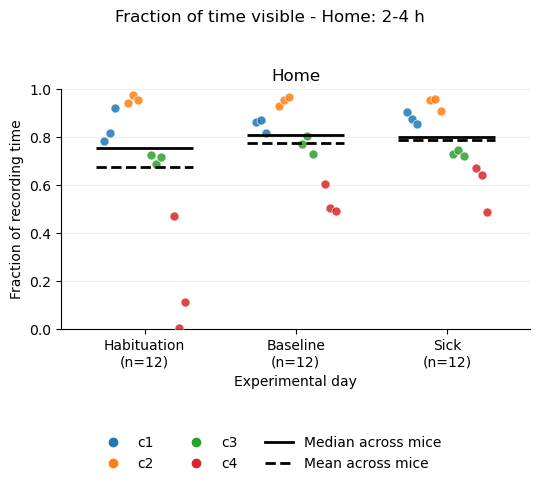

In [212]:
fig, axes = plot_metric(data_dict_home_second_2h, 'fraction_present', 'Fraction of time visible - Home: 2-4 h', 'Fraction of recording time', fraction=True, conditions=('home',))
save_plot_svg(fig, 'fraction_present_scatter_home_2_4h.svg')


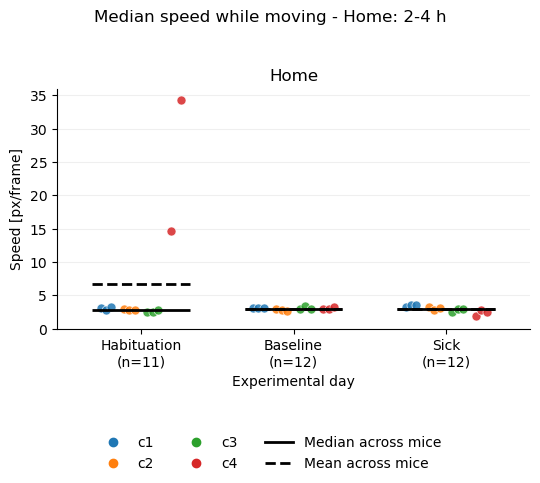

In [213]:
fig, axes = plot_metric(data_dict_home_second_2h, 'median_speed', 'Median speed while moving - Home: 2-4 h', 'Speed [px/frame]', conditions=('home',))
save_plot_svg(fig, 'median_speed_scatter_home_2_4h.svg')


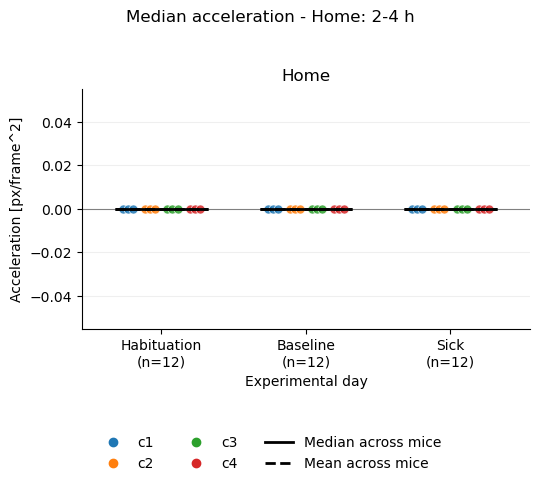

In [214]:
fig, axes = plot_metric(data_dict_home_second_2h, 'median_acceleration', 'Median acceleration - Home: 2-4 h', 'Acceleration [px/frame^2]', signed=True, conditions=('home',))
save_plot_svg(fig, 'median_acceleration_scatter_home_2_4h.svg')


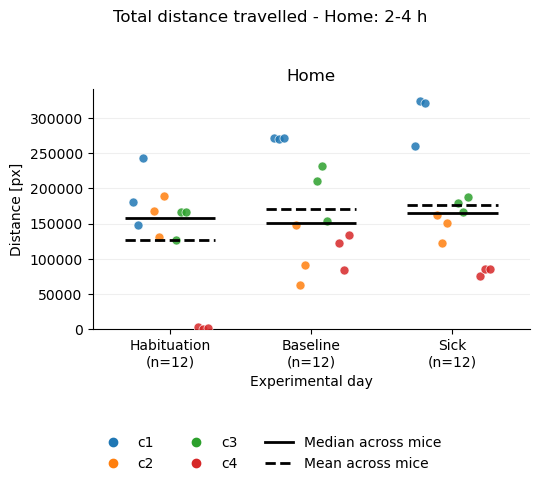

In [215]:
fig, axes = plot_metric(data_dict_home_second_2h, 'total_distance', 'Total distance travelled - Home: 2-4 h', 'Distance [px]', conditions=('home',))
save_plot_svg(fig, 'total_distance_scatter_home_2_4h.svg')


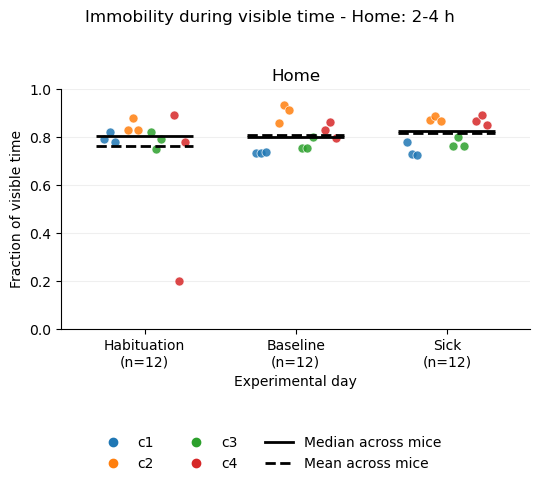

In [216]:
fig, axes = plot_metric(data_dict_home_second_2h, 'immobile_fraction', 'Immobility during visible time - Home: 2-4 h', 'Fraction of visible time', fraction=True, conditions=('home',))
save_plot_svg(fig, 'immobile_fraction_scatter_home_2_4h.svg')


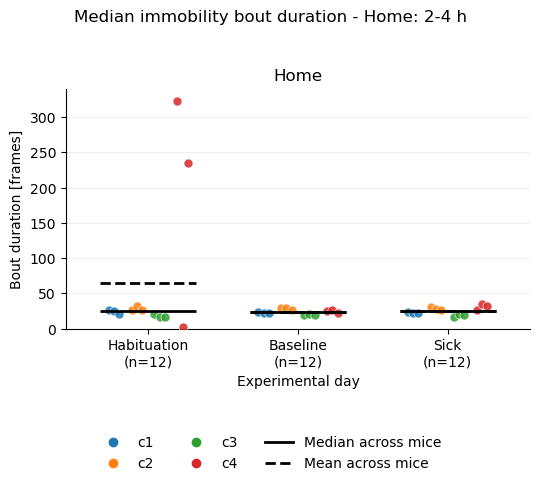

In [217]:
fig, axes = plot_metric(data_dict_home_second_2h, 'median_immobile_bout_length', 'Median immobility bout duration - Home: 2-4 h', 'Bout duration [frames]', conditions=('home',))
save_plot_svg(fig, 'median_immobile_bout_length_scatter_home_2_4h.svg')


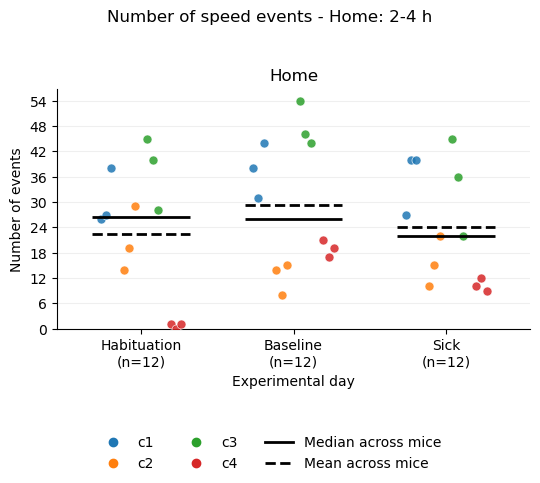

In [218]:
fig, axes = plot_metric(data_dict_home_second_2h, 'sum_speedevents', 'Number of speed events - Home: 2-4 h', 'Number of events', count=True, conditions=('home',))
save_plot_svg(fig, 'sum_speedevents_scatter_home_2_4h.svg')


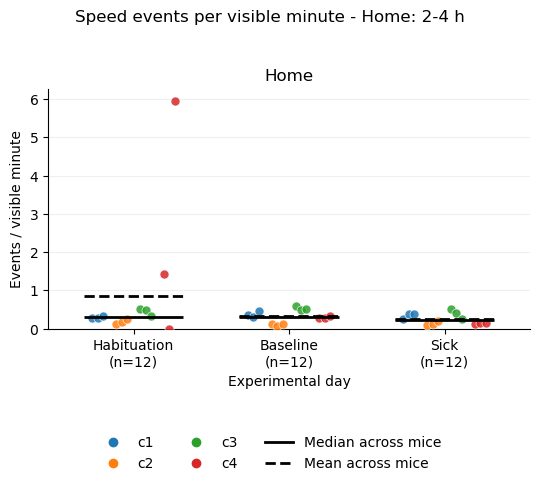

In [219]:
fig, axes = plot_metric(data_dict_home_second_2h, 'speedevents_per_visible_minute', 'Speed events per visible minute - Home: 2-4 h', 'Events / visible minute', conditions=('home',))
save_plot_svg(fig, 'speedevents_per_visible_minute_scatter_home_2_4h.svg')


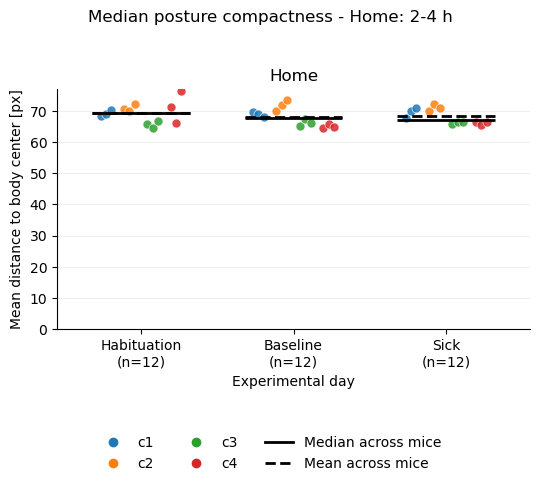

In [220]:
fig, axes = plot_metric(data_dict_home_second_2h, 'median_posture_compactness', 'Median posture compactness - Home: 2-4 h', 'Mean distance to body center [px]', conditions=('home',))
save_plot_svg(fig, 'median_posture_compactness_scatter_home_2_4h.svg')


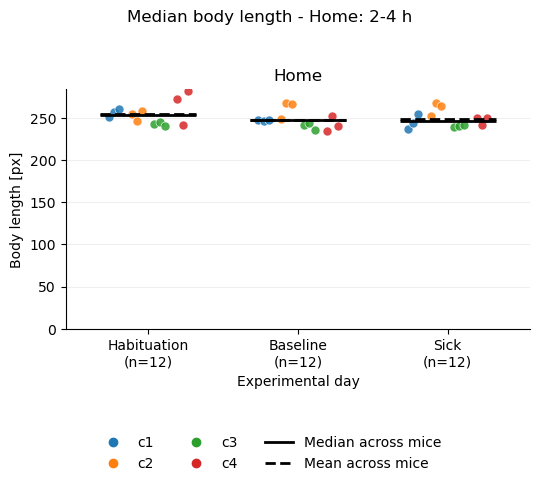

In [221]:
fig, axes = plot_metric(data_dict_home_second_2h, 'median_body_length', 'Median body length - Home: 2-4 h', 'Body length [px]', conditions=('home',))
save_plot_svg(fig, 'median_body_length_scatter_home_2_4h.svg')


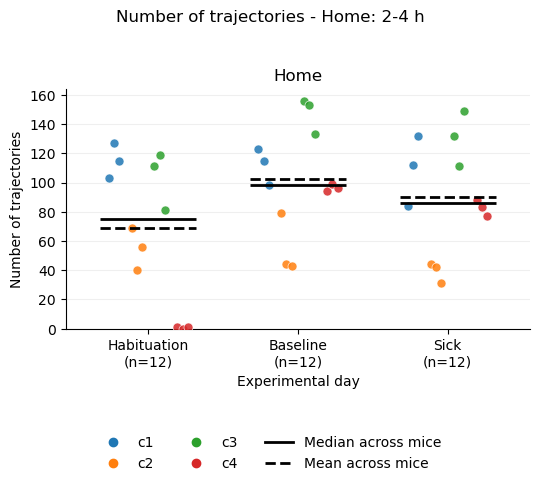

In [222]:
fig, axes = plot_metric(data_dict_home_second_2h, 'number_of_trajectories', 'Number of trajectories - Home: 2-4 h', 'Number of trajectories', count=True, conditions=('home',))
save_plot_svg(fig, 'number_of_trajectories_scatter_home_2_4h.svg')


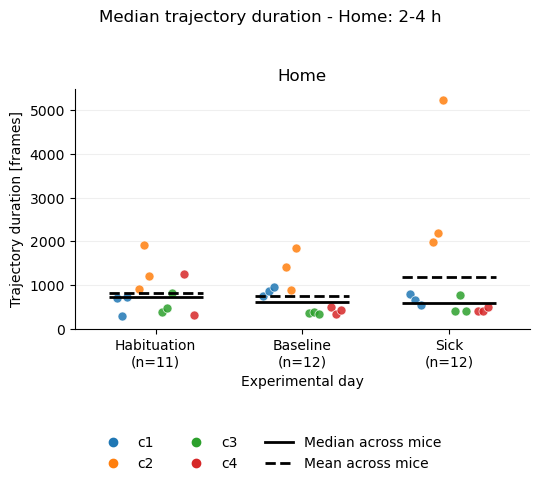

In [223]:
fig, axes = plot_metric(data_dict_home_second_2h, 'median_trajectory_length', 'Median trajectory duration - Home: 2-4 h', 'Trajectory duration [frames]', conditions=('home',))
save_plot_svg(fig, 'median_trajectory_length_scatter_home_2_4h.svg')


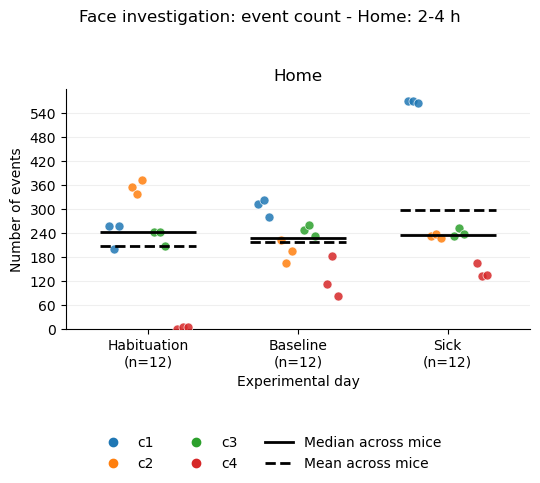

In [224]:
fig, axes = plot_metric(data_dict_home_second_2h, 'face_inv_event_count', 'Face investigation: event count - Home: 2-4 h', 'Number of events', count=True, conditions=('home',))
save_plot_svg(fig, 'face_inv_event_count_scatter_home_2_4h.svg')


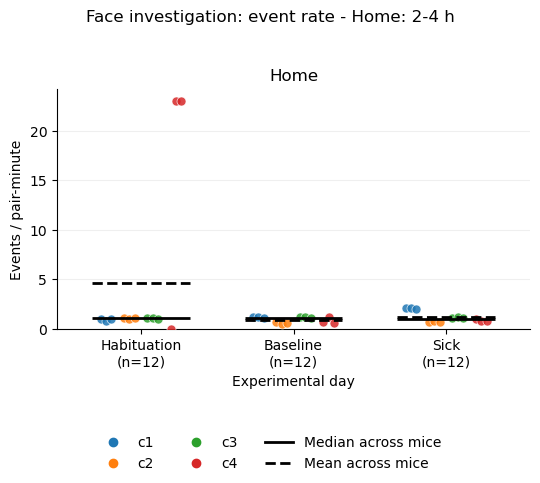

In [225]:
fig, axes = plot_metric(data_dict_home_second_2h, 'face_inv_events_per_pair_minute', 'Face investigation: event rate - Home: 2-4 h', 'Events / pair-minute', conditions=('home',))
save_plot_svg(fig, 'face_inv_events_per_pair_minute_scatter_home_2_4h.svg')


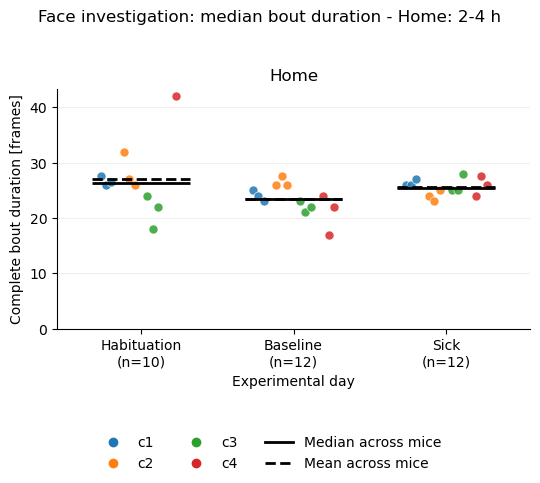

In [226]:
fig, axes = plot_metric(data_dict_home_second_2h, 'median_face_inv_bout_length', 'Face investigation: median bout duration - Home: 2-4 h', 'Complete bout duration [frames]', conditions=('home',))
save_plot_svg(fig, 'median_face_inv_bout_length_scatter_home_2_4h.svg')


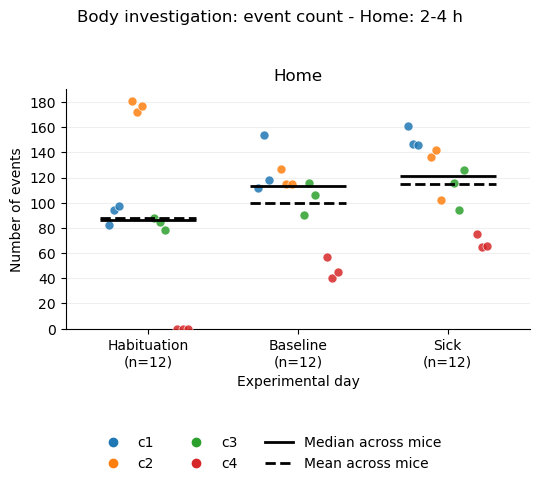

In [227]:
fig, axes = plot_metric(data_dict_home_second_2h, 'body_inv_event_count', 'Body investigation: event count - Home: 2-4 h', 'Number of events', count=True, conditions=('home',))
save_plot_svg(fig, 'body_inv_event_count_scatter_home_2_4h.svg')


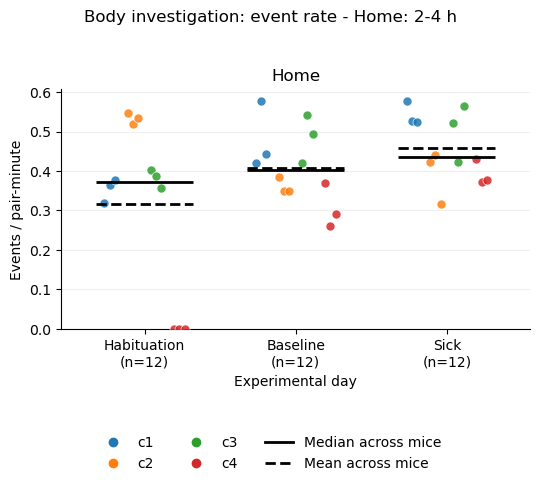

In [228]:
fig, axes = plot_metric(data_dict_home_second_2h, 'body_inv_events_per_pair_minute', 'Body investigation: event rate - Home: 2-4 h', 'Events / pair-minute', conditions=('home',))
save_plot_svg(fig, 'body_inv_events_per_pair_minute_scatter_home_2_4h.svg')


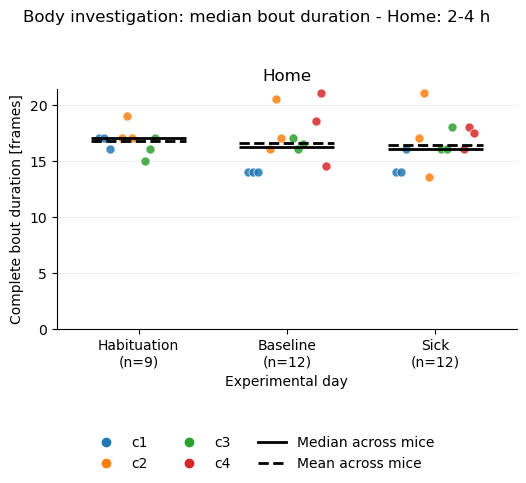

In [229]:
fig, axes = plot_metric(data_dict_home_second_2h, 'median_body_inv_bout_length', 'Body investigation: median bout duration - Home: 2-4 h', 'Complete bout duration [frames]', conditions=('home',))
save_plot_svg(fig, 'median_body_inv_bout_length_scatter_home_2_4h.svg')


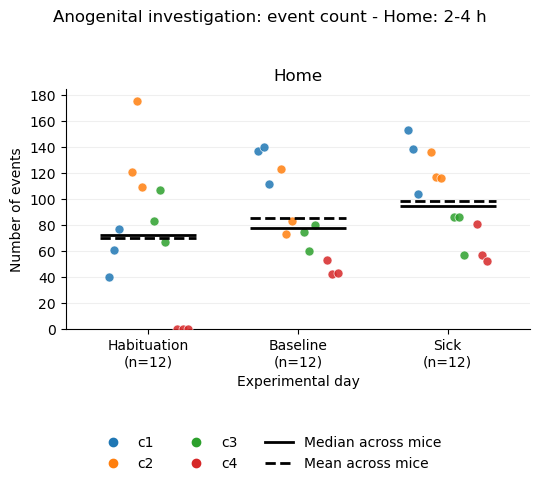

In [230]:
fig, axes = plot_metric(data_dict_home_second_2h, 'anogenital_inv_event_count', 'Anogenital investigation: event count - Home: 2-4 h', 'Number of events', count=True, conditions=('home',))
save_plot_svg(fig, 'anogenital_inv_event_count_scatter_home_2_4h.svg')


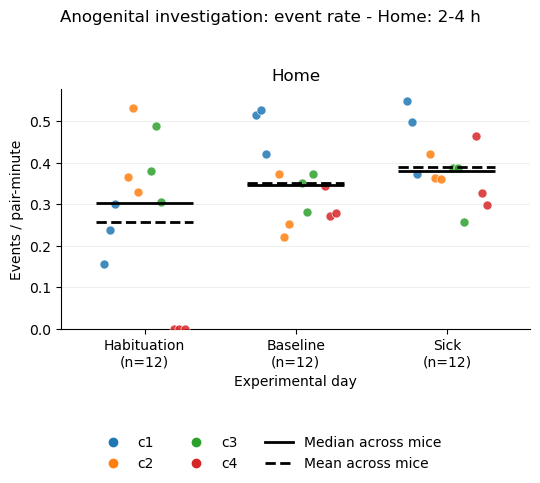

In [231]:
fig, axes = plot_metric(data_dict_home_second_2h, 'anogenital_inv_events_per_pair_minute', 'Anogenital investigation: event rate - Home: 2-4 h', 'Events / pair-minute', conditions=('home',))
save_plot_svg(fig, 'anogenital_inv_events_per_pair_minute_scatter_home_2_4h.svg')


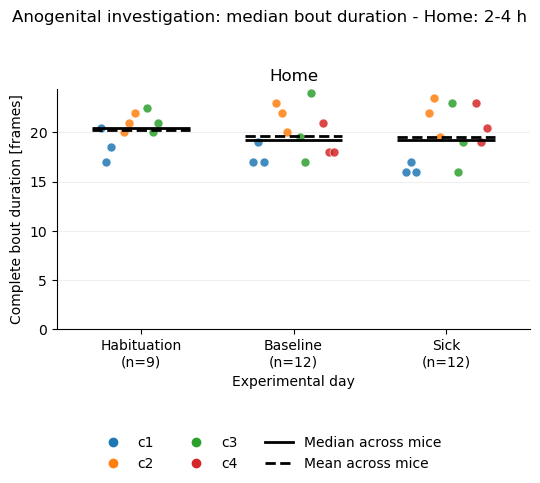

In [232]:
fig, axes = plot_metric(data_dict_home_second_2h, 'median_anogenital_inv_bout_length', 'Anogenital investigation: median bout duration - Home: 2-4 h', 'Complete bout duration [frames]', conditions=('home',))
save_plot_svg(fig, 'median_anogenital_inv_bout_length_scatter_home_2_4h.svg')


## Theta und Arc-Chord: Home 0-4 h, Stim 0-2 h

Je Maus der Median des absoluten Theta bzw. des Arc-Chord-Verhaeltnisses; durchgezogener Strich = Median dieser Mauswerte, gestrichelter Strich = Mean. Kuerzere Aufnahmen verwenden die verfuegbare Dauer. Bei laengeren Aufnahmen werden die Metriken fuer das Fenster neu berechnet, da die gespeicherten Listen keine Frame-Zuordnung besitzen.


In [172]:
from analysis import mouse_center, theta_analysis, arc_chord_ratio


def shape_metrics_window(frame, file, name, individual, stop_frame, pose=None):
    def values(metric):
        return frame.loc[:, (name, individual, metric)].to_numpy(dtype=float).ravel()

    if len(frame) <= stop_frame:
        # Die verdichteten Listen gehoeren zur gesamten, hier passenden Aufnahme.
        theta = values("thetas [stepsize 10 frames]")
        arc = values("arc_chord")
    else:
        # Listenzeilen sind KEINE Frame-Indizes: bei laengeren Aufnahmen neu berechnen.
        starts, ends = values("center_traj_startidx"), values("center_traj_endidx")
        valid = np.isfinite(starts) & np.isfinite(ends) & (starts >= 0) & (starts < stop_frame) & (ends >= starts)
        starts = starts[valid].astype(int)
        ends = np.minimum(ends[valid], stop_frame - 1).astype(int)
        _, arc = arc_chord_ratio(starts, ends, values("center_x")[:stop_frame],
                                 values("center_y")[:stop_frame], fragmentsize_divisor=3, speed_thr=3)
        if pose is None:
            theta = np.array([np.nan])
        else:
            front_x, front_y = mouse_center(pose, individual, ["shoulder_left", "shoulder_right", "dorsal_1"], 3)
            rear_x, rear_y = mouse_center(pose, individual, ["hip_left", "hip_right", "dorsal_4"], 3)
            theta = theta_analysis(individual, front_x, front_y, rear_x, rear_y, starts, ends, stepsize=10) if starts.size else []
    return {"median_absolute_theta": finite_median(np.abs(theta)),
            "median_arc_chord_ratio": finite_median(arc)}


data_dict_theta_arc = {}
for file in tqdm(experiment_files):
    shape_df = pd.read_hdf(file, key="metrics")
    name, cohort, day, condition = experiment_metadata(shape_df)
    if condition not in ("home", "stim"):
        continue
    requested = 2 * WINDOW_FRAMES if condition == "home" else WINDOW_FRAMES
    stop_frame = min(requested, len(shape_df))
    if stop_frame < requested:
        print(f"{cohort}/{day}/{condition}: Theta und Arc-Chord aus {stop_frame}/{requested} Frames.")
    pose = None
    if len(shape_df) > requested:
        try:
            pose = pd.read_hdf(file, key="pose").iloc[:requested]
            if "scorer" in pose.columns.names:
                pose = pose.droplevel("scorer", axis=1)
        except (KeyError, FileNotFoundError) as error:
            print(f"{file}: Pose-Daten fehlen fuer zeitlich begrenztes Theta; Theta bleibt NaN. {error}")
    target = data_dict_theta_arc.setdefault(cohort, {}).setdefault(day, {}).setdefault(condition, {})
    for individual in shape_df.columns.get_level_values("individuals").unique():
        target[individual] = shape_metrics_window(shape_df, file, name, individual, stop_frame, pose)


  4%|▍         | 1/24 [00:08<03:13,  8.41s/it]


An average of 140 frames was discarded per visit.
Depending on Trajectory length, thus might be an unusual high amount, 
checking the tracking of the video is recommended.


  8%|▊         | 2/24 [00:26<05:09, 14.07s/it]


An average of 173 frames was discarded per visit.
Depending on Trajectory length, thus might be an unusual high amount, 
checking the tracking of the video is recommended.


 12%|█▎        | 3/24 [00:27<02:48,  8.03s/it]

c1/habituation/stim: Theta und Arc-Chord aus 63021/216000 Frames.

An average of 457 frames was discarded per visit.
Depending on Trajectory length, thus might be an unusual high amount, 
checking the tracking of the video is recommended.

An average of 446 frames was discarded per visit.
Depending on Trajectory length, thus might be an unusual high amount, 
checking the tracking of the video is recommended.


... (38 outputs left out)

 96%|█████████▌| 23/24 [04:47<00:09,  9.93s/it]


An average of 130 frames was discarded per visit.
Depending on Trajectory length, thus might be an unusual high amount, 
checking the tracking of the video is recommended.

An average of 217 frames was discarded per visit.
Depending on Trajectory length, thus might be an unusual high amount, 
checking the tracking of the video is recommended.

An average of 204 frames was discarded per visit.
Depending on Trajectory length, thus might be an unusual high amount, 
checking the tracking of the video is recommended.


100%|██████████| 24/24 [05:03<00:00, 12.65s/it]


An average of 187 frames was discarded per visit.
Depending on Trajectory length, thus might be an unusual high amount, 
checking the tracking of the video is recommended.


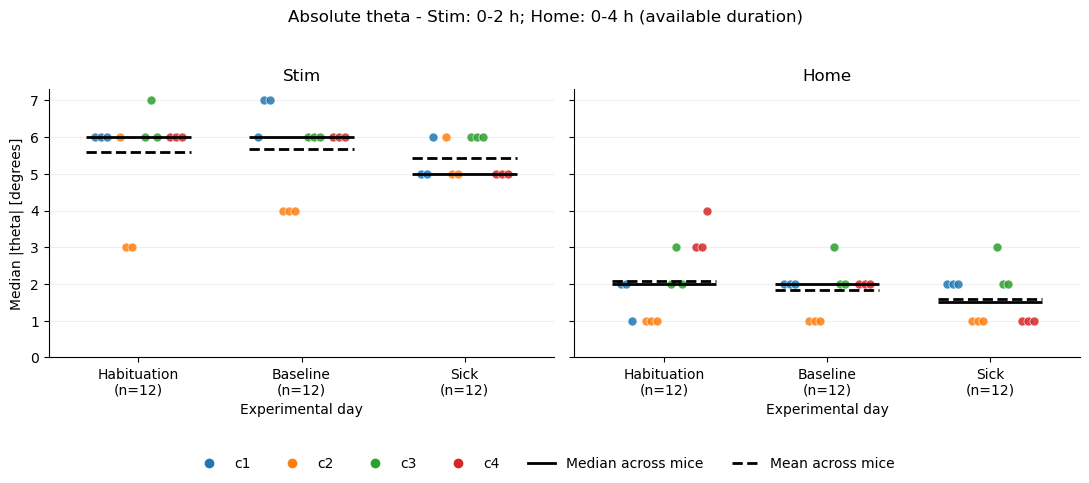

In [233]:
fig, axes = plot_metric(data_dict_theta_arc, 'median_absolute_theta', 'Absolute theta - Stim: 0-2 h; Home: 0-4 h (available duration)', 'Median |theta| [degrees]')
save_plot_svg(fig, 'median_absolute_theta_scatter_stim_0_2h_home_0_4h.svg')


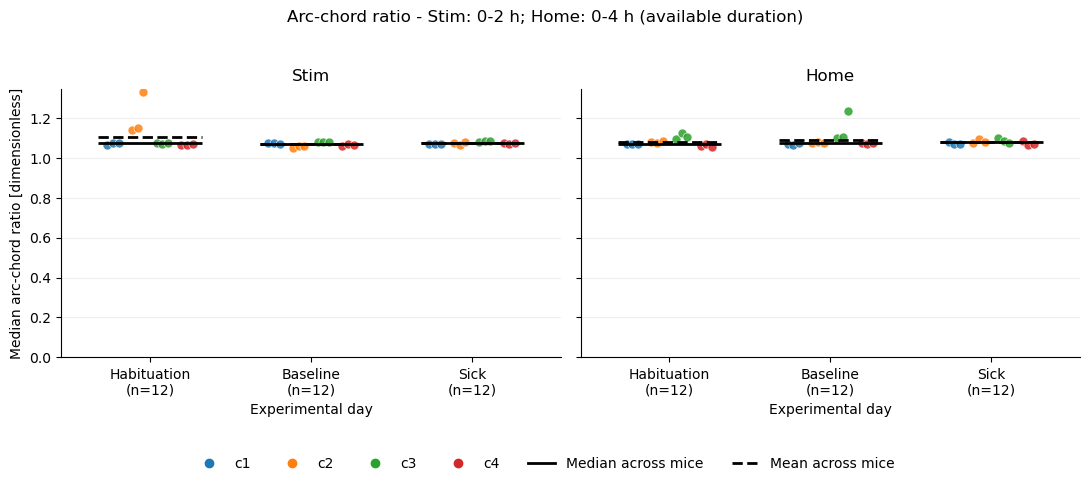

In [234]:
fig, axes = plot_metric(data_dict_theta_arc, 'median_arc_chord_ratio', 'Arc-chord ratio - Stim: 0-2 h; Home: 0-4 h (available duration)', 'Median arc-chord ratio [dimensionless]')
save_plot_svg(fig, 'median_arc_chord_ratio_scatter_stim_0_2h_home_0_4h.svg')


## Zeitverlaeufe pro Condition und Versuchstag

Ein-Minuten-Intervalle, zuerst pro Maus berechnet. Kumulative sichtbare Zeit und Immobilitaet in Minuten; soziale Untersuchung als kumulierte beobachtete Untersuchungsminuten / kumulierte Paarminuten; Distanz aus `cumdist` in Pixeln. Immobilitaet und soziale Untersuchung zaehlen nur sichtbare Frames. Haltungskompaktheit: mittlerer Wert der sichtbaren Frames pro Minute (Pixel). Home 2-4 h beginnt fuer kumulative Zaehler und Pairtime neu; normalisierte Investigation-Kurven beginnen erst bei positiver Pairtime und koennen steigen oder fallen.

Die Zusammenfassung erfolgt ueber alle Maeuse aller Kohorten pro Tag/Panel. Als explorative Auswahlregel wird Shapiro-Wilk je Zeitpunkt mit mindestens 8 Mauswerten verwendet; Holm korrigiert die Tests innerhalb einer Kurve. Mean wird nur verwendet, wenn alle nichtkonstanten Zeitpunkte testbar sind und kein Test verworfen wird, sonst Median. Ein nicht signifikanter Test beweist keine Normalverteilung. Konstante Zeitpunkte benoetigen keinen Test. Die Auswahl gilt durchgehend fuer die Kurve; das Band zeigt immer das 25.-75. Perzentil der Mauswerte, kein Konfidenzintervall.

Kuerzere Aufnahmen werden nicht aufgefuellt. Damit kumulative Kurven nicht durch wechselnde Maeuse springen, endet jede Tageskurve am letzten gemeinsamen vollstaendigen Minutenintervall ihrer vorhandenen Aufnahmen. Ausgeschlossene Restsekunden und verkuerzte Zeitfenster werden gemeldet. `timecourse_mouse_data` behaelt auch die laengeren individuellen Verlaeufe. Maeuse derselben Kohorte sind keine unabhaengigen Kohortenreplikate; die Plots sind deskriptiv.

Investigation-Kurven summieren ausschliesslich beobachtete Untersuchungszeit. Unbekannte Frames (NaN) tragen nichts bei; dies bedeutet nicht, dass dort keine Untersuchung stattfand. Vollstaendig unbeobachtbare Mausreihen werden ausgeschlossen. Die Abdeckung waehrend sichtbarer Zeit wird pro Investigation-Art ausgegeben und in den Tabellenattributen gespeichert.

Die Pairtime wird vor der Zusammenfassung getrennt je Aufnahme berechnet (keine Paarungen zwischen Kohorten). Die Rohzaehler `cumsum_*_inv` und `cumsum_pairtime_minutes` bleiben in `timecourse_mouse_data` gespeichert; geplottet wird `*_inv_time_per_pairtime`. Ohne kumulierte Pairtime bleibt der Wert NaN; spaetere positive Pairtime macht die Kurve auswertbar. Daher kann die Zahl der beitragenden Maeuse zu Beginn variieren; die Legende zeigt den n-Bereich. Die bekannte Tracking-Luecken-Behandlung bleibt bestehen.


In [175]:
import numpy as np
import pandas as pd
from tqdm import tqdm
from variables import FPS

TIME_BIN_SECONDS = 60
TIME_BIN_FRAMES = int(TIME_BIN_SECONDS * FPS)
TIME_WINDOW_FRAMES = 216000
TIME_PANELS = {
    "home_0_2h": ("home", 0, TIME_WINDOW_FRAMES),
    "stim_0_2h": ("stim", 0, TIME_WINDOW_FRAMES),
    "home_2_4h": ("home", TIME_WINDOW_FRAMES, 2 * TIME_WINDOW_FRAMES),
}


def timecourse_metadata(frame):
    name = frame.columns.get_level_values("name").unique().item()
    parts = name.split("_")
    if len(parts) == 11:
        parts = ["".join(parts[:3]), "".join(parts[3:6]), *parts[6:10]]
    return name, parts[3], parts[4], parts[5]


def extract_mouse_timecourse(frame, name, individual, start, stop):
    window = frame.iloc[start:stop]
    n_bins = len(window) // TIME_BIN_FRAMES
    if not n_bins:
        return None
    ends = np.arange(1, n_bins + 1) * TIME_BIN_FRAMES

    def values(metric):
        return window.loc[:, (name, individual, metric)].to_numpy(dtype=float).ravel()

    visible = values("visible") == 1
    cumulative_pair_minutes = np.cumsum(pairtime_frames(window, name), dtype=float)[ends - 1] / (FPS * 60)
    result = {"elapsed_minutes": ends / FPS / 60,
              "cumsum_pairtime_minutes": cumulative_pair_minutes}
    coverage = {}
    for metric, key in [("visible", "cumsum_visible"), ("immobile", "cumsum_immobile"),
                        ("face_inv", "cumsum_face_inv"), ("body_inv", "cumsum_body_inv"),
                        ("anogenital_inv", "cumsum_anogenital_inv")]:
        raw = values(metric)
        active = (raw == 1) & visible
        cumulative = np.nancumsum(active, dtype=float) / FPS / 60
        sampled = cumulative[ends - 1]
        if metric.endswith("_inv"):
            # Beobachtete Untersuchungszeit: unbekannte Frames addieren nichts,
            # machen spaetere bekannte Messungen aber nicht unbrauchbar.
            used = ends[-1]
            observable = np.isfinite(raw[:used]) & visible[:used]
            n_visible = np.count_nonzero(visible[:used])
            n_observed = np.count_nonzero(observable)
            coverage[key] = n_observed / n_visible if n_visible else np.nan
            # Keine Beobachtung ist nicht dasselbe wie beobachtete Nullaktivitaet.
            if n_observed == 0:
                sampled[:] = np.nan
        else:
            unknown = ~np.isfinite(raw) & (visible if metric != "visible" else True)
            sampled[np.cumsum(unknown)[ends - 1] > 0] = np.nan
        result[key] = sampled
        if metric.endswith("_inv"):
            # Quotient der kumulierten Zeiten, nicht die Summe einzelner Quotienten.
            # Bei noch fehlender Paarzeit ist der Quotient undefiniert (NaN).
            result[metric + "_time_per_pairtime"] = np.divide(
                sampled, cumulative_pair_minutes,
                out=np.full(n_bins, np.nan), where=cumulative_pair_minutes > 0)

    distance = values("cumdist")
    baseline = float(frame.loc[:, (name, individual, "cumdist")].iloc[start - 1]) if start else 0.0
    result["cumsum_speed"] = distance[ends - 1] - baseline
    compactness = values("posture_compactness")[:n_bins * TIME_BIN_FRAMES].copy()
    compactness[~visible[:len(compactness)]] = np.nan
    compactness = compactness.reshape(n_bins, TIME_BIN_FRAMES)
    counts = np.isfinite(compactness).sum(axis=1)
    result["posture_compactness"] = np.divide(
        np.nansum(compactness, axis=1), counts,
        out=np.full(n_bins, np.nan), where=counts > 0)
    table = pd.DataFrame(result)
    table.attrs["investigation_coverage"] = coverage
    return table


timecourse_mouse_data = {panel: {} for panel in TIME_PANELS}
for file in tqdm(experiment_files):
    time_df = pd.read_hdf(file, key="metrics")
    name, cohort, day, condition = timecourse_metadata(time_df)
    if day not in ("habituation", "baseline", "sick"):
        continue
    for panel, (wanted_condition, start, requested_stop) in TIME_PANELS.items():
        if condition != wanted_condition:
            continue
        stop = min(requested_stop, len(time_df))
        available = max(0, stop - start)
        if available < TIME_WINDOW_FRAMES or available % TIME_BIN_FRAMES:
            print(f"{cohort}/{day}/{panel}: {available / FPS / 60:.2f} min verfuegbar, "
                  f"{available // TIME_BIN_FRAMES} volle Minuten verwendet. Datei: {file}")
        if available < TIME_BIN_FRAMES:
            continue
        target = timecourse_mouse_data[panel].setdefault(day, {})
        for individual in time_df.columns.get_level_values("individuals").unique():
            mouse_key = (cohort, individual)
            if mouse_key in target:
                raise ValueError(f"Mehrere Aufnahmen fuer {panel}/{day}/{mouse_key}; bitte Dateien gezielt auswaehlen.")
            target[mouse_key] = extract_mouse_timecourse(time_df, name, individual, start, stop)


 12%|█▎        | 3/24 [00:09<00:57,  2.74s/it]

c1/habituation/stim_0_2h: 35.01 min verfuegbar, 35 volle Minuten verwendet. Datei: Z:\n2023_odor_related_behavior\2026_sick_behavior\raw\c1\habituation\top1\metric_analysis\experiment.h5


 25%|██▌       | 6/24 [00:22<01:06,  3.71s/it]

c1/sick/stim_0_2h: 119.26 min verfuegbar, 119 volle Minuten verwendet. Datei: Z:\n2023_odor_related_behavior\2026_sick_behavior\raw\c1\sick\stim\metric_analysis\experiment.h5


 42%|████▏     | 10/24 [00:41<00:54,  3.91s/it]

c2/habituation/stim_0_2h: 23.24 min verfuegbar, 23 volle Minuten verwendet. Datei: Z:\n2023_odor_related_behavior\2026_sick_behavior\raw\c2\habituation\stim\metric_analysis\experiment.h5


 92%|█████████▏| 22/24 [01:29<00:07,  3.66s/it]

c4/habituation/home_2_4h: 1.48 min verfuegbar, 1 volle Minuten verwendet. Datei: Z:\n2023_odor_related_behavior\2026_sick_behavior\raw\c4\habituation\20261027_100105_641117_mice_c4_habituation_home\metric_analysis\experiment.h5


100%|██████████| 24/24 [01:37<00:00,  4.07s/it]


In [235]:
import matplotlib.pyplot as plt
from scipy.stats import shapiro

SOCIAL_TIME_METRICS = {key + "_time_per_pairtime": "cumsum_" + key
                       for key in ("face_inv", "body_inv", "anogenital_inv")}
TIME_METRICS = ["cumsum_visible", "cumsum_speed", "cumsum_immobile", "posture_compactness",
                *SOCIAL_TIME_METRICS]


def choose_timecourse_statistic(matrix, alpha=0.05, min_n=8):
    p_values = []
    for column in matrix.T:
        finite = column[np.isfinite(column)]
        if finite.size == 0:
            continue  # z.B. vor der ersten positiven Pairtime
        if np.all(finite == finite[0]):
            continue
        if finite.size < min_n:
            return "median", f"weniger als {min_n} gueltige Maeuse"
        p_values.append(shapiro(finite).pvalue)
    ordered = np.sort(p_values)
    # Holm: Falls der kleinste p-Wert die erste Schwelle nicht erreicht,
    # wird kein Test verworfen. Sonst ist mindestens ein Zeitpunkt abweichend.
    if len(ordered) and ordered[0] <= alpha / len(ordered):
        return "median", "Shapiro-Wilk/Holm verwirft Normalverteilung"
    return "mean", "keine Ablehnung durch Shapiro-Wilk/Holm (oder konstante Werte)"


timecourse_summary = {}
for panel, days in timecourse_mouse_data.items():
    timecourse_summary[panel] = {}
    for day, mice in days.items():
        common_bins = min(len(table) for table in mice.values())
        if common_bins < TIME_WINDOW_FRAMES // TIME_BIN_FRAMES:
            print(f"{panel}/{day}: gemeinsame Kurvendauer {common_bins * TIME_BIN_SECONDS / 60:g} min, "
                  f"{len(mice)} Maeuse; laengere Einzelverlaeufe bleiben gespeichert.")
        timecourse_summary[panel][day] = {}
        for metric in TIME_METRICS:
            matrix = np.vstack([table[metric].to_numpy()[:common_bins] for table in mice.values()])
            # Keine wechselnde Zusammensetzung bei kumulativen Groessen.
            if metric.startswith("cumsum_"):
                matrix = matrix[np.all(np.isfinite(matrix), axis=1)]
            if metric in SOCIAL_TIME_METRICS:
                # Anfangs ohne Paarzeit: NaN, aber spaetere gueltige Werte behalten.
                matrix = matrix[np.any(np.isfinite(matrix), axis=1)]
                coverage_key = SOCIAL_TIME_METRICS[metric]
                coverage = np.array([table.attrs.get("investigation_coverage", {}).get(coverage_key, np.nan)
                                     for table in mice.values()])
                finite_coverage = coverage[np.isfinite(coverage)]
                coverage_label = (f"{100 * finite_coverage.min():.1f}-{100 * finite_coverage.max():.1f}%"
                                  if finite_coverage.size else "unbekannt")
                print(f"{panel}/{day}/{metric}: {len(matrix)}/{len(mice)} Maeuse verwendbar; "
                      f"Datenabdeckung waehrend Sichtbarkeit je Maus: {coverage_label} "
                      "(gesamter individueller Verlauf).")
            statistic, reason = choose_timecourse_statistic(matrix)
            center, lower, upper, counts = [], [], [], []
            for column in matrix.T:
                finite = column[np.isfinite(column)]
                counts.append(len(finite))
                center.append((np.mean(finite) if statistic == "mean" else np.median(finite)) if len(finite) else np.nan)
                quantiles = np.percentile(finite, [25, 75]) if len(finite) else [np.nan, np.nan]
                lower.append(quantiles[0]); upper.append(quantiles[1])
            summary = pd.DataFrame({
                "elapsed_minutes": np.arange(1, common_bins + 1) * TIME_BIN_SECONDS / 60,
                "center": center, "q25": lower, "q75": upper, "n": counts})
            summary.attrs.update(statistic=statistic, reason=reason)
            timecourse_summary[panel][day][metric] = summary
            print(f"{panel}/{day}/{metric}: {statistic} ({reason})")


def plot_timecourse(metric, title, ylabel):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
    panel_titles = ["Home (0-2 h)", "Stim (0-2 h)", "Home (2-4 h)"]
    colors = {"habituation": "#4477AA", "baseline": "#228833", "sick": "#CC6677"}
    for ax, panel, panel_title in zip(axes, TIME_PANELS, panel_titles):
        offset = 120 if panel == "home_2_4h" else 0
        for day, color in colors.items():
            table = timecourse_summary.get(panel, {}).get(day, {}).get(metric)
            if table is None or not np.any(np.isfinite(table["center"])):
                continue
            x = table["elapsed_minutes"].to_numpy() + offset
            y, lo, hi = (table[k].to_numpy() for k in ("center", "q25", "q75"))
            if metric.startswith("cumsum_"):
                x = np.r_[offset, x]; y = np.r_[0, y]; lo = np.r_[0, lo]; hi = np.r_[0, hi]
            n_min, n_max = table["n"].min(), table["n"].max()
            count_label = str(n_min) if n_min == n_max else f"{n_min}-{n_max}"
            ax.plot(x, y, color=color, linewidth=2,
                    label=f"{day.capitalize()} ({table.attrs['statistic']}, n={count_label})")
            ax.fill_between(x, lo, hi, color=color, alpha=0.15, linewidth=0)
        ax.set_title(panel_title)
        ax.set_xlim(offset, offset + 120)
        ax.set_xlabel("Time since experiment start [min]")
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)
        if ax.lines:
            ax.legend(fontsize=8, loc="best")
        else:
            ax.text(0.5, 0.5, "No valid data", transform=ax.transAxes, ha="center")
    axes[0].set_ylabel(ylabel)
    fig.suptitle(title + " | Shading: 25th-75th percentile")
    fig.tight_layout()
    plt.show()
    return fig, axes


home_0_2h/baseline/cumsum_visible: mean (keine Ablehnung durch Shapiro-Wilk/Holm (oder konstante Werte))
home_0_2h/baseline/cumsum_speed: mean (keine Ablehnung durch Shapiro-Wilk/Holm (oder konstante Werte))
home_0_2h/baseline/cumsum_immobile: mean (keine Ablehnung durch Shapiro-Wilk/Holm (oder konstante Werte))
home_0_2h/baseline/posture_compactness: median (weniger als 8 gueltige Maeuse)
home_0_2h/baseline/face_inv_time_per_pairtime: 12/12 Maeuse verwendbar; Datenabdeckung waehrend Sichtbarkeit je Maus: 33.5-93.3% (gesamter individueller Verlauf).
home_0_2h/baseline/face_inv_time_per_pairtime: mean (keine Ablehnung durch Shapiro-Wilk/Holm (oder konstante Werte))
home_0_2h/baseline/body_inv_time_per_pairtime: 12/12 Maeuse verwendbar; Datenabdeckung waehrend Sichtbarkeit je Maus: 34.2-93.8% (gesamter individueller Verlauf).
home_0_2h/baseline/body_inv_time_per_pairtime: median (Shapiro-Wilk/Holm verwirft Normalverteilung)
home_0_2h/baseline/anogenital_inv_time_per_pairtime: 12/12 Maeus

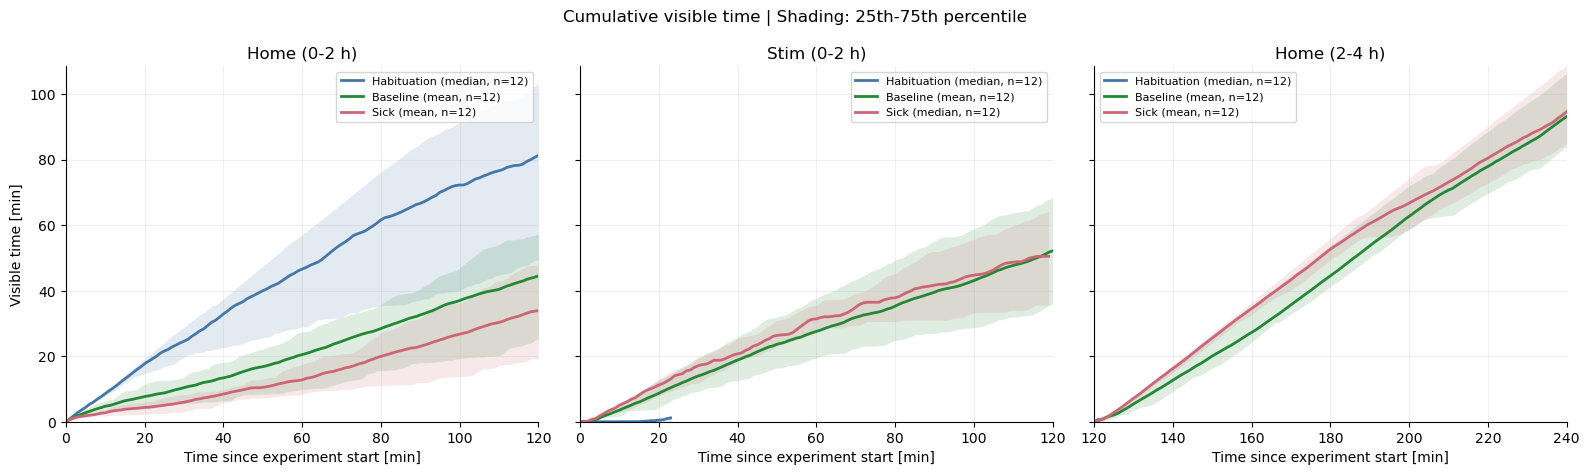

In [236]:
fig, axes = plot_timecourse('cumsum_visible', 'Cumulative visible time', 'Visible time [min]')
save_plot_svg(fig, 'cumsum_visible_timecourse_home_0_2h_stim_0_2h_home_2_4h.svg')


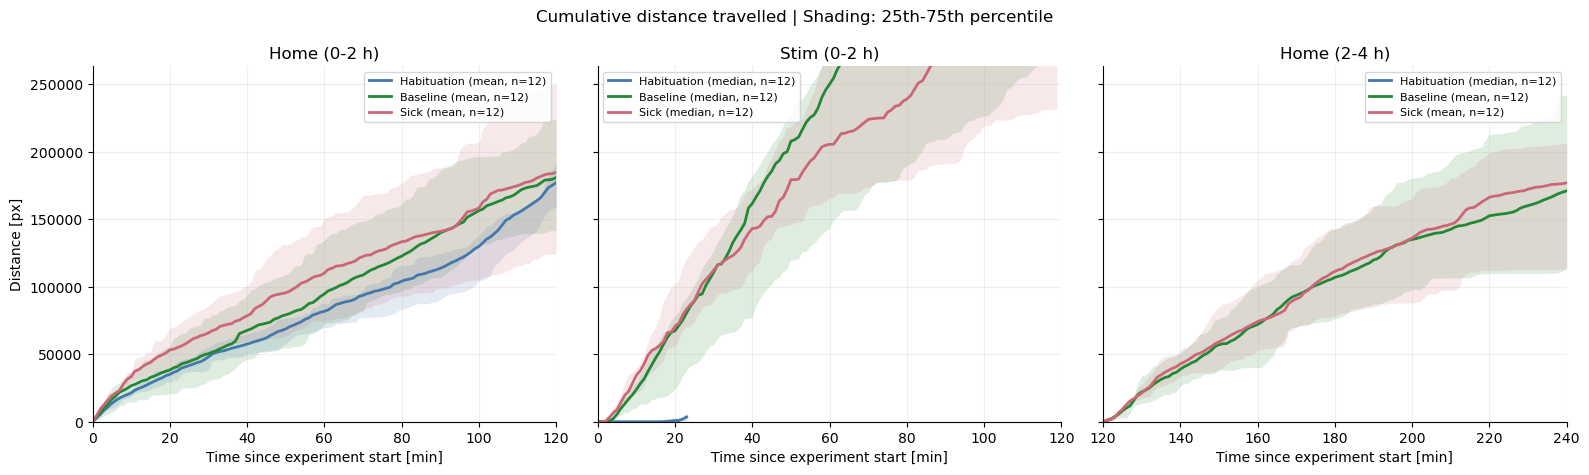

In [237]:
fig, axes = plot_timecourse('cumsum_speed', 'Cumulative distance travelled', 'Distance [px]')
save_plot_svg(fig, 'cumsum_speed_timecourse_home_0_2h_stim_0_2h_home_2_4h.svg')


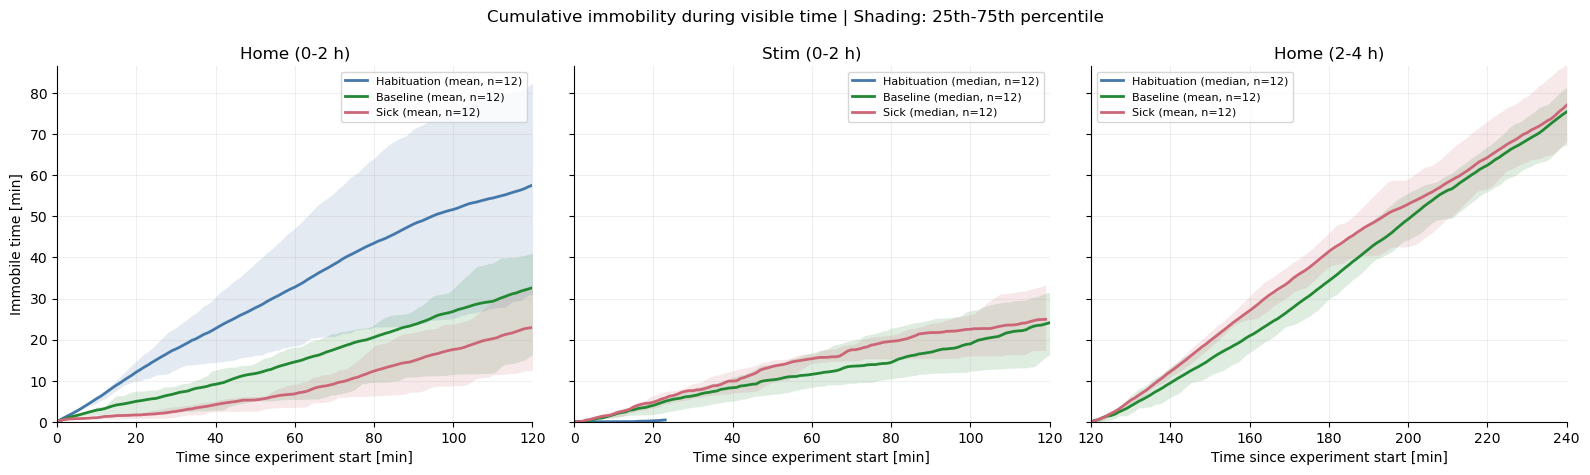

In [238]:
fig, axes = plot_timecourse('cumsum_immobile', 'Cumulative immobility during visible time', 'Immobile time [min]')
save_plot_svg(fig, 'cumsum_immobile_timecourse_home_0_2h_stim_0_2h_home_2_4h.svg')


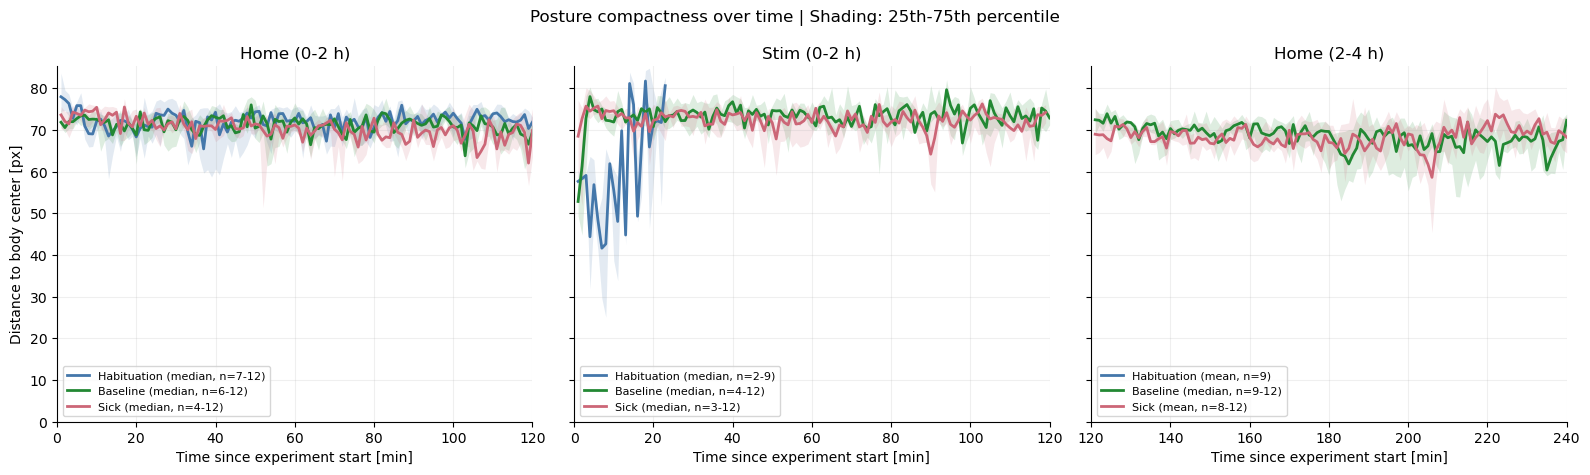

In [239]:
fig, axes = plot_timecourse('posture_compactness', 'Posture compactness over time', 'Distance to body center [px]')
save_plot_svg(fig, 'posture_compactness_timecourse_home_0_2h_stim_0_2h_home_2_4h.svg')


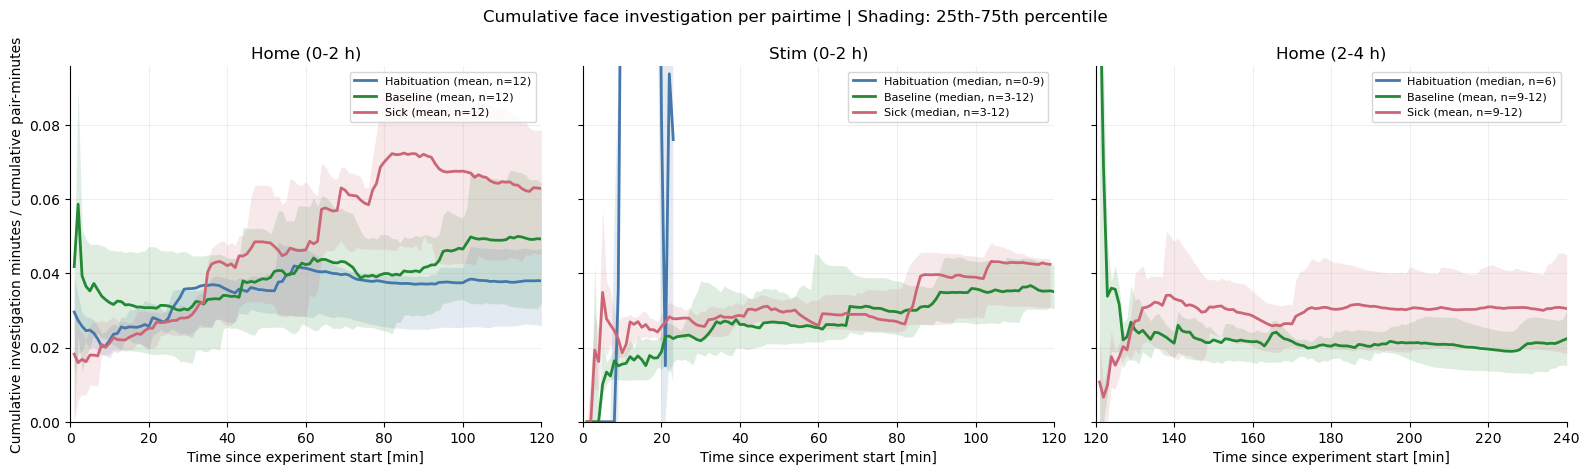

In [240]:
fig, axes = plot_timecourse('face_inv_time_per_pairtime', 'Cumulative face investigation per pairtime', 'Cumulative investigation minutes / cumulative pair-minutes')
save_plot_svg(fig, 'face_inv_time_per_pairtime_timecourse_home_0_2h_stim_0_2h_home_2_4h.svg')


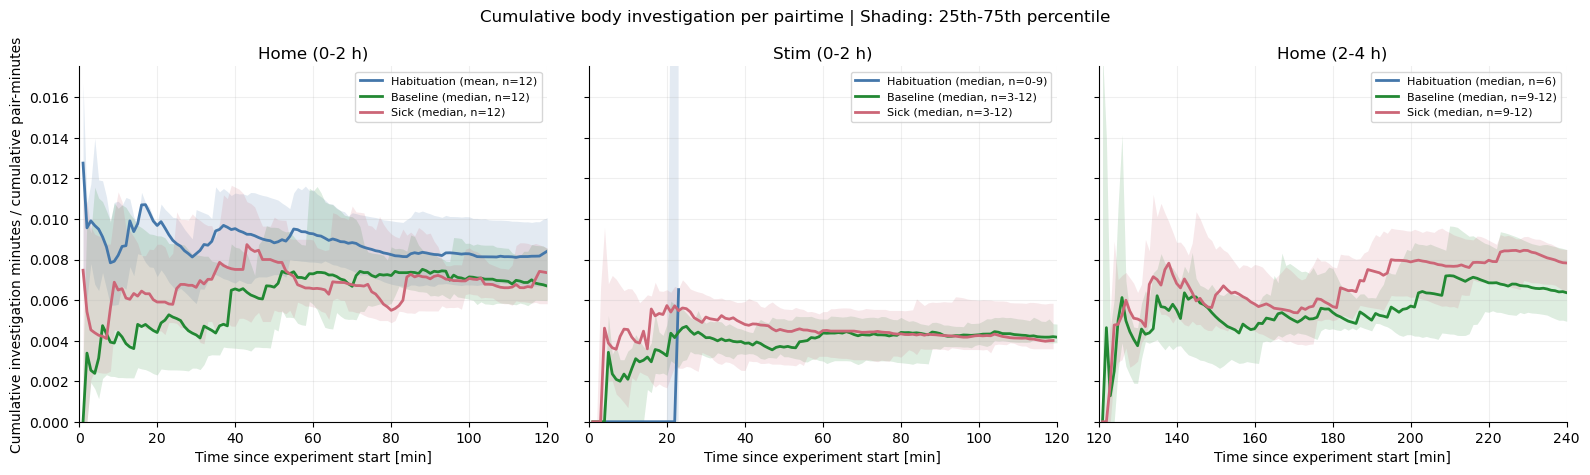

In [241]:
fig, axes = plot_timecourse('body_inv_time_per_pairtime', 'Cumulative body investigation per pairtime', 'Cumulative investigation minutes / cumulative pair-minutes')
save_plot_svg(fig, 'body_inv_time_per_pairtime_timecourse_home_0_2h_stim_0_2h_home_2_4h.svg')


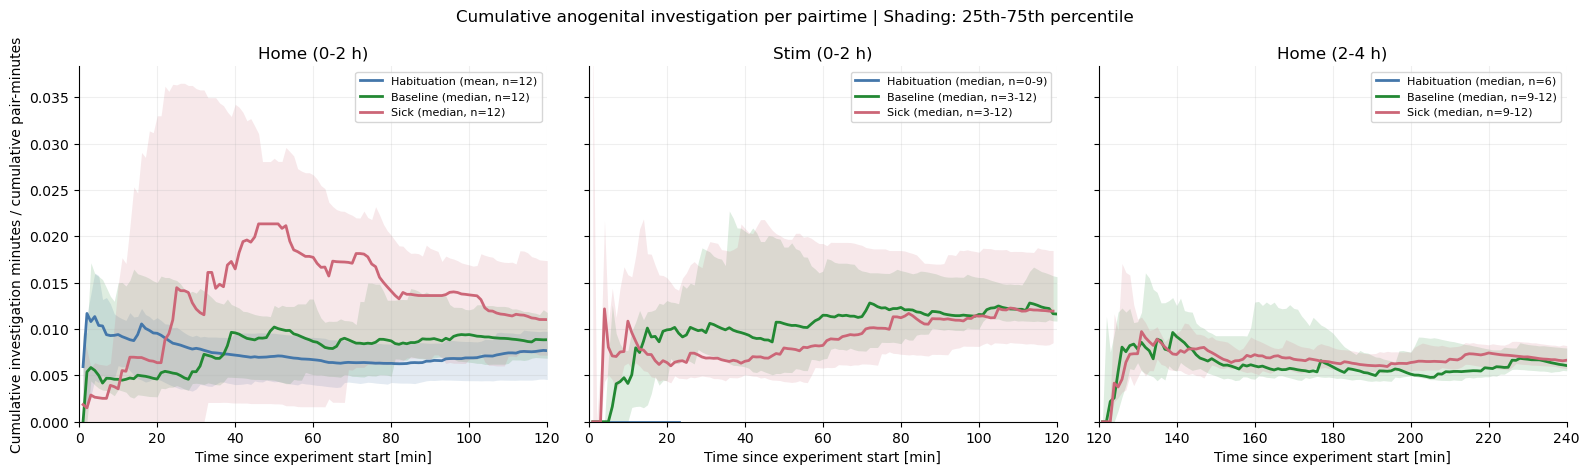

In [242]:
fig, axes = plot_timecourse('anogenital_inv_time_per_pairtime', 'Cumulative anogenital investigation per pairtime', 'Cumulative investigation minutes / cumulative pair-minutes')
save_plot_svg(fig, 'anogenital_inv_time_per_pairtime_timecourse_home_0_2h_stim_0_2h_home_2_4h.svg')


## Social distance: Home 2-4 h

`social_distance` ist je Maus und Frame die mittlere euklidische Center-Distanz zu allen anderen aktuell sichtbaren Maeusen mit endlichen `center_x`- und `center_y`-Koordinaten. Der eigene Center muss ebenfalls sichtbar und gueltig sein. Ohne Partner bleibt der Wert NaN; bei zwei sichtbaren Maeusen gilt ihr gemeinsamer Abstand, bei drei Maeusen pro Maus der Mittelwert ihrer zwei Abstaende. Einheit: Pixel. Die Partnerzahl-Normierung erfolgt bereits pro Frame; eine weitere Division durch Pairtime ist hier nicht sinnvoll.

Auswertung nur Home, Frames 216000:432000; kuerzere Aufnahmen verwenden den Rest. Berechnung ausschliesslich innerhalb derselben Aufnahme, niemals zwischen Kohorten. `social_distance_frames[(cohort, day)]` speichert die frameweisen Werte; `data_dict_social_distance` die zeitlichen Mittelwerte pro Maus sowie die Anzahl gueltiger Frames.

Scatter: je Maus der Mean ueber alle gueltigen Frames ihres verfuegbaren Fensters, Farben nach Kohorte; Linien zeigen Mean und Median der Mausmittelwerte. Cumsum: zuerst der Mean aller gueltigen Mauswerte eines Frames ueber die Kohorten, dann die Summe dieser Frame-Mittelwerte. Die Tageskurven enden an der gemeinsamen Dauer ihrer vorhandenen Aufnahmen; laengere individuelle Verlaeufe bleiben gespeichert. Habituation, Baseline und Sick werden gemeinsam dargestellt.

Die kumulierte Kurve ist eine Summe von Abstandsmessungen in px, keine zurueckgelegte Strecke. Ihre Hoehe haengt von FPS und auswertbarer Dauer ab. Frames ohne eine einzige gueltige Distanz werden ausgelassen, nicht als Abstand null interpretiert; der Plot markiert solche Luecken. Datenabdeckung und Anzahl beitragender Maeuse werden ausgegeben. Unterschiede in Sichtbarkeit koennen die Zusammenfassung weiterhin beeinflussen; die Maeuse innerhalb einer Kohorte sind keine unabhaengigen Replikate.


In [184]:
import numpy as np
import pandas as pd
from tqdm import tqdm
from variables import FPS

SOCIAL_DISTANCE_START = 216000
SOCIAL_DISTANCE_STOP = 432000


def calculate_social_distance(frame, experiment_name):
    """Mittlerer Abstand zu gueltigen sichtbaren Partnern pro Maus/Frame, in px."""
    recording = frame.xs(experiment_name, axis=1, level="name")
    individuals = recording.columns.get_level_values("individuals").unique()
    x = np.column_stack([recording[(mouse, "center_x")].to_numpy(dtype=float) for mouse in individuals])
    y = np.column_stack([recording[(mouse, "center_y")].to_numpy(dtype=float) for mouse in individuals])
    visible = np.column_stack([recording[(mouse, "visible")].to_numpy() == 1 for mouse in individuals])
    valid = visible & np.isfinite(x) & np.isfinite(y)
    sums = np.zeros(x.shape, dtype=float)
    partner_counts = np.zeros(x.shape, dtype=int)
    for i in range(len(individuals)):
        for j in range(i + 1, len(individuals)):
            pair_valid = valid[:, i] & valid[:, j]
            distances = np.zeros(len(frame), dtype=float)
            distances[pair_valid] = np.hypot(x[pair_valid, i] - x[pair_valid, j],
                                              y[pair_valid, i] - y[pair_valid, j])
            sums[:, i] += distances
            sums[:, j] += distances
            partner_counts[:, i] += pair_valid
            partner_counts[:, j] += pair_valid
    social_distance = np.divide(sums, partner_counts,
                                out=np.full(x.shape, np.nan), where=partner_counts > 0)
    result = pd.DataFrame(social_distance, index=frame.index, columns=individuals)
    result.columns.name = "individuals"
    return result


def social_distance_metadata(frame):
    name = frame.columns.get_level_values("name").unique().item()
    parts = name.split("_")
    if len(parts) == 11:
        parts = ["".join(parts[:3]), "".join(parts[3:6]), *parts[6:10]]
    return name, parts[3], parts[4], parts[5]


social_distance_frames = {}
data_dict_social_distance = {}
for file in tqdm(experiment_files):
    distance_df = pd.read_hdf(file, key="metrics")
    name, cohort, day, condition = social_distance_metadata(distance_df)
    if condition != "home" or day not in ("habituation", "baseline", "sick"):
        continue
    window = distance_df.iloc[SOCIAL_DISTANCE_START:SOCIAL_DISTANCE_STOP]
    if len(window) < SOCIAL_DISTANCE_STOP - SOCIAL_DISTANCE_START:
        print(f"Social distance {cohort}/{day}: nur {len(window)} Frames "
              f"({len(window) / FPS / 60:.1f} min) in Home 2-4 h. Datei: {file}")
    if window.empty:
        continue
    key = (cohort, day)
    if key in social_distance_frames:
        raise ValueError(f"Mehrere Home-Aufnahmen fuer {key}; bitte Dateien gezielt auswaehlen.")
    distances = calculate_social_distance(window, name)
    social_distance_frames[key] = distances
    target = data_dict_social_distance.setdefault(cohort, {}).setdefault(day, {}).setdefault("home", {})
    for individual in distances:
        values = distances[individual].to_numpy()
        finite = values[np.isfinite(values)]
        target[individual] = {
            "mean_social_distance": np.mean(finite) if finite.size else np.nan,
            "social_distance_valid_frames": finite.size,
            "social_distance_available_frames": len(values),
        }
        print(f"{cohort}/{day}/{individual}: social_distance in {finite.size}/{len(values)} Frames "
              f"({100 * finite.size / len(values):.1f}%) auswertbar.")


  8%|▊         | 2/24 [00:07<01:25,  3.89s/it]

c1/baseline/mouse1: social_distance in 183299/216000 Frames (84.9%) auswertbar.
c1/baseline/mouse2: social_distance in 184991/216000 Frames (85.6%) auswertbar.
c1/baseline/mouse3: social_distance in 175456/216000 Frames (81.2%) auswertbar.


 17%|█▋        | 4/24 [00:12<01:06,  3.33s/it]

c1/habituation/mouse1: social_distance in 168380/216000 Frames (78.0%) auswertbar.
c1/habituation/mouse2: social_distance in 174342/216000 Frames (80.7%) auswertbar.
c1/habituation/mouse3: social_distance in 194325/216000 Frames (90.0%) auswertbar.


 21%|██        | 5/24 [00:17<01:12,  3.83s/it]

c1/sick/mouse1: social_distance in 193542/216000 Frames (89.6%) auswertbar.
c1/sick/mouse2: social_distance in 186653/216000 Frames (86.4%) auswertbar.
c1/sick/mouse3: social_distance in 179982/216000 Frames (83.3%) auswertbar.


... (14 outputs left out)

 92%|█████████▏| 22/24 [01:22<00:06,  3.32s/it]

Social distance c4/habituation: nur 2671 Frames (1.5 min) in Home 2-4 h. Datei: Z:\n2023_odor_related_behavior\2026_sick_behavior\raw\c4\habituation\20261027_100105_641117_mice_c4_habituation_home\metric_analysis\experiment.h5
c4/habituation/mouse1: social_distance in 312/2671 Frames (11.7%) auswertbar.
c4/habituation/mouse2: social_distance in 10/2671 Frames (0.4%) auswertbar.
c4/habituation/mouse3: social_distance in 302/2671 Frames (11.3%) auswertbar.


100%|██████████| 24/24 [01:30<00:00,  3.76s/it]

c4/sick/mouse1: social_distance in 133032/216000 Frames (61.6%) auswertbar.
c4/sick/mouse2: social_distance in 133521/216000 Frames (61.8%) auswertbar.
c4/sick/mouse3: social_distance in 104583/216000 Frames (48.4%) auswertbar.


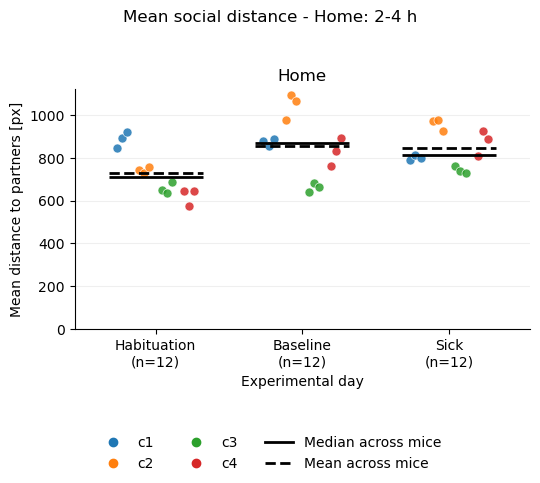

In [243]:
fig, axes = plot_metric(data_dict_social_distance, 'mean_social_distance', 'Mean social distance - Home: 2-4 h', 'Mean distance to partners [px]', conditions=('home',))
save_plot_svg(fig, 'mean_social_distance_scatter_home_2_4h.svg')


In [244]:
def summarize_social_distance_timecourse(recordings):
    """Frame-Mittel ueber Maeuse, danach Cumsum; gleiche Dauer je Tageskurve."""
    summary = {}
    for day in ("habituation", "baseline", "sick"):
        tables = [table for (_, recording_day), table in recordings.items() if recording_day == day]
        if not tables:
            continue
        n_frames = min(len(table) for table in tables)
        if n_frames == 0:
            continue
        # Jede Spalte ist eine Maus; Paarabstaende wurden bereits pro Aufnahme berechnet.
        matrix = np.column_stack([table.iloc[:n_frames].to_numpy(dtype=float) for table in tables])
        n_valid = np.isfinite(matrix).sum(axis=1)
        frame_mean = np.divide(np.nansum(matrix, axis=1), n_valid,
                               out=np.full(n_frames, np.nan), where=n_valid > 0)
        observed = np.isfinite(frame_mean)
        cumsum = np.cumsum(np.where(observed, frame_mean, 0.0))
        cumsum[~observed] = np.nan  # Luecken markieren; spaetere Beobachtungen bleiben nutzbar.
        summary[day] = pd.DataFrame({
            "experiment_minutes": (SOCIAL_DISTANCE_START + np.arange(1, n_frames + 1)) / FPS / 60,
            "mean_social_distance": frame_mean,
            "cumsum_mean_social_distance": cumsum,
            "n_mice": n_valid,
        })
        print(f"Social distance {day}: gemeinsame Dauer {n_frames / FPS / 60:.1f} min; "
              f"{np.count_nonzero(observed)}/{n_frames} Frames mit Abstand; "
              f"{n_valid.min()}-{n_valid.max()} Maeuse pro Frame.")
    return summary


social_distance_timecourse = summarize_social_distance_timecourse(social_distance_frames)


Social distance habituation: gemeinsame Dauer 1.5 min; 2671/2671 Frames mit Abstand; 5-10 Maeuse pro Frame.
Social distance baseline: gemeinsame Dauer 120.0 min; 215811/216000 Frames mit Abstand; 0-12 Maeuse pro Frame.
Social distance sick: gemeinsame Dauer 120.0 min; 216000/216000 Frames mit Abstand; 2-12 Maeuse pro Frame.


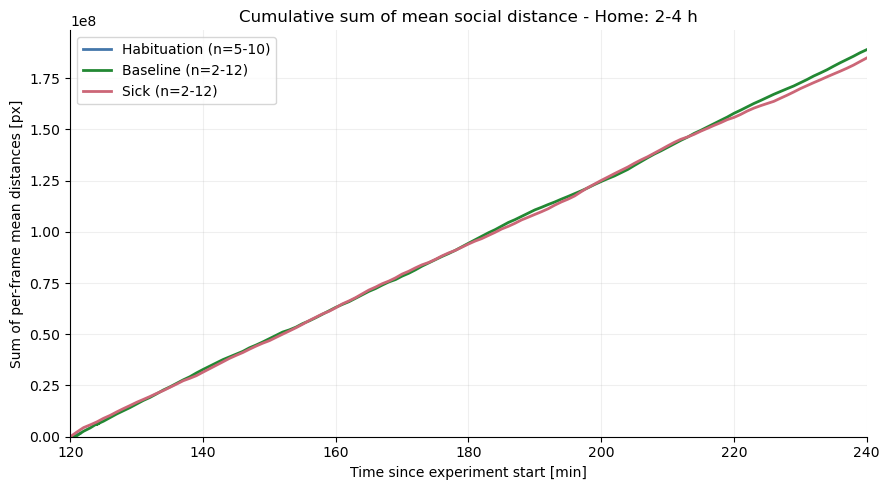

In [245]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
colors = {"habituation": "#4477AA", "baseline": "#228833", "sick": "#CC6677"}
for day, color in colors.items():
    table = social_distance_timecourse.get(day)
    if table is None or not np.any(np.isfinite(table["mean_social_distance"])):
        continue
    # Cumsum wurde aus ALLEN Frames berechnet. Nur Darstellung auf Minutenenden reduzieren.
    stride = max(1, int(FPS * 60))
    endpoints = np.unique(np.r_[np.arange(stride - 1, len(table), stride), len(table) - 1])
    # Auch kurze unbeobachtbare Luecken zwischen Minutenenden sichtbar unterbrechen.
    observed = np.isfinite(table["mean_social_distance"].to_numpy())
    gaps = np.flatnonzero(np.diff(np.r_[True, observed, True].astype(int)))
    indices = np.unique(np.r_[endpoints, gaps[gaps < len(table)],
                              (gaps - 1)[(gaps - 1) >= 0]])
    x = table["experiment_minutes"].to_numpy()[indices]
    y = table["cumsum_mean_social_distance"].to_numpy()[indices]
    if observed[0]:
        x = np.r_[SOCIAL_DISTANCE_START / FPS / 60, x]
        y = np.r_[0.0, y]
    valid_counts = table.loc[table["n_mice"] > 0, "n_mice"]
    n_min, n_max = valid_counts.min(), valid_counts.max()
    n_label = str(n_min) if n_min == n_max else f"{n_min}-{n_max}"
    ax.plot(x, y, color=color, linewidth=2, label=f"{day.capitalize()} (n={n_label})")
ax.set_title("Cumulative sum of mean social distance - Home: 2-4 h")
ax.set_xlabel("Time since experiment start [min]")
ax.set_ylabel("Sum of per-frame mean distances [px]")
ax.set_xlim(SOCIAL_DISTANCE_START / FPS / 60, SOCIAL_DISTANCE_STOP / FPS / 60)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
if ax.lines:
    ax.legend()
else:
    ax.text(0.5, 0.5, "No valid partner distances", transform=ax.transAxes, ha="center")
fig.tight_layout()
plt.show()
save_plot_svg(fig, 'cumsum_mean_social_distance_home_2_4h.svg')


## Cohort means for all scatter plots

Run the single cell below after creating `data_dict`, `data_dict_home_second_2h`, `data_dict_theta_arc`, and `data_dict_social_distance`. It recreates all 46 scatter plots with one point per cohort, day, and condition: the arithmetic mean of the available mouse-slot values (mouse1-mouse3). Labels are not treated as persistent individual identities. Missing values are excluded; cohorts without valid values are omitted. Each cohort has equal weight in the black mean line, regardless of the number of valid mouse slots. n counts cohorts, not mice.

This averages the existing summary metrics: for a metric such as median speed, a point is the mean of the stored mouse-slot medians, not a median or mean recomputed from pooled frames. Pairtime-normalized investigation metrics retain their existing normalization. `cohort_mean_summary` records each mean and the number of contributing mouse slots. Original dictionaries and plots are preserved. Figures use English labels and are saved as SVG in the `cohort_mean` subfolder.


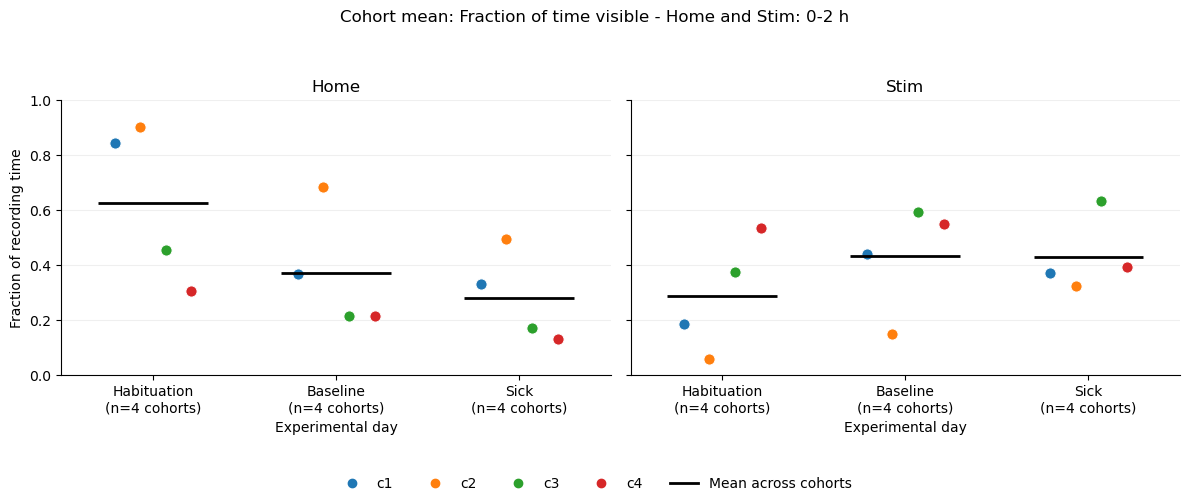

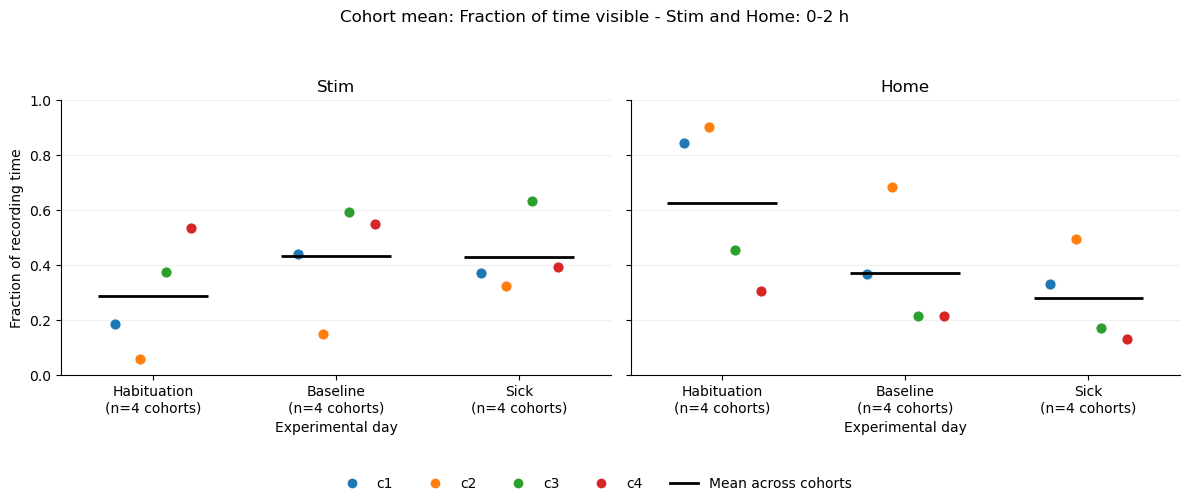

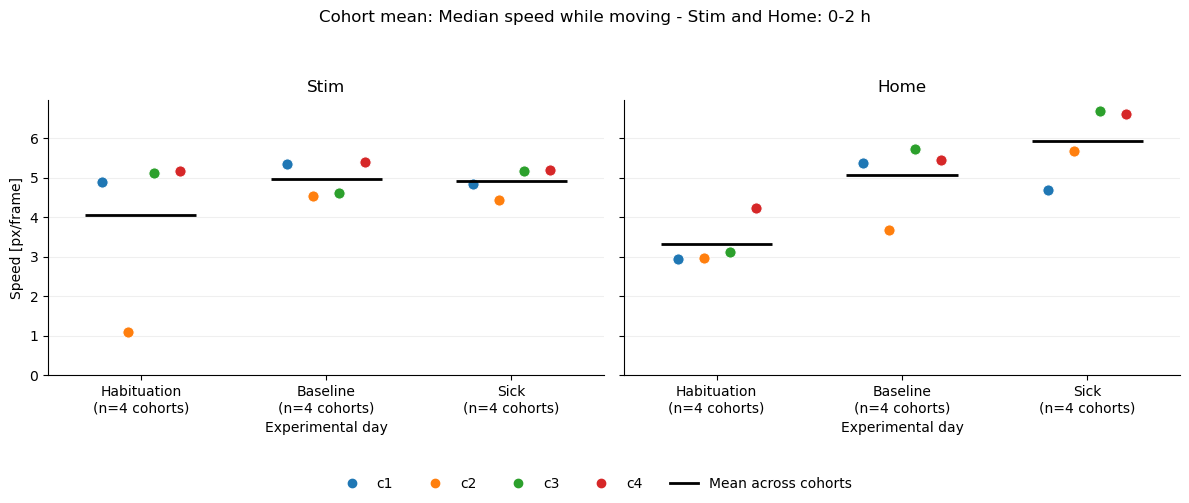

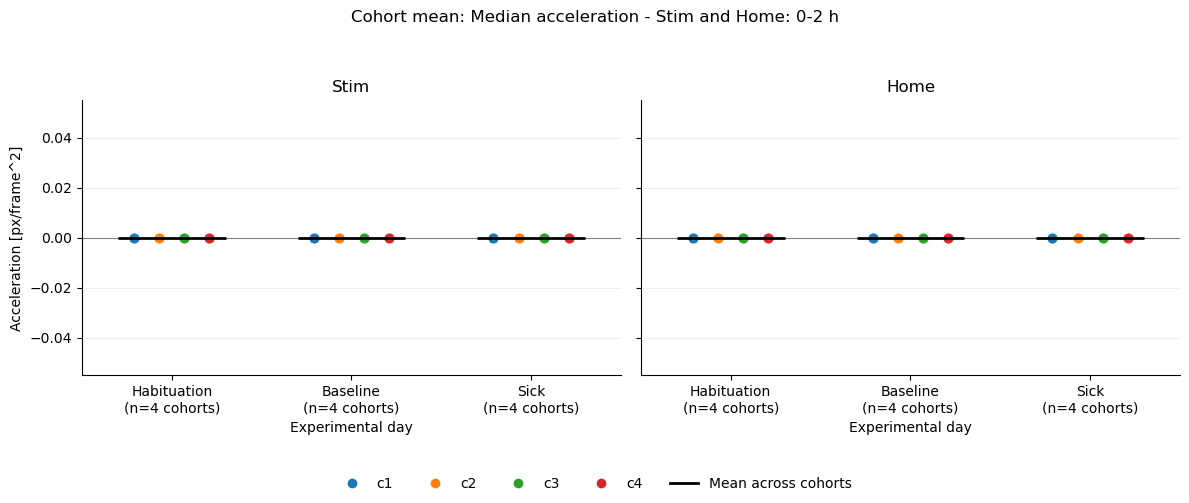

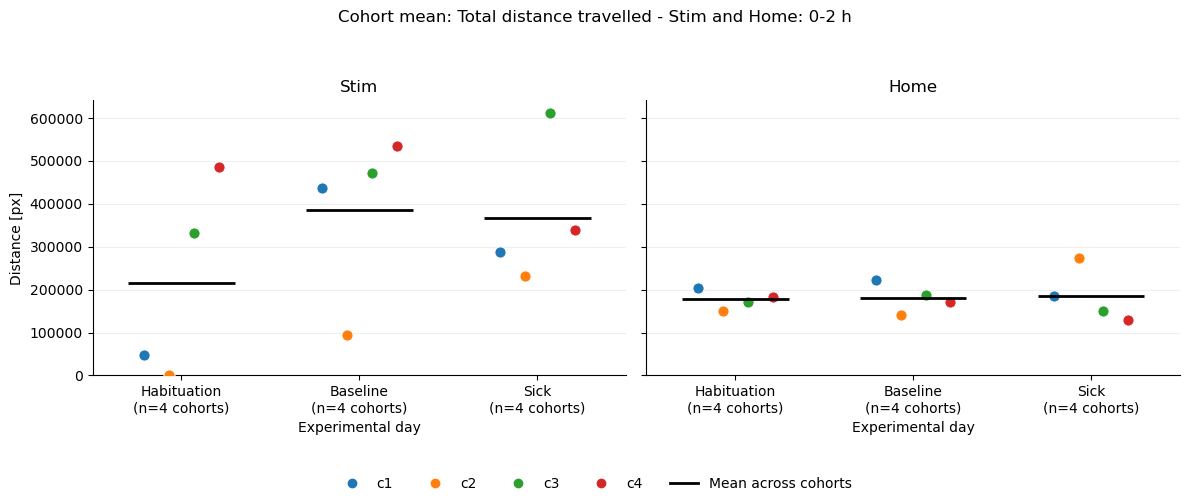

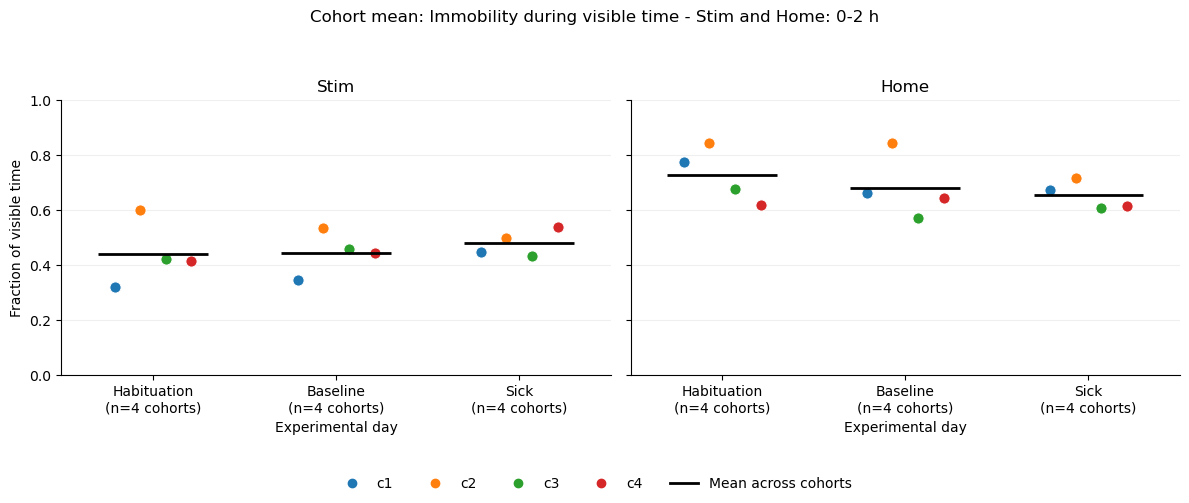

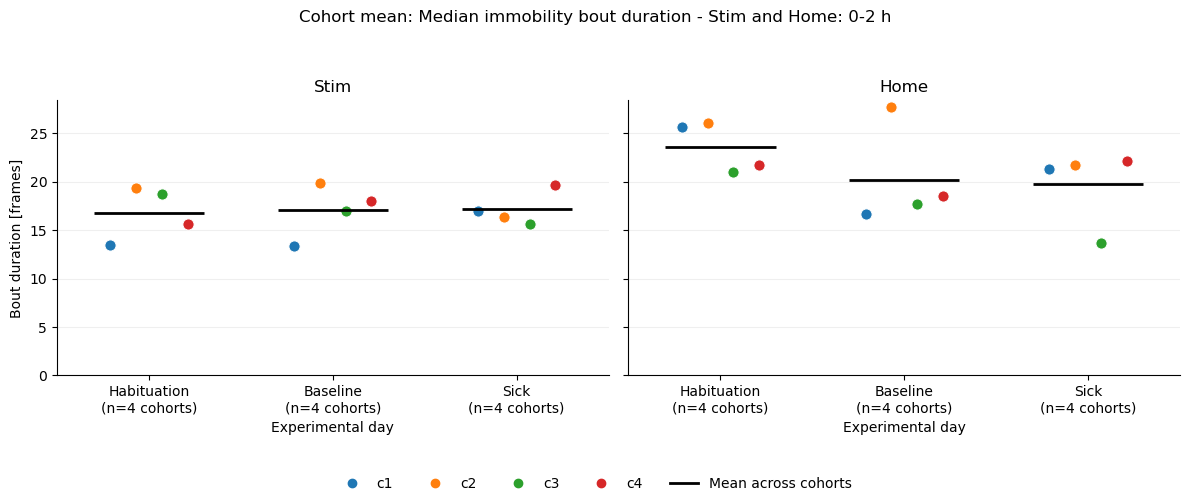

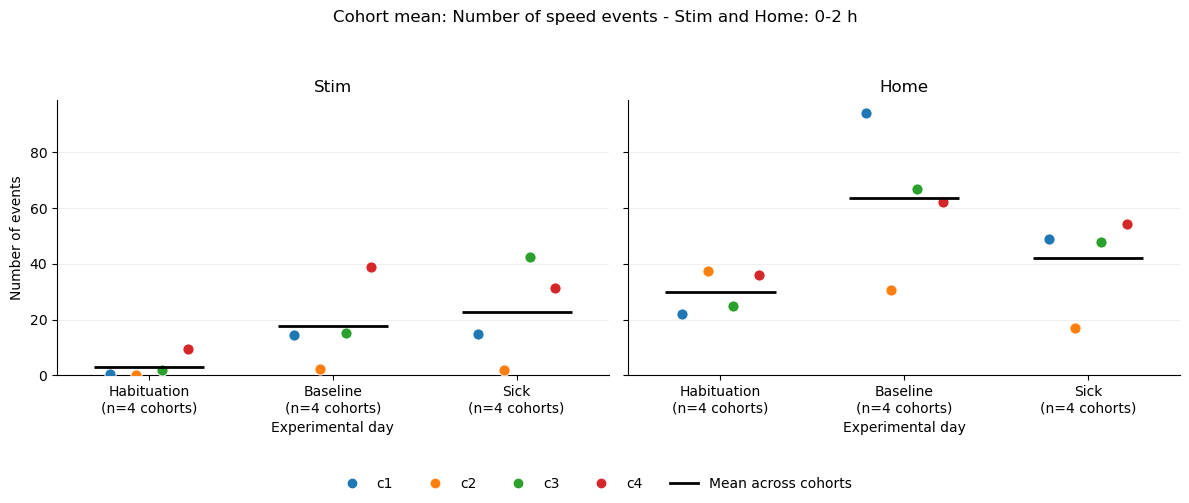

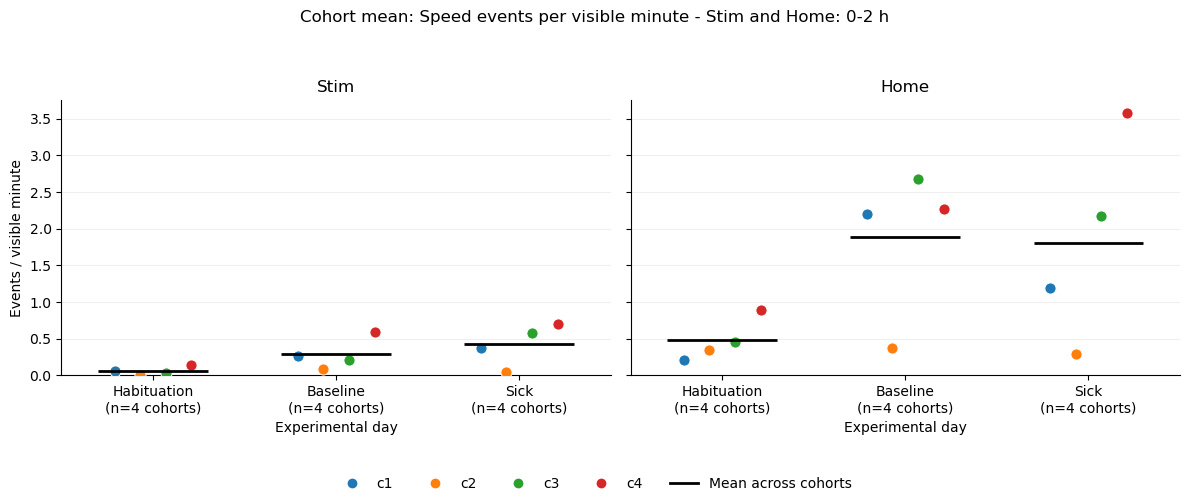

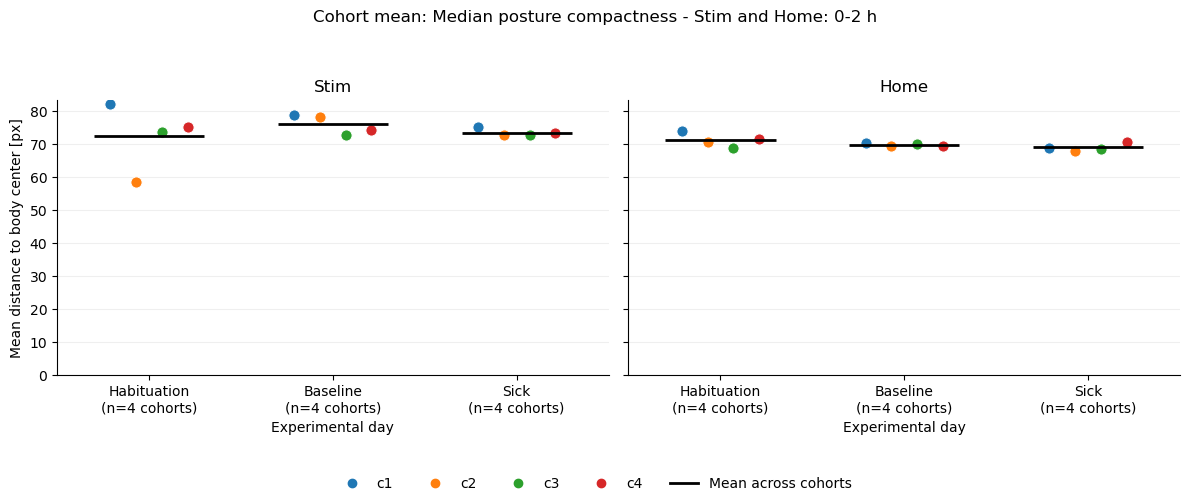

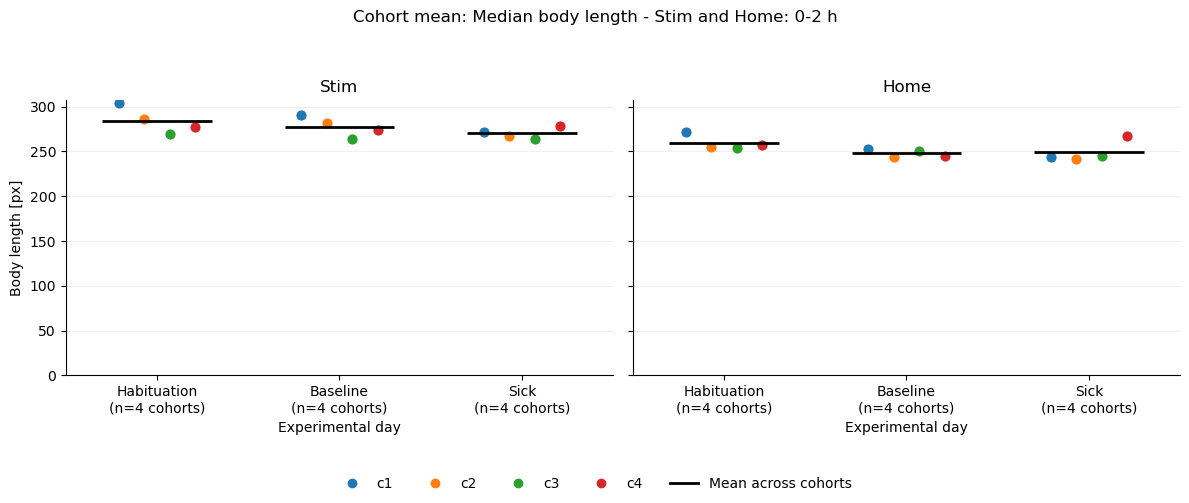

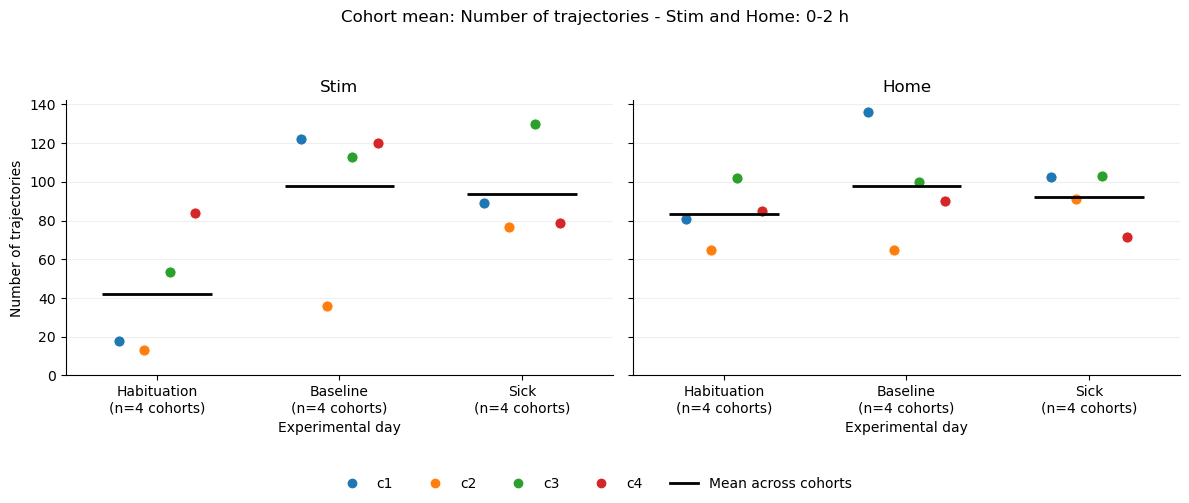

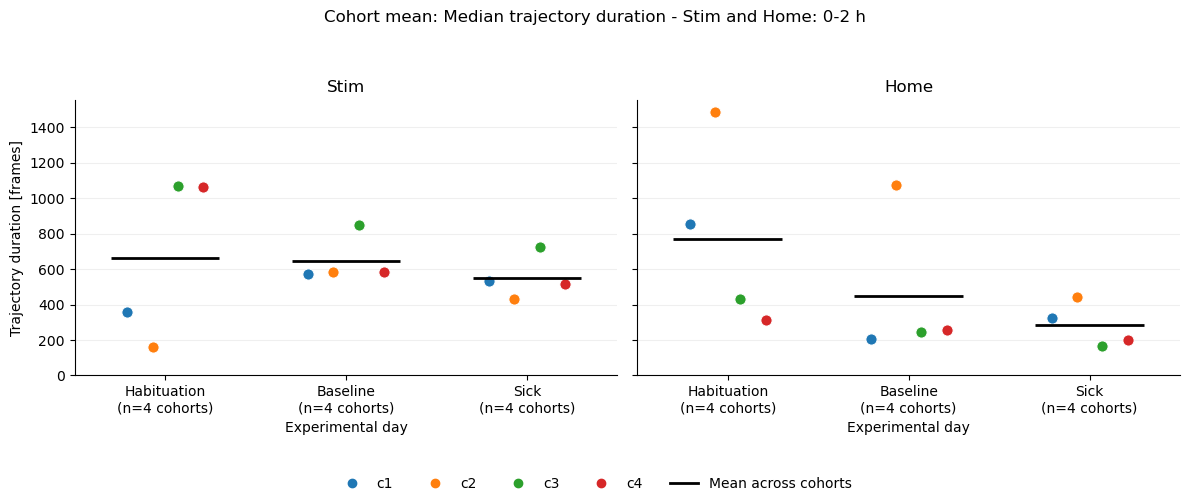

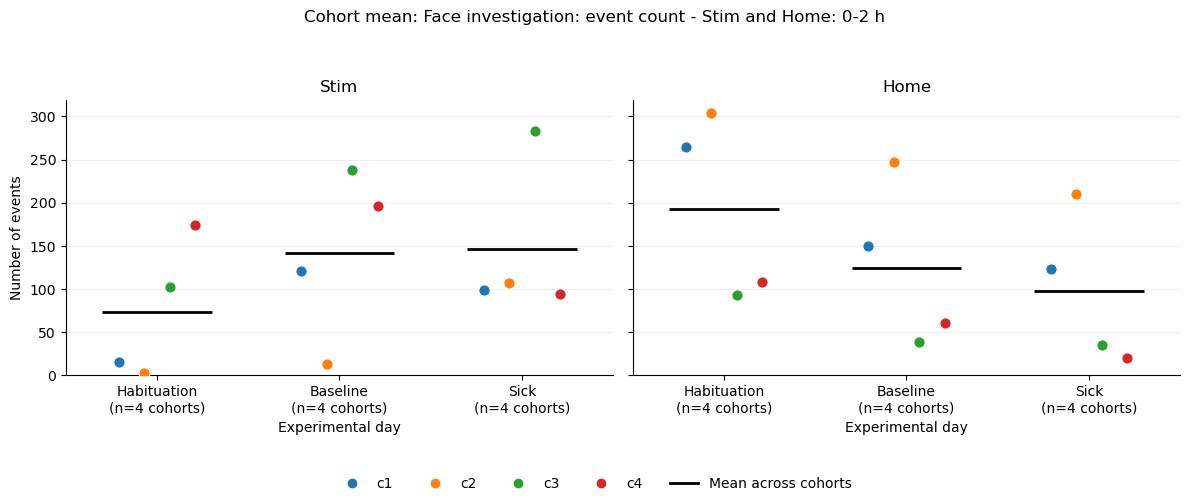

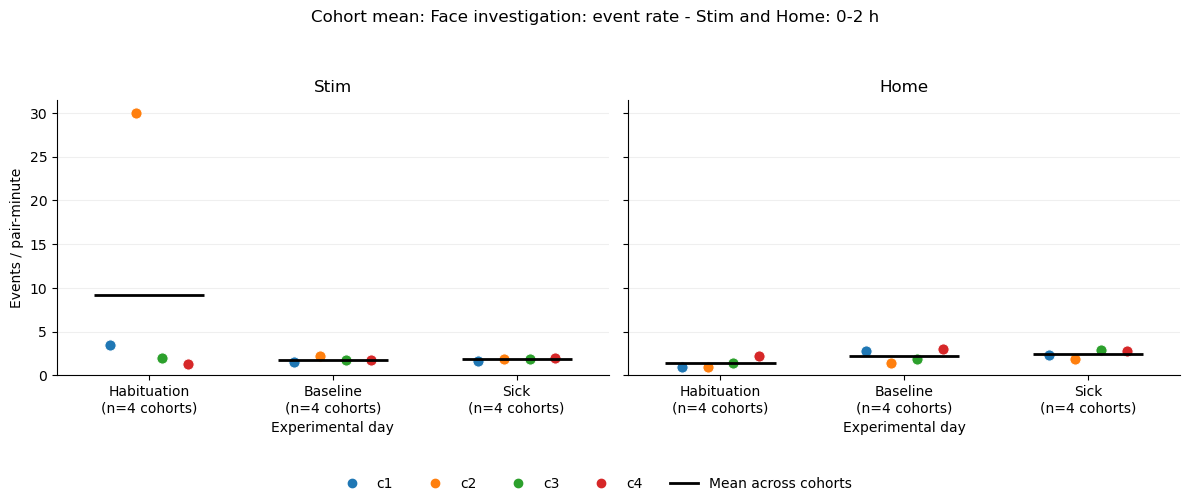

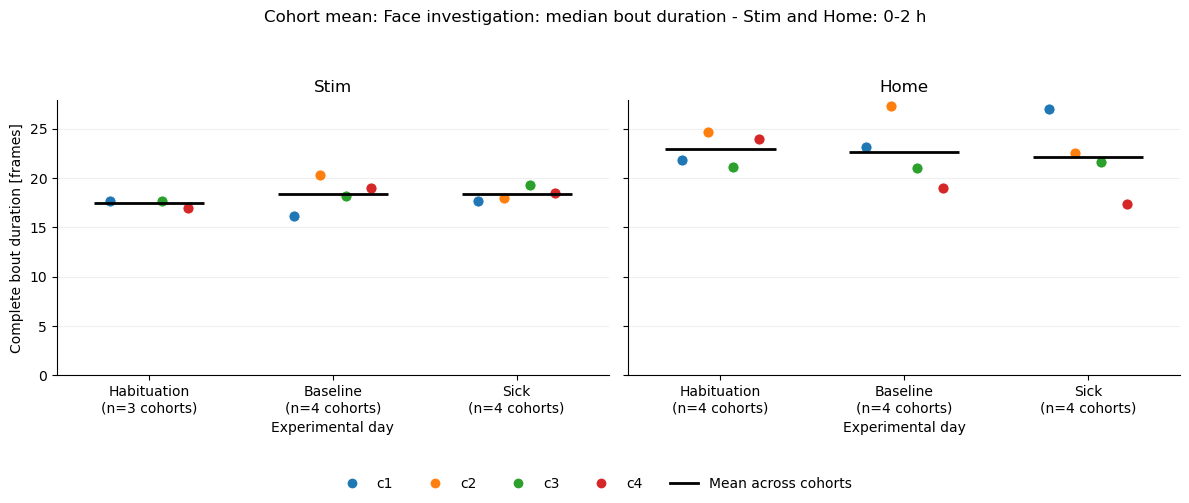

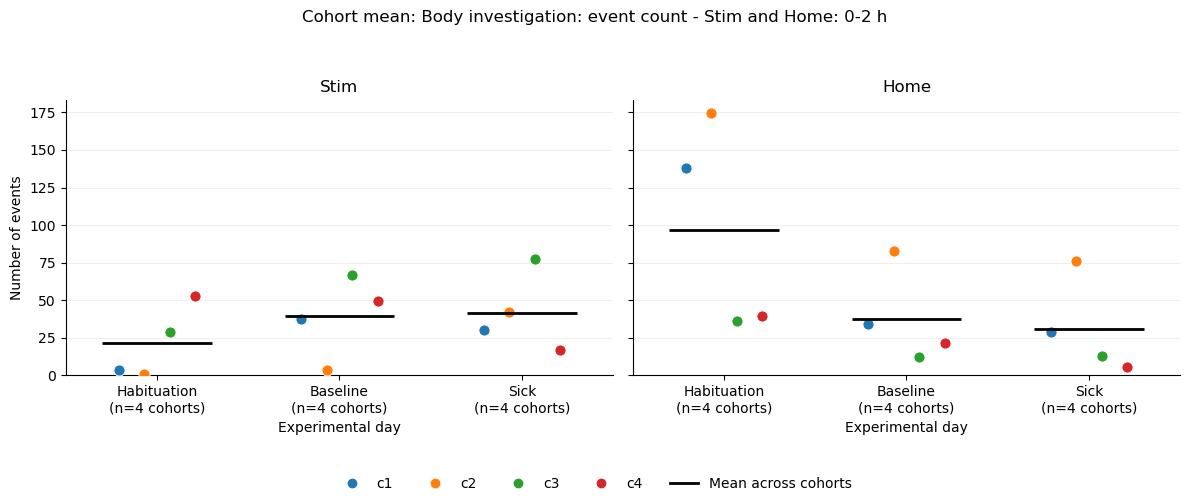

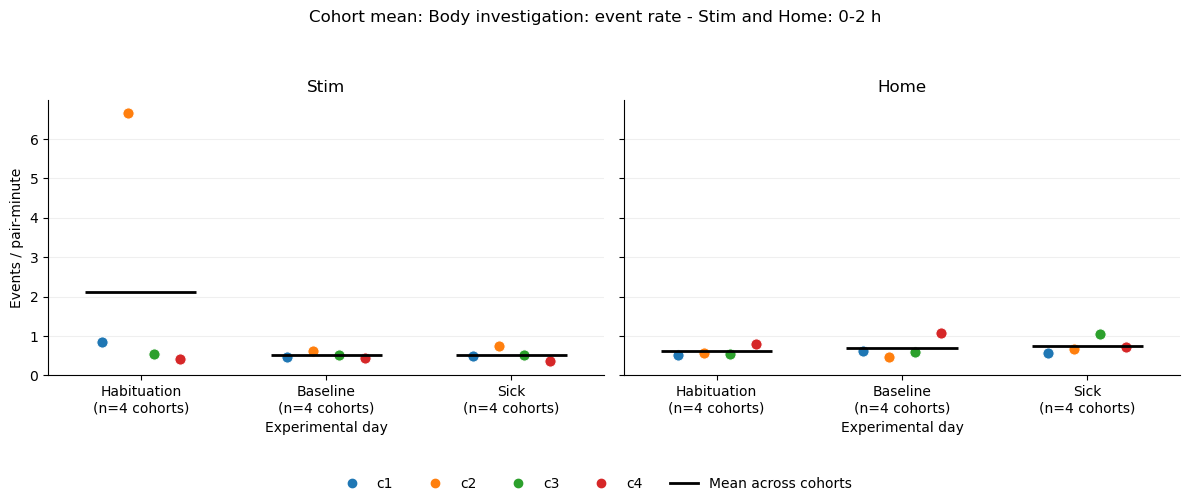

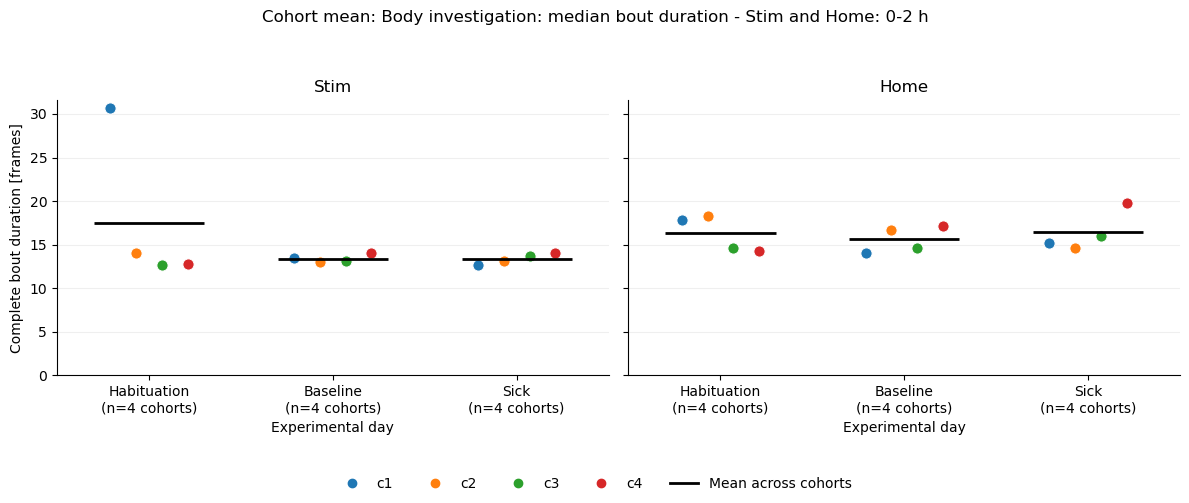

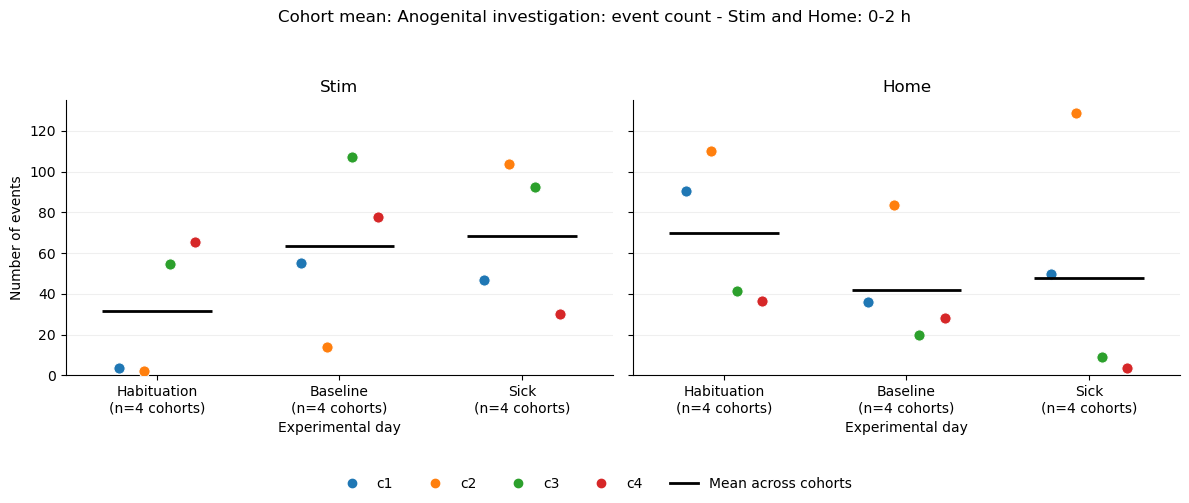

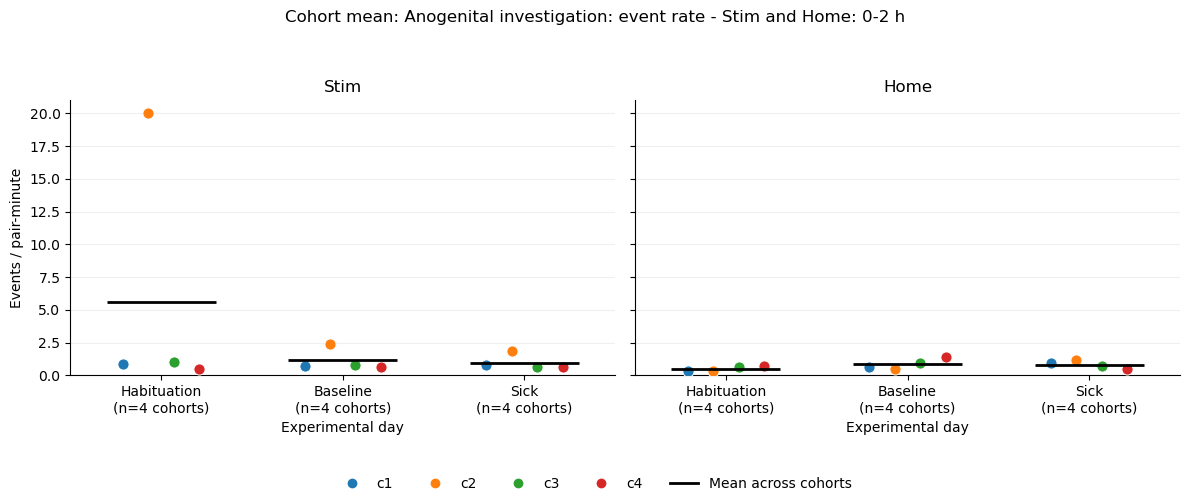

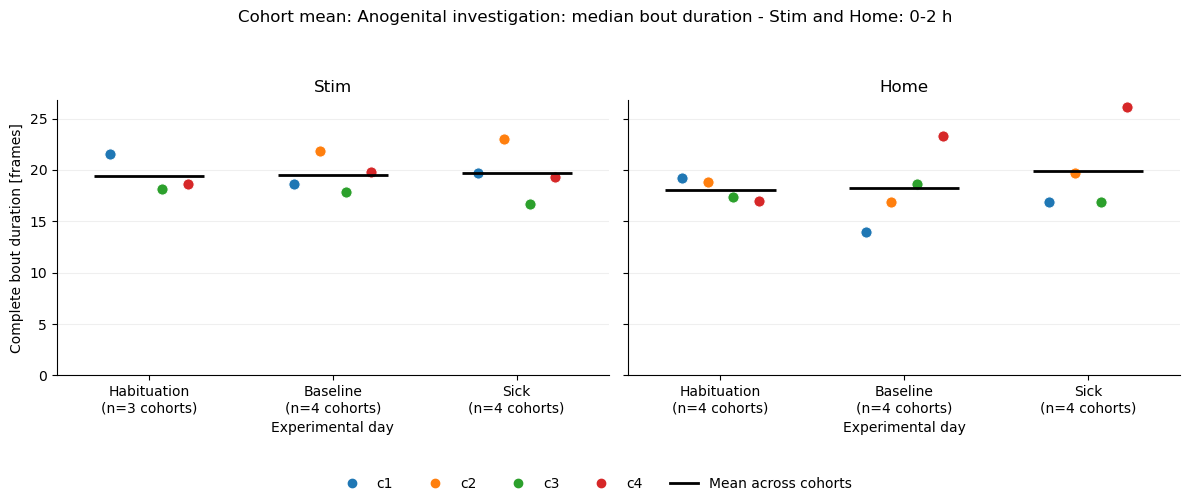

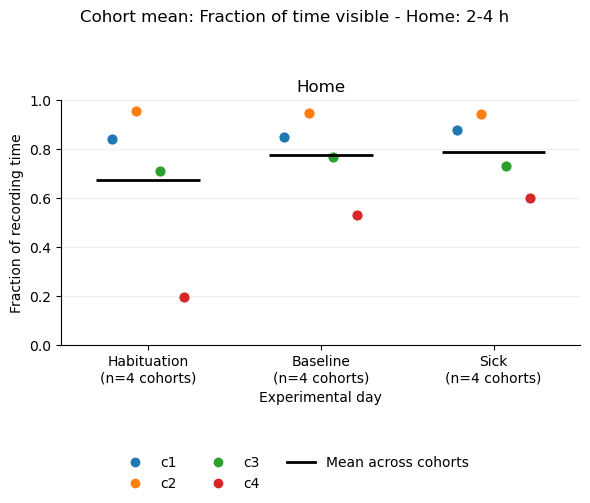

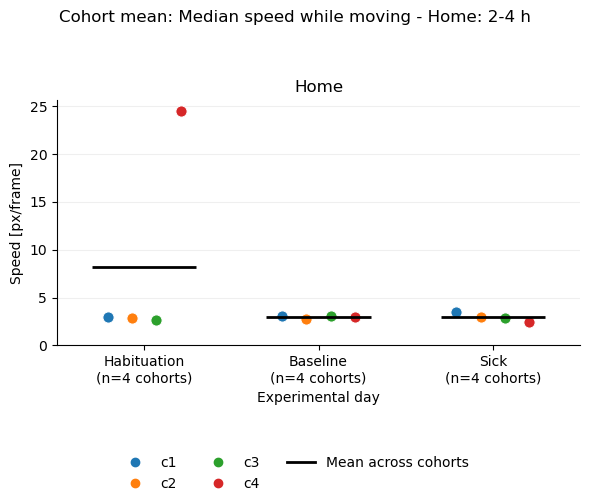

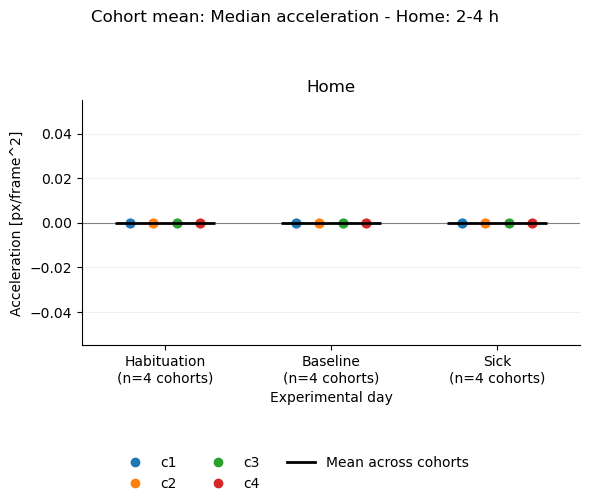

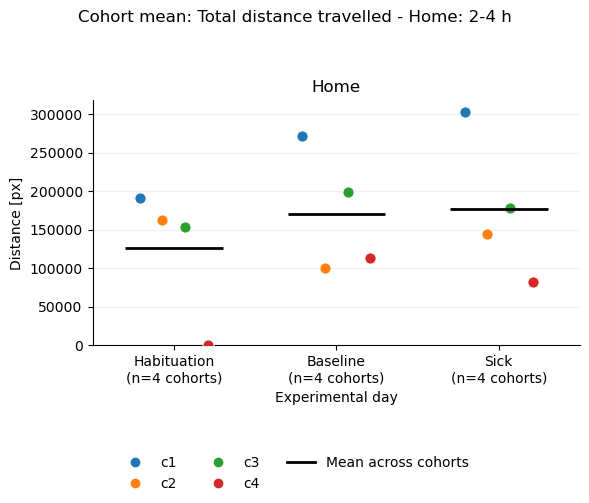

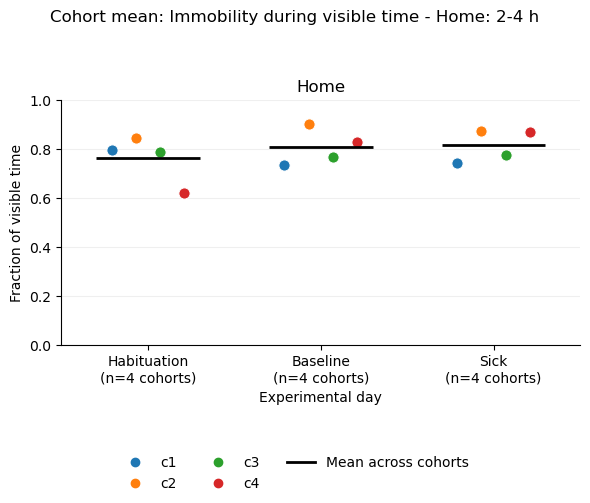

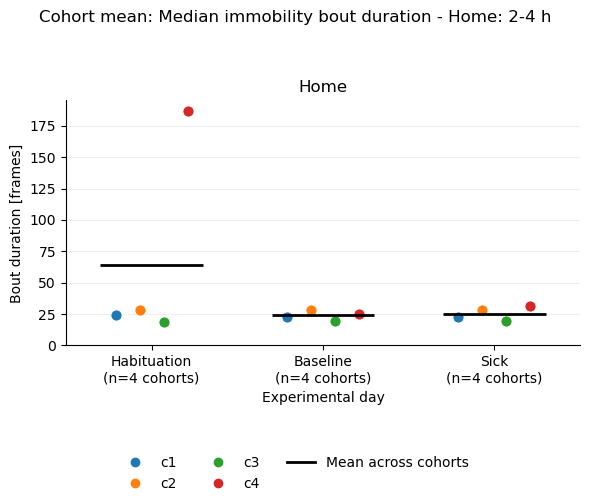

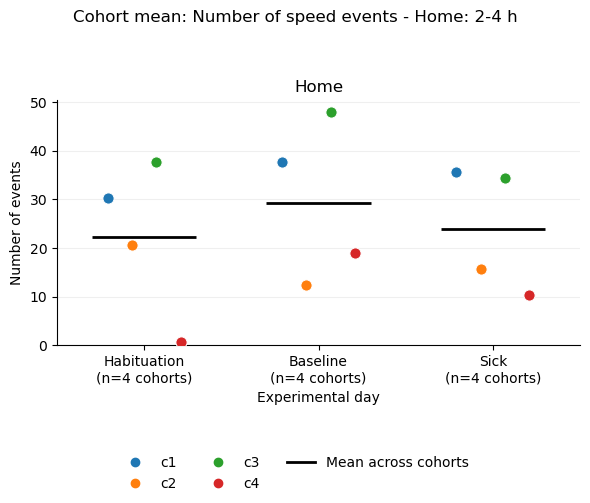

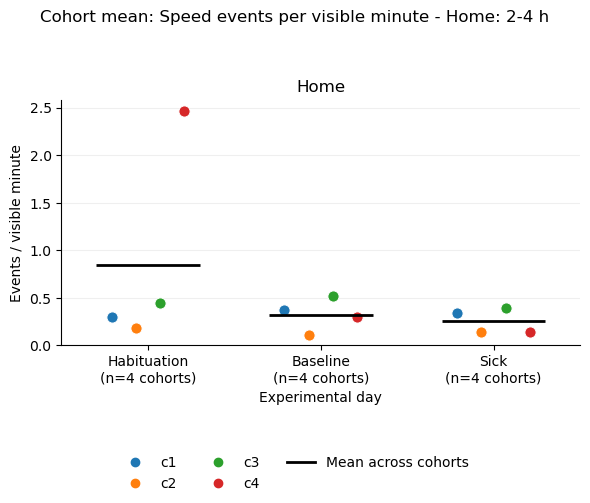

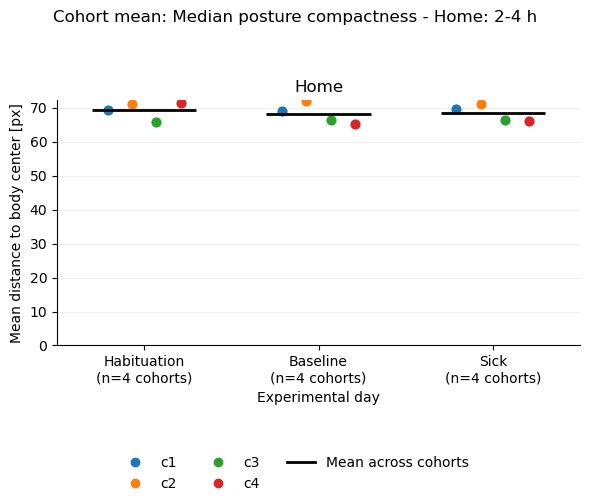

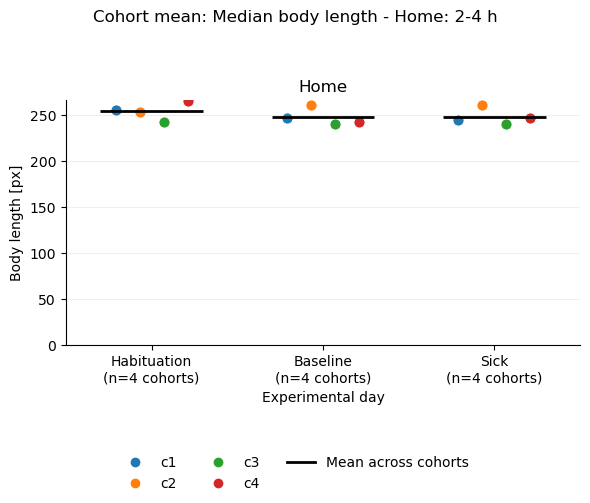

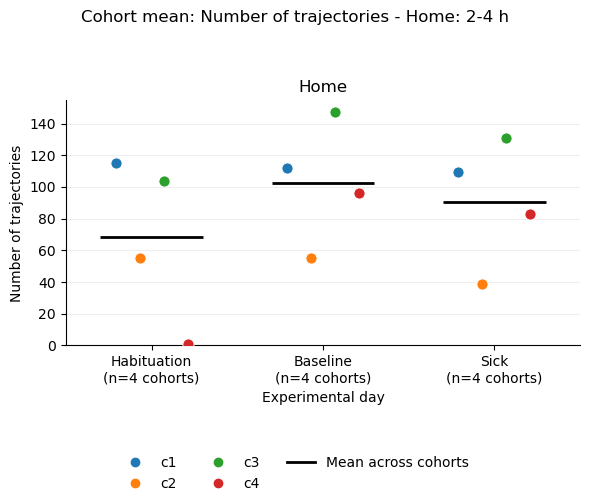

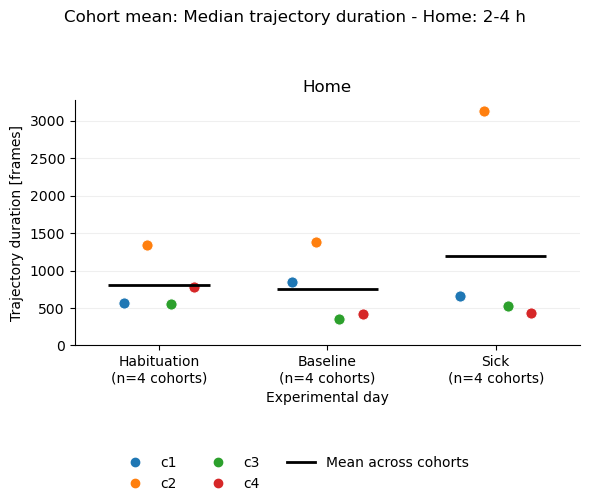

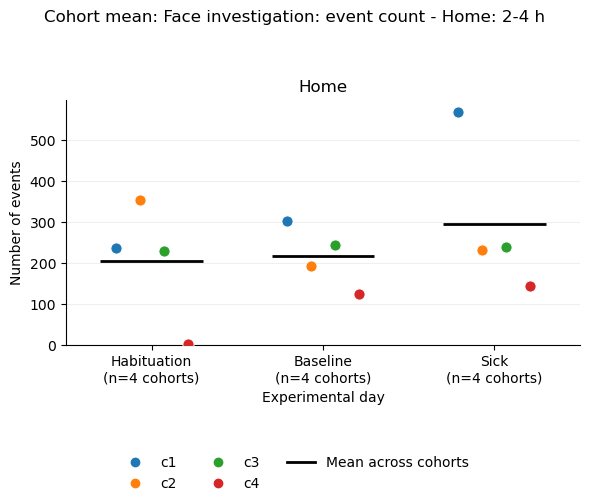

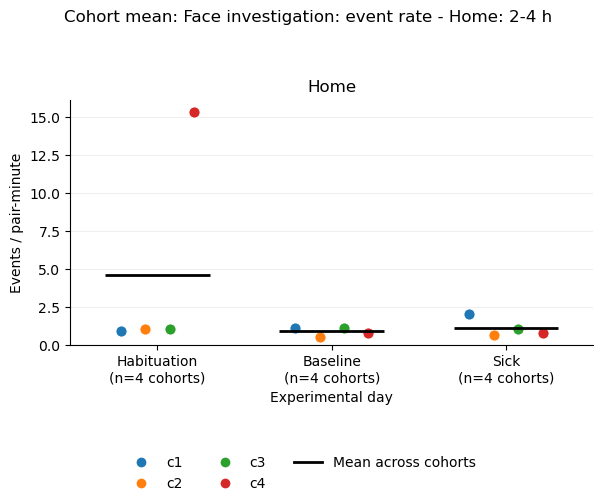

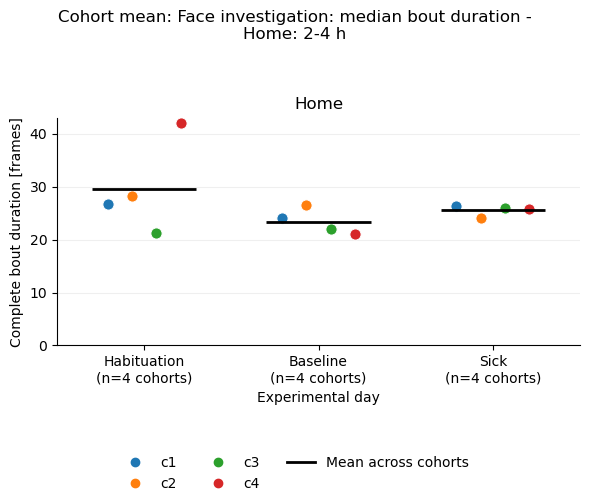

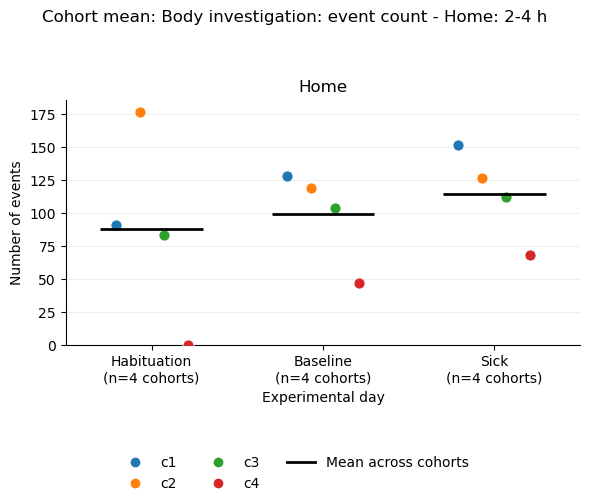

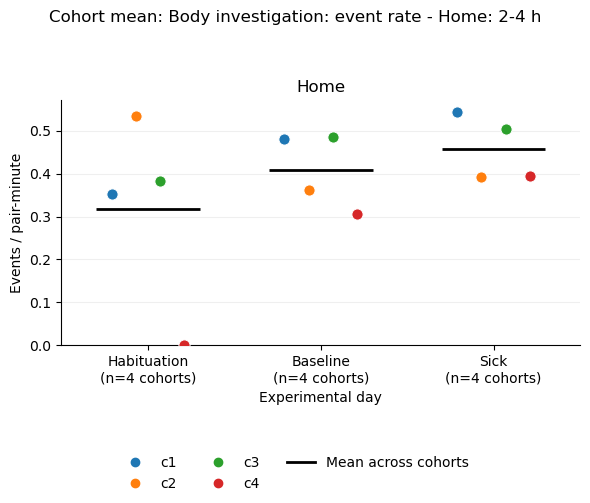

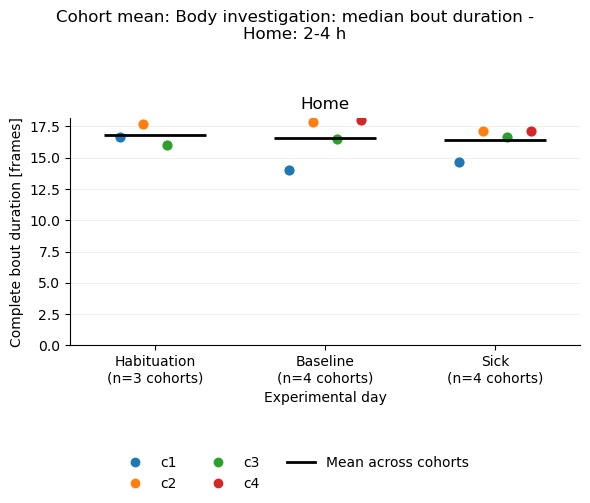

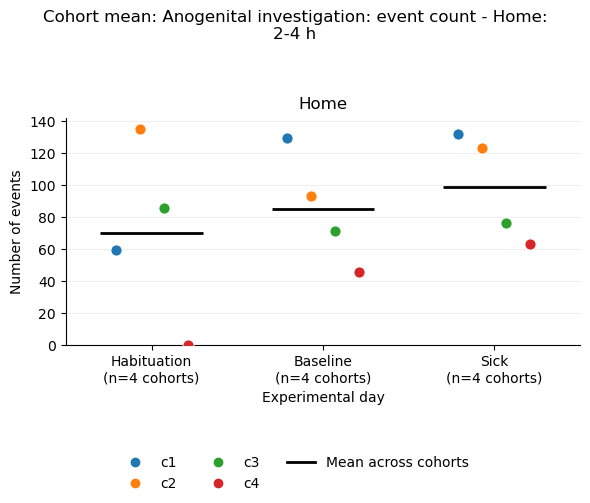

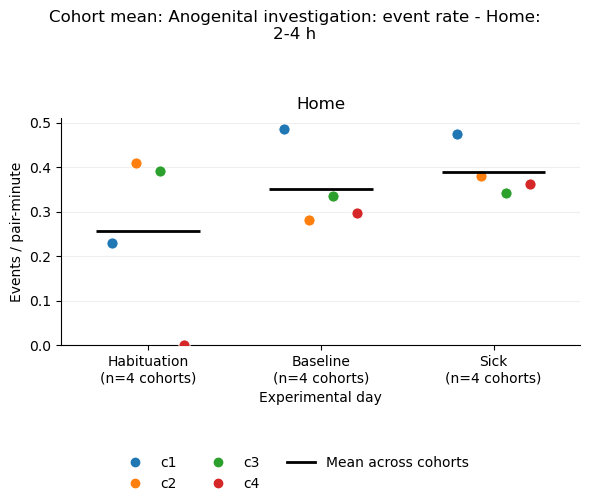

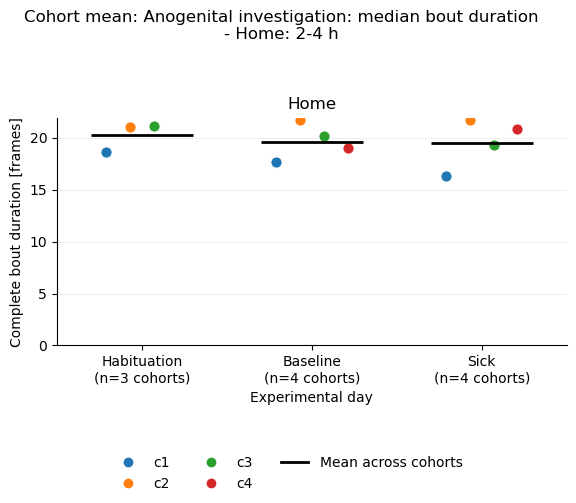

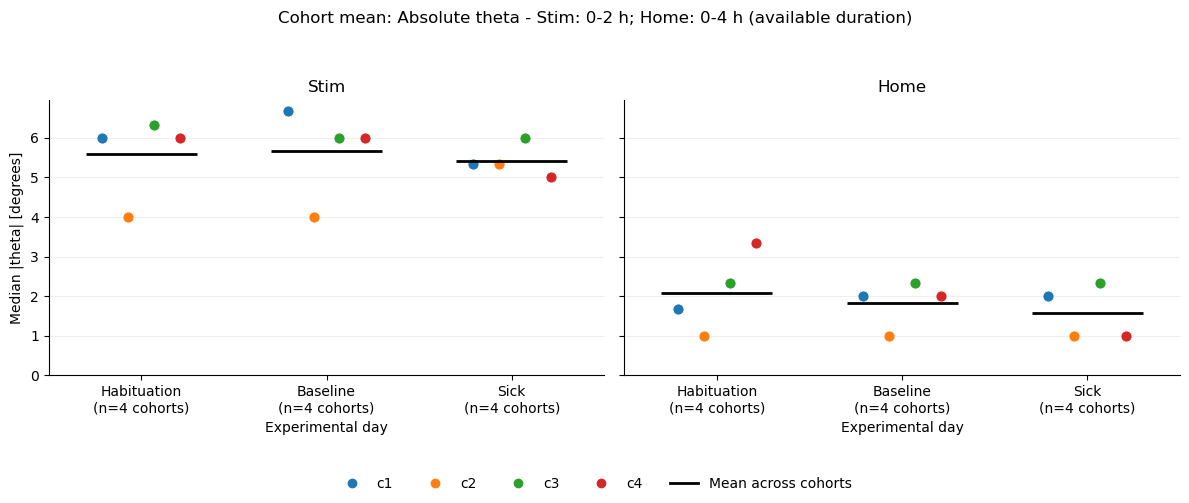

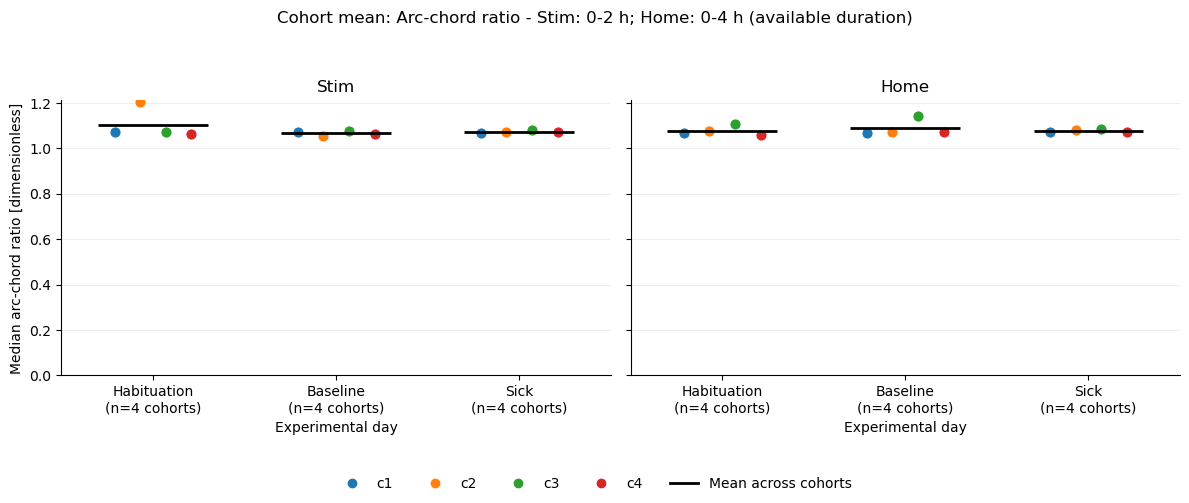

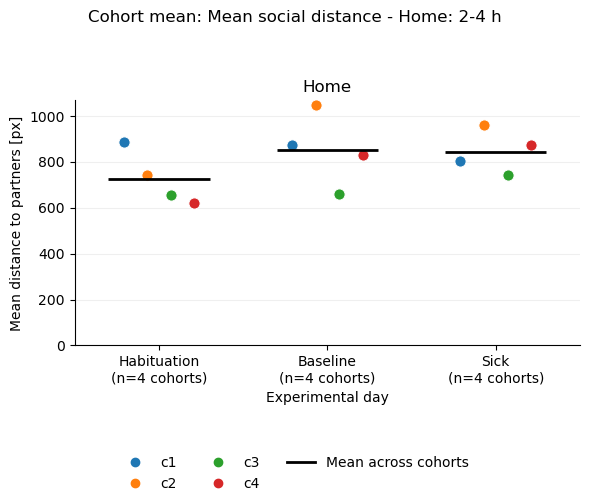

Saved 46 cohort-mean SVG plots to Z:\n2023_odor_related_behavior\2026_sick_behavior\plots\cohort_mean


In [246]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path
from textwrap import fill

COHORT_MEAN_PLOT_DIR = Path(r"Z:\n2023_odor_related_behavior\2026_sick_behavior\plots\cohort_mean")

COHORT_MEAN_PLOT_SPECS = [
    {'source': 'data_dict', 'metric': 'fraction_present', 'title': 'Fraction of time visible - Home and Stim: 0-2 h', 'ylabel': 'Fraction of recording time', 'conditions': ['home', 'stim'], 'fraction': True, 'signed': False, 'filename': 'fraction_present_scatter_by_cohort_home_stim_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'fraction_present', 'title': 'Fraction of time visible - Stim and Home: 0-2 h', 'ylabel': 'Fraction of recording time', 'conditions': ['stim', 'home'], 'fraction': True, 'signed': False, 'filename': 'fraction_present_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'median_speed', 'title': 'Median speed while moving - Stim and Home: 0-2 h', 'ylabel': 'Speed [px/frame]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'median_speed_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'median_acceleration', 'title': 'Median acceleration - Stim and Home: 0-2 h', 'ylabel': 'Acceleration [px/frame^2]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': True, 'filename': 'median_acceleration_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'total_distance', 'title': 'Total distance travelled - Stim and Home: 0-2 h', 'ylabel': 'Distance [px]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'total_distance_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'immobile_fraction', 'title': 'Immobility during visible time - Stim and Home: 0-2 h', 'ylabel': 'Fraction of visible time', 'conditions': ['stim', 'home'], 'fraction': True, 'signed': False, 'filename': 'immobile_fraction_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'median_immobile_bout_length', 'title': 'Median immobility bout duration - Stim and Home: 0-2 h', 'ylabel': 'Bout duration [frames]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'median_immobile_bout_length_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'sum_speedevents', 'title': 'Number of speed events - Stim and Home: 0-2 h', 'ylabel': 'Number of events', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'sum_speedevents_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'speedevents_per_visible_minute', 'title': 'Speed events per visible minute - Stim and Home: 0-2 h', 'ylabel': 'Events / visible minute', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'speedevents_per_visible_minute_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'median_posture_compactness', 'title': 'Median posture compactness - Stim and Home: 0-2 h', 'ylabel': 'Mean distance to body center [px]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'median_posture_compactness_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'median_body_length', 'title': 'Median body length - Stim and Home: 0-2 h', 'ylabel': 'Body length [px]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'median_body_length_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'number_of_trajectories', 'title': 'Number of trajectories - Stim and Home: 0-2 h', 'ylabel': 'Number of trajectories', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'number_of_trajectories_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'median_trajectory_length', 'title': 'Median trajectory duration - Stim and Home: 0-2 h', 'ylabel': 'Trajectory duration [frames]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'median_trajectory_length_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'face_inv_event_count', 'title': 'Face investigation: event count - Stim and Home: 0-2 h', 'ylabel': 'Number of events', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'face_inv_event_count_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'face_inv_events_per_pair_minute', 'title': 'Face investigation: event rate - Stim and Home: 0-2 h', 'ylabel': 'Events / pair-minute', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'face_inv_events_per_pair_minute_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'median_face_inv_bout_length', 'title': 'Face investigation: median bout duration - Stim and Home: 0-2 h', 'ylabel': 'Complete bout duration [frames]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'median_face_inv_bout_length_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'body_inv_event_count', 'title': 'Body investigation: event count - Stim and Home: 0-2 h', 'ylabel': 'Number of events', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'body_inv_event_count_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'body_inv_events_per_pair_minute', 'title': 'Body investigation: event rate - Stim and Home: 0-2 h', 'ylabel': 'Events / pair-minute', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'body_inv_events_per_pair_minute_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'median_body_inv_bout_length', 'title': 'Body investigation: median bout duration - Stim and Home: 0-2 h', 'ylabel': 'Complete bout duration [frames]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'median_body_inv_bout_length_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'anogenital_inv_event_count', 'title': 'Anogenital investigation: event count - Stim and Home: 0-2 h', 'ylabel': 'Number of events', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'anogenital_inv_event_count_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'anogenital_inv_events_per_pair_minute', 'title': 'Anogenital investigation: event rate - Stim and Home: 0-2 h', 'ylabel': 'Events / pair-minute', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'anogenital_inv_events_per_pair_minute_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict', 'metric': 'median_anogenital_inv_bout_length', 'title': 'Anogenital investigation: median bout duration - Stim and Home: 0-2 h', 'ylabel': 'Complete bout duration [frames]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'median_anogenital_inv_bout_length_scatter_stim_home_0_2h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'fraction_present', 'title': 'Fraction of time visible - Home: 2-4 h', 'ylabel': 'Fraction of recording time', 'conditions': ['home'], 'fraction': True, 'signed': False, 'filename': 'fraction_present_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'median_speed', 'title': 'Median speed while moving - Home: 2-4 h', 'ylabel': 'Speed [px/frame]', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'median_speed_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'median_acceleration', 'title': 'Median acceleration - Home: 2-4 h', 'ylabel': 'Acceleration [px/frame^2]', 'conditions': ['home'], 'fraction': False, 'signed': True, 'filename': 'median_acceleration_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'total_distance', 'title': 'Total distance travelled - Home: 2-4 h', 'ylabel': 'Distance [px]', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'total_distance_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'immobile_fraction', 'title': 'Immobility during visible time - Home: 2-4 h', 'ylabel': 'Fraction of visible time', 'conditions': ['home'], 'fraction': True, 'signed': False, 'filename': 'immobile_fraction_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'median_immobile_bout_length', 'title': 'Median immobility bout duration - Home: 2-4 h', 'ylabel': 'Bout duration [frames]', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'median_immobile_bout_length_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'sum_speedevents', 'title': 'Number of speed events - Home: 2-4 h', 'ylabel': 'Number of events', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'sum_speedevents_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'speedevents_per_visible_minute', 'title': 'Speed events per visible minute - Home: 2-4 h', 'ylabel': 'Events / visible minute', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'speedevents_per_visible_minute_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'median_posture_compactness', 'title': 'Median posture compactness - Home: 2-4 h', 'ylabel': 'Mean distance to body center [px]', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'median_posture_compactness_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'median_body_length', 'title': 'Median body length - Home: 2-4 h', 'ylabel': 'Body length [px]', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'median_body_length_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'number_of_trajectories', 'title': 'Number of trajectories - Home: 2-4 h', 'ylabel': 'Number of trajectories', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'number_of_trajectories_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'median_trajectory_length', 'title': 'Median trajectory duration - Home: 2-4 h', 'ylabel': 'Trajectory duration [frames]', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'median_trajectory_length_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'face_inv_event_count', 'title': 'Face investigation: event count - Home: 2-4 h', 'ylabel': 'Number of events', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'face_inv_event_count_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'face_inv_events_per_pair_minute', 'title': 'Face investigation: event rate - Home: 2-4 h', 'ylabel': 'Events / pair-minute', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'face_inv_events_per_pair_minute_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'median_face_inv_bout_length', 'title': 'Face investigation: median bout duration - Home: 2-4 h', 'ylabel': 'Complete bout duration [frames]', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'median_face_inv_bout_length_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'body_inv_event_count', 'title': 'Body investigation: event count - Home: 2-4 h', 'ylabel': 'Number of events', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'body_inv_event_count_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'body_inv_events_per_pair_minute', 'title': 'Body investigation: event rate - Home: 2-4 h', 'ylabel': 'Events / pair-minute', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'body_inv_events_per_pair_minute_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'median_body_inv_bout_length', 'title': 'Body investigation: median bout duration - Home: 2-4 h', 'ylabel': 'Complete bout duration [frames]', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'median_body_inv_bout_length_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'anogenital_inv_event_count', 'title': 'Anogenital investigation: event count - Home: 2-4 h', 'ylabel': 'Number of events', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'anogenital_inv_event_count_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'anogenital_inv_events_per_pair_minute', 'title': 'Anogenital investigation: event rate - Home: 2-4 h', 'ylabel': 'Events / pair-minute', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'anogenital_inv_events_per_pair_minute_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_home_second_2h', 'metric': 'median_anogenital_inv_bout_length', 'title': 'Anogenital investigation: median bout duration - Home: 2-4 h', 'ylabel': 'Complete bout duration [frames]', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'median_anogenital_inv_bout_length_scatter_home_2_4h_cohort_mean.svg'},
    {'source': 'data_dict_theta_arc', 'metric': 'median_absolute_theta', 'title': 'Absolute theta - Stim: 0-2 h; Home: 0-4 h (available duration)', 'ylabel': 'Median |theta| [degrees]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'median_absolute_theta_scatter_stim_0_2h_home_0_4h_cohort_mean.svg'},
    {'source': 'data_dict_theta_arc', 'metric': 'median_arc_chord_ratio', 'title': 'Arc-chord ratio - Stim: 0-2 h; Home: 0-4 h (available duration)', 'ylabel': 'Median arc-chord ratio [dimensionless]', 'conditions': ['stim', 'home'], 'fraction': False, 'signed': False, 'filename': 'median_arc_chord_ratio_scatter_stim_0_2h_home_0_4h_cohort_mean.svg'},
    {'source': 'data_dict_social_distance', 'metric': 'mean_social_distance', 'title': 'Mean social distance - Home: 2-4 h', 'ylabel': 'Mean distance to partners [px]', 'conditions': ['home'], 'fraction': False, 'signed': False, 'filename': 'mean_social_distance_scatter_home_2_4h_cohort_mean.svg'},
]

# Use the four existing result dictionaries; do not read or modify raw data.
required_sources = sorted({spec["source"] for spec in COHORT_MEAN_PLOT_SPECS})
missing_sources = [name for name in required_sources if name not in globals()]
if missing_sources:
    raise RuntimeError("Run the extraction cells first. Missing dictionaries: " + ", ".join(missing_sources))
cohort_mean_sources = {name: globals()[name] for name in required_sources}

rows = []
for source_name, source in cohort_mean_sources.items():
    metrics = sorted({spec["metric"] for spec in COHORT_MEAN_PLOT_SPECS if spec["source"] == source_name})
    for cohort, days in source.items():
        for day, conditions in days.items():
            for condition, mice in conditions.items():
                for metric in metrics:
                    values = [mouse.get(metric, np.nan) for mouse in mice.values()]
                    finite = np.array([value for value in values if value is not None and np.isfinite(value)], dtype=float)
                    rows.append({"source": source_name, "cohort": cohort, "day": day,
                                 "condition": condition, "metric": metric,
                                 "cohort_mean": np.mean(finite) if finite.size else np.nan,
                                 "n_mouse_slots": finite.size})
cohort_mean_summary = pd.DataFrame(rows, columns=[
    "source", "cohort", "day", "condition", "metric", "cohort_mean", "n_mouse_slots"])


def plot_cohort_means(summary, spec, cohorts):
    days = ["habituation", "baseline", "sick"]
    conditions = spec["conditions"]
    colors = {cohort: plt.get_cmap("tab10")(i % 10) for i, cohort in enumerate(cohorts)}
    offsets = dict(zip(cohorts, np.linspace(-0.21, 0.21, len(cohorts)) if len(cohorts) > 1 else [0.0]))
    selected = summary.loc[(summary["source"] == spec["source"]) & (summary["metric"] == spec["metric"])]
    fig, axes = plt.subplots(1, len(conditions), figsize=(6 * len(conditions), 5), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, condition in zip(axes, conditions):
        sample_sizes = []
        for day_idx, day in enumerate(days):
            points = selected.loc[(selected["day"] == day) & (selected["condition"] == condition)]
            values = []
            for row in points.itertuples(index=False):
                if not np.isfinite(row.cohort_mean):
                    continue
                ax.scatter(day_idx + offsets[row.cohort], row.cohort_mean,
                           color=colors[row.cohort], s=65, edgecolor="white", linewidth=0.7, zorder=3)
                values.append(row.cohort_mean)
            sample_sizes.append(len(values))
            if values:
                # Unweighted mean: each cohort contributes once.
                ax.hlines(np.mean(values), day_idx - 0.30, day_idx + 0.30,
                          color="black", linewidth=2, zorder=4)
        ax.set_title(condition.capitalize())
        ax.set_xticks(range(3), [f"{day.capitalize()}\n(n={count} cohorts)" for day, count in zip(days, sample_sizes)])
        ax.set_xlim(-0.5, 2.5)
        ax.set_xlabel("Experimental day")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        if not any(sample_sizes):
            ax.text(0.5, 0.5, "No valid cohort means", transform=ax.transAxes, ha="center")
    if spec["fraction"]:
        axes[0].set_ylim(0, 1)
    elif spec["signed"]:
        low, high = axes[0].get_ylim()
        limit = max(abs(low), abs(high), 0.01)
        axes[0].set_ylim(-limit, limit)
        for ax in axes:
            ax.axhline(0, color="grey", linewidth=0.8)
    else:
        axes[0].set_ylim(bottom=0)
    # Means of counts can be fractional; do not force integer tick locations.
    axes[0].set_ylabel(spec["ylabel"])
    handles = [Line2D([], [], marker="o", linestyle="", color=colors[c], label=c) for c in cohorts]
    handles.append(Line2D([], [], color="black", linewidth=2, label="Mean across cohorts"))
    fig.legend(handles=handles, loc="lower center", ncol=3 if len(conditions) == 1 else 5, frameon=False)
    fig.suptitle(fill("Cohort mean: " + spec["title"], width=60 if len(conditions) == 1 else 110))
    fig.tight_layout(rect=(0, 0.16 if len(conditions) == 1 else 0.10, 1, 0.93))
    return fig, axes


COHORT_MEAN_PLOT_DIR.mkdir(parents=True, exist_ok=True)
cohort_mean_saved_files = []
cohort_names = sorted({cohort for source in cohort_mean_sources.values() for cohort in source})
for spec in COHORT_MEAN_PLOT_SPECS:
    fig, axes = plot_cohort_means(cohort_mean_summary, spec, cohort_names)
    output_path = COHORT_MEAN_PLOT_DIR / spec["filename"]
    with mpl.rc_context({"svg.fonttype": "none"}):
        fig.savefig(output_path, format="svg", bbox_inches="tight")
    cohort_mean_saved_files.append(output_path)
    plt.show()
    plt.close(fig)
print(f"Saved {len(cohort_mean_saved_files)} cohort-mean SVG plots to {COHORT_MEAN_PLOT_DIR}")
